<a href="https://colab.research.google.com/github/nurulrezki-program/NOSQL-Bigdata/blob/main/LSTM%20VS%20TRANSFORMER%20BITCOIN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime

In [ ]:
df = pd.read_excel('DATA BITCOIN .xlsx', header=1)

In [ ]:
# 1. Membersihkan struktur data
# Menghapus baris kosong di awal
df = df.dropna(how='all')
df = df.reset_index(drop=True)

In [ ]:
# 2. Memastikan kolom Date menjadi datetime
# Cari kolom yang berisi tanggal
date_columns = df.columns[df.iloc[0].apply(lambda x: isinstance(x, (datetime, pd.Timestamp)) or
                                           (isinstance(x, str) and '20' in x and '-' in x))]
if len(date_columns) > 0:
    date_col = date_columns[0]
    df[date_col] = pd.to_datetime(df[date_col], errors='coerce')
    df = df.dropna(subset=[date_col])
else:
    for col in df.columns:
        if 'date' in str(col).lower():
            df[col] = pd.to_datetime(df[col], errors='coerce')
            df = df.dropna(subset=[col])
            break

In [ ]:
# Hapus kolom Unnamed
df = df.loc[:, ~df.columns.str.contains('Unnamed', case=False)]

print(df.head())

        Date      Open      High       Low     Close  Adj Close        Volume
0 2026-02-25  64051.16  66247.45  63949.71  65941.62   65941.62  4.230488e+10
1 2026-02-23  67668.43  67668.43  63924.44  64616.74   64616.74  5.095346e+10
2 2026-02-22  67998.83  68235.23  67185.60  67659.39   67659.39  1.789354e+10
3 2026-02-21  68000.25  68657.70  67533.07  68003.77   68003.77  1.835764e+10
4 2026-02-20  66958.58  68269.03  66452.48  68005.42   68005.42  4.750787e+10


In [ ]:
print(df.head())

        Date      Open      High       Low     Close  Adj Close        Volume
0 2026-02-25  64051.16  66247.45  63949.71  65941.62   65941.62  4.230488e+10
1 2026-02-23  67668.43  67668.43  63924.44  64616.74   64616.74  5.095346e+10
2 2026-02-22  67998.83  68235.23  67185.60  67659.39   67659.39  1.789354e+10
3 2026-02-21  68000.25  68657.70  67533.07  68003.77   68003.77  1.835764e+10
4 2026-02-20  66958.58  68269.03  66452.48  68005.42   68005.42  4.750787e+10


In [ ]:
print("\n" + "="*60)
print("DATA DATE DAN CLOSE DI AKHIR TAHUN 2018")
print("="*60)

# Filter data untuk tahun 2018
df_2018 = df[df['Date'].dt.year == 2018]

# Tampilkan 10 baris terakhir dari tahun 2018 untuk melihat akhir tahun
print("\n10 baris terakhir dari data tahun 2018:")
display(df_2018[['Date', 'Close']].tail(10))

# Atau, jika ingin lebih spesifik ke bulan-bulan akhir tahun
print("\nData Close Price dan Date untuk Desember 2018:")
df_dec_2018 = df_2018[df_2018['Date'].dt.month == 12]
display(df_dec_2018[['Date', 'Close']])


DATA DATE DAN CLOSE DI AKHIR TAHUN 2018

10 baris terakhir dari data tahun 2018:


,Date,Close
2967,2018-01-10,14973.3
2968,2018-01-09,14595.4
2969,2018-01-08,15170.1
2970,2018-01-07,16477.6
2971,2018-01-06,17527.0
2972,2018-01-05,17429.5
2973,2018-01-04,15599.2
2974,2018-01-03,15201.0
2975,2018-01-02,14982.1
2976,2018-01-01,13657.2



Data Close Price dan Date untuk Desember 2018:


,Date,Close
2612,2018-12-31,3742.70
2613,2018-12-30,3865.95
2614,2018-12-29,3820.41
2615,2018-12-28,3923.92
2616,2018-12-27,3654.83
2617,2018-12-26,3857.30
2618,2018-12-25,3815.49
2619,2018-12-24,4078.60
2620,2018-12-23,3998.98
2621,2018-12-22,4014.18


In [ ]:
# 3. Mengubah tipe data numeric ke float
numeric_columns = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
for col in numeric_columns:
    if col in df.columns:
        # Hapus koma jika ada dan konversi ke float
        df[col] = df[col].astype(str).str.replace(',', '').str.replace(' ', '')
        df[col] = pd.to_numeric(df[col], errors='coerce')

In [ ]:
# 4. Menghapus baris dengan nilai NaN yang kritis
df = df.dropna(subset=['Open', 'High', 'Low', 'Close', 'Volume'], how='any')

In [ ]:
# 5. Menghapus duplikat berdasarkan tanggal
if date_col in df.columns:
    df = df.drop_duplicates(subset=[date_col], keep='first')

In [ ]:
# 6. Mengurutkan data berdasarkan tanggal (ascending)
if date_col in df.columns:
    df = df.sort_values(by=[date_col], ascending=True).reset_index(drop=True)


In [ ]:
from scipy.stats import mstats

def winsorize_outliers_advanced(df):
    """
    Winsorizing outlier (membatasi nilai ekstrem, bukan menghapus)
    """
    df_clean = df.copy()

    print("=" * 70)
    print("WINSORIZING OUTLIER")
    print("=" * 70)

    # 1. Winsorize Volume (batasi 1% teratas)
    print("\n1. Volume:")
    print(f"   Sebelum - Min: {df_clean['Volume'].min():,.0f}, Max: {df_clean['Volume'].max():,.0f}")
    df_clean['Volume'] = mstats.winsorize(df_clean['Volume'], limits=[0, 0.01])
    print(f"   Sesudah - Min: {df_clean['Volume'].min():,.0f}, Max: {df_clean['Volume'].max():,.0f}")

    # 2. Winsorize Close Price (batasi 2% teratas karena kenaikan signifikan)
    print("\n2. Close Price:")
    print(f"   Sebelum - Min: {df_clean['Close'].min():,.2f}, Max: {df_clean['Close'].max():,.2f}")
    df_clean['Close'] = mstats.winsorize(df_clean['Close'], limits=[0, 0.02])
    print(f"   Sesudah - Min: {df_clean['Close'].min():,.2f}, Max: {df_clean['Close'].max():,.2f}")

    # 3. Winsorize kolom lainnya
    for col in ['Open', 'High', 'Low']:
        df_clean[col] = mstats.winsorize(df_clean[col], limits=[0, 0.02])

    return df_clean

# Gunakan fungsi winsorizing
df_winsorized = winsorize_outliers_advanced(df)

WINSORIZING OUTLIER

1. Volume:
   Sebelum - Min: 5,914,570, Max: 350,967,941,479
   Sesudah - Min: 5,914,570, Max: 95,911,605,728

2. Close Price:
   Sebelum - Min: 178.10, Max: 124,752.53
   Sesudah - Min: 178.10, Max: 111,723.21


In [ ]:
from scipy.stats import mstats

def winsorize_outliers_advanced(df):
    """
    Winsorizing outlier (membatasi nilai ekstrem, bukan menghapus)
    """
    df_clean = df.copy()

    print("=" * 70)
    print("WINSORIZING OUTLIER")
    print("=" * 70)

    # 1. Winsorize Volume (batasi 1% teratas)
    print("\n1. Volume:")
    print(f"   Sebelum - Min: {df_clean['Volume'].min():,.0f}, Max: {df_clean['Volume'].max():,.0f}")
    df_clean['Volume'] = mstats.winsorize(df_clean['Volume'], limits=[0, 0.01])
    print(f"   Sesudah - Min: {df_clean['Volume'].min():,.0f}, Max: {df_clean['Volume'].max():,.0f}")

    # 2. Winsorize Close Price (batasi 2% teratas karena kenaikan signifikan)
    print("\n2. Close Price:")
    print(f"   Sebelum - Min: {df_clean['Close'].min():,.2f}, Max: {df_clean['Close'].max():,.2f}")
    df_clean['Close'] = mstats.winsorize(df_clean['Close'], limits=[0, 0.02])
    print(f"   Sesudah - Min: {df_clean['Close'].min():,.2f}, Max: {df_clean['Close'].max():,.2f}")

    # 3. Winsorize kolom lainnya
    for col in ['Open', 'High', 'Low']:
        df_clean[col] = mstats.winsorize(df_clean[col], limits=[0, 0.02])

    return df_clean

# Gunakan fungsi winsorizing dan perbarui df
df = winsorize_outliers_advanced(df)

WINSORIZING OUTLIER

1. Volume:
   Sebelum - Min: 5,914,570, Max: 350,967,941,479
   Sesudah - Min: 5,914,570, Max: 95,911,605,728

2. Close Price:
   Sebelum - Min: 178.10, Max: 124,752.53
   Sesudah - Min: 178.10, Max: 111,723.21


In [ ]:
from statsmodels.tsa.stattools import adfuller

print("\n" + "="*80)
print("UJI STASIONER (Augmented Dickey-Fuller Test)")
print("="*80)

def adf_test(series, series_name):
    """Melakukan ADF test untuk uji stasioner"""
    result = adfuller(series.dropna(), autolag='AIC')
    print(f"\n{series_name}:")
    print(f"  ADF Statistic: {result[0]:.6f}")
    print(f"  p-value: {result[1]:.6f}")
    print(f"  Critical Values:")
    for key, value in result[4].items():
        print(f"    {key}: {value:.3f}")

    if result[1] <= 0.05:
        print(f"  -> Kesimpulan: Data STASIONER (tolak H0)")
        return True
    else:
        print(f"  -> Kesimpulan: Data TIDAK STASIONER (gagal tolak H0)")
        return False

# Uji stasioner pada Close Price
close_stationary = adf_test(df['Close'], 'CLOSE PRICE')

# Uji stasioner pada Volume
volume_stationary = adf_test(df['Volume'], 'VOLUME')

# Jika tidak stasioner, lakukan differencing
if not close_stationary:
    df['Close_diff'] = df['Close'].diff()
    print("\nDifferencing pada Close Price:")
    adf_test(df['Close_diff'].dropna(), 'CLOSE PRICE (After Differencing)')

if not volume_stationary:
    df['Volume_diff'] = df['Volume'].diff()
    print("\nDifferencing pada Volume:")
    adf_test(df['Volume_diff'].dropna(), 'VOLUME (After Differencing)')


UJI STASIONER (Augmented Dickey-Fuller Test)

CLOSE PRICE:
  ADF Statistic: -1.325905
  p-value: 0.617239
  Critical Values:
    1%: -3.432
    5%: -2.862
    10%: -2.567
  -> Kesimpulan: Data TIDAK STASIONER (gagal tolak H0)

VOLUME:
  ADF Statistic: -2.421022
  p-value: 0.135891
  Critical Values:
    1%: -3.432
    5%: -2.862
    10%: -2.567
  -> Kesimpulan: Data TIDAK STASIONER (gagal tolak H0)

Differencing pada Close Price:

CLOSE PRICE (After Differencing):
  ADF Statistic: -9.402251
  p-value: 0.000000
  Critical Values:
    1%: -3.432
    5%: -2.862
    10%: -2.567
  -> Kesimpulan: Data STASIONER (tolak H0)

Differencing pada Volume:

VOLUME (After Differencing):
  ADF Statistic: -16.974752
  p-value: 0.000000
  Critical Values:
    1%: -3.432
    5%: -2.862
    10%: -2.567
  -> Kesimpulan: Data STASIONER (tolak H0)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# ==================== FILTER TAHUN ====================

# TAHUN YANG DIMINTA: 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025
tahun_diminta = [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
df_filtered = df[df['Date'].dt.year.isin(tahun_diminta)].copy()

print(f"\nData setelah filter: {len(df_filtered)} data points")


Data setelah filter: 2922 data points


In [ ]:
# ==================== HITUNG STATISTIK PER TAHUN ====================

tahun_list = sorted(df_filtered['Date'].dt.year.unique())
print(f"\nTahun yang tersedia: {tahun_list}")

# Dictionary untuk menyimpan nilai ekstrim
harga_tertinggi_per_tahun = {}
harga_terendah_per_tahun = {}
volume_tertinggi_per_tahun = {}
volume_terendah_per_tahun = {}
tanggal_harga_tertinggi = {}
tanggal_harga_terendah = {}
tanggal_volume_tertinggi = {}
tanggal_volume_terendah = {}

for tahun in tahun_list:
    data_tahun = df_filtered[df_filtered['Date'].dt.year == tahun]
    if len(data_tahun) > 0:
        harga_tertinggi_per_tahun[tahun] = data_tahun['Close'].max()
        harga_terendah_per_tahun[tahun] = data_tahun['Close'].min()
        volume_tertinggi_per_tahun[tahun] = data_tahun['Volume'].max()
        volume_terendah_per_tahun[tahun] = data_tahun['Volume'].min()

        tanggal_harga_tertinggi[tahun] = data_tahun[data_tahun['Close'] == harga_tertinggi_per_tahun[tahun]]['Date'].iloc[0]
        tanggal_harga_terendah[tahun] = data_tahun[data_tahun['Close'] == harga_terendah_per_tahun[tahun]]['Date'].iloc[0]
        tanggal_volume_tertinggi[tahun] = data_tahun[data_tahun['Volume'] == volume_tertinggi_per_tahun[tahun]]['Date'].iloc[0]
        tanggal_volume_terendah[tahun] = data_tahun[data_tahun['Volume'] == volume_terendah_per_tahun[tahun]]['Date'].iloc[0]


Tahun yang tersedia: [np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]


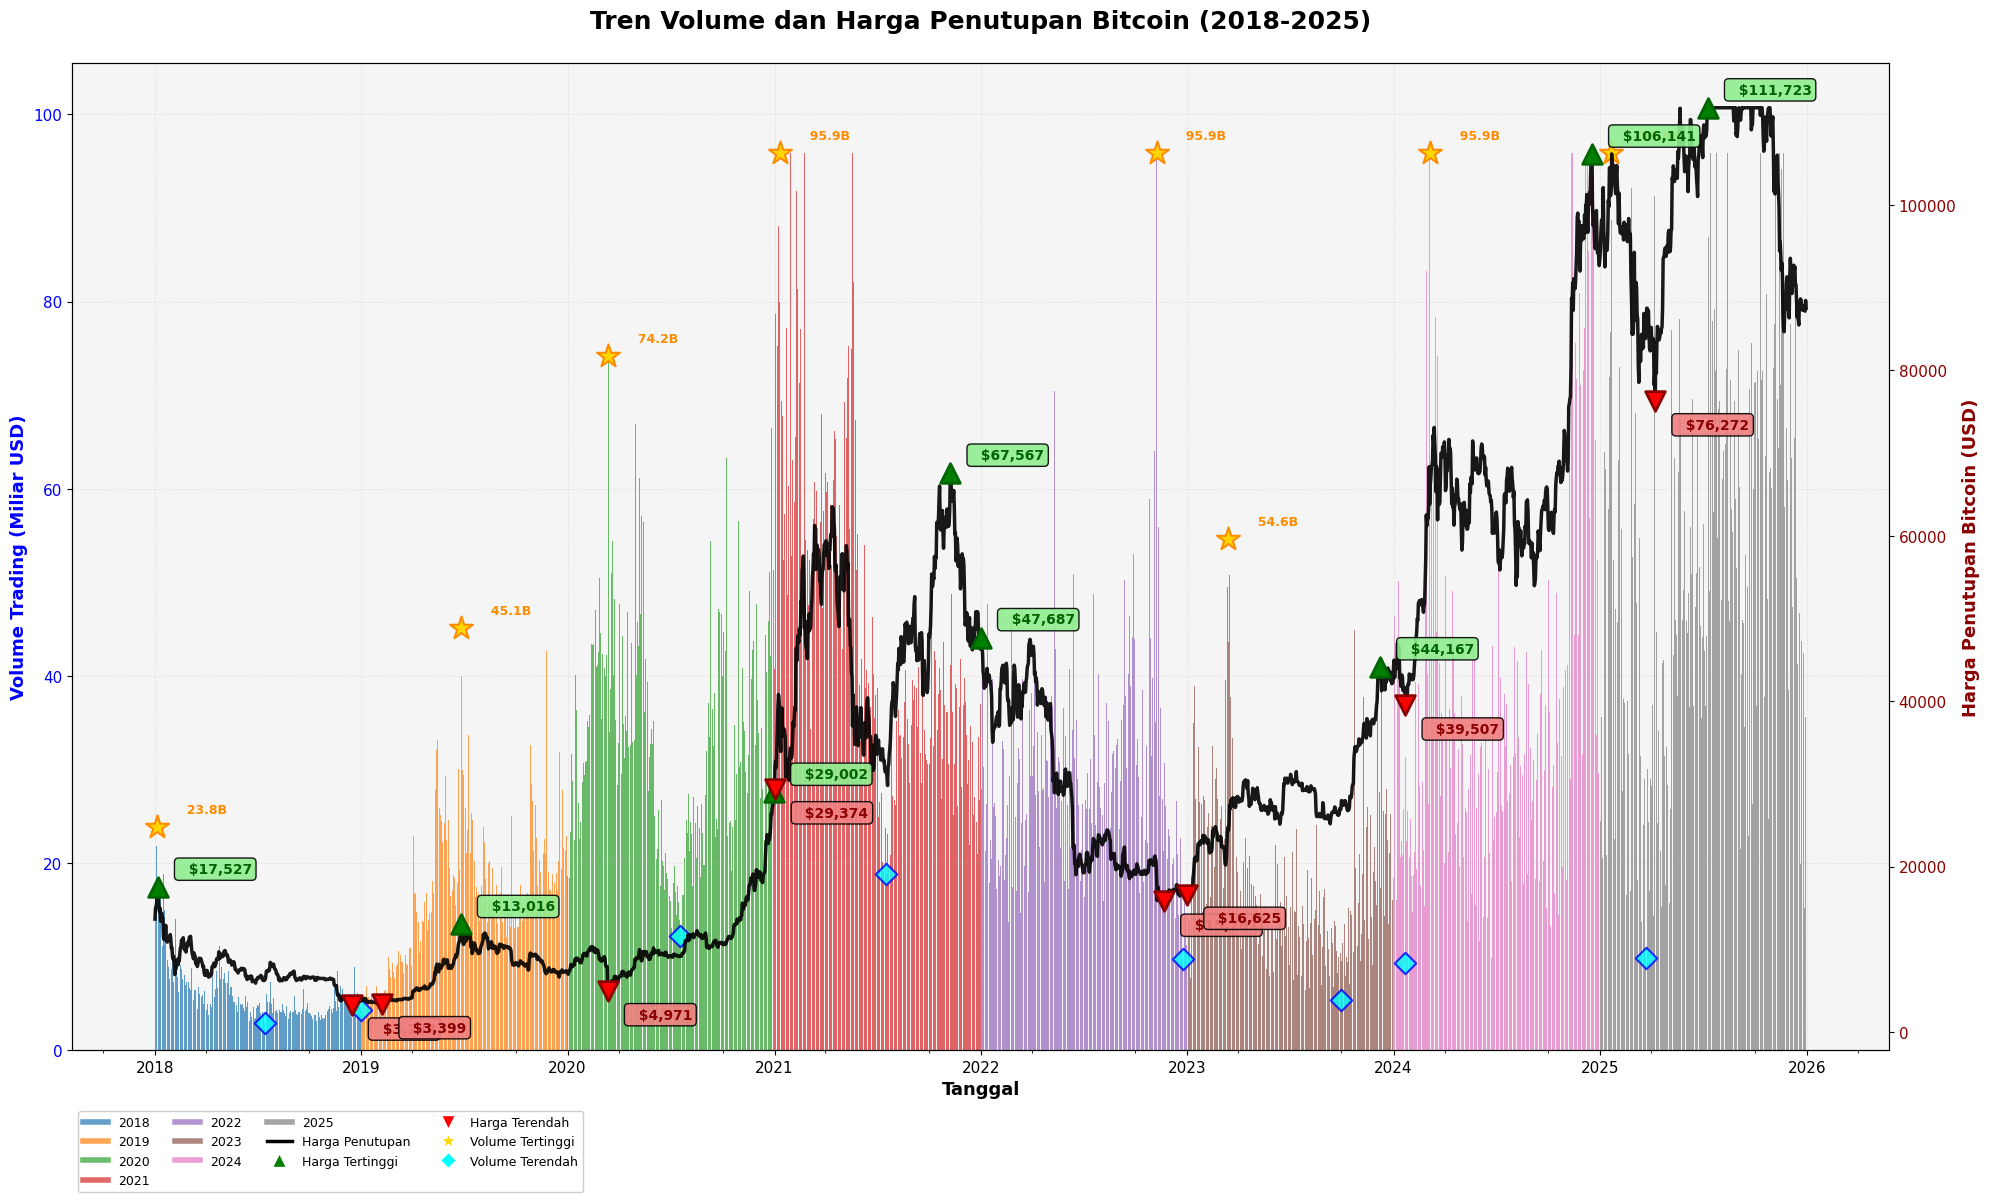

In [ ]:
# ==================== PLOT TREN VOLUME DAN HARGA ====================

fig, ax1 = plt.subplots(figsize=(20, 12))
fig.patch.set_facecolor('white')
ax1.set_facecolor('#f5f5f5')

# Warna untuk setiap tahun
warna_tahun = {
    2018: '#1f77b4',  # biru
    2019: '#ff7f0e',  # orange
    2020: '#2ca02c',  # hijau
    2021: '#d62728',  # merah
    2022: '#9467bd',  # ungu
    2023: '#8c564b',  # coklat
    2024: '#e377c2',  # pink
    2025: '#7f7f7f'   # abu-abu
}

# ===== PLOT VOLUME DI AXIS KIRI (bar chart) =====
for tahun in tahun_list:
    data_tahun = df_filtered[df_filtered['Date'].dt.year == tahun]
    ax1.bar(data_tahun['Date'], data_tahun['Volume'] / 1e9,
            color=warna_tahun.get(tahun, '#1f77b4'),
            alpha=0.7, width=0.8, label=f'Volume {tahun}')

ax1.set_ylabel('Volume Trading (Miliar USD)', fontsize=13, color='blue', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='blue', labelsize=11)
ax1.set_ylim(0, df_filtered['Volume'].max() / 1e9 * 1.1)

# ===== PLOT HARGA DI AXIS KANAN (line chart) =====
ax2 = ax1.twinx()
ax2.plot(df_filtered['Date'], df_filtered['Close'],
         color='black', linewidth=2.5, alpha=0.9, label='Harga Penutupan')

ax2.set_ylabel('Harga Penutupan Bitcoin (USD)', fontsize=13, color='darkred', fontweight='bold')
ax2.tick_params(axis='y', labelcolor='darkred', labelsize=11)

# ===== TAMBAHKAN PENANDA =====

# 1. Harga Tertinggi per Tahun (▲ hijau)
for tahun in tahun_list:
    if tahun in harga_tertinggi_per_tahun:
        harga = harga_tertinggi_per_tahun[tahun]
        tgl = tanggal_harga_tertinggi[tahun]
        ax2.scatter(tgl, harga, marker='^', s=200, c='green', edgecolor='darkgreen',
                   linewidth=2, zorder=10)
        ax2.annotate(f'  ${harga:,.0f}',
                    xy=(tgl, harga), xytext=(15, 10), textcoords='offset points',
                    fontsize=10, fontweight='bold', color='darkgreen',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='lightgreen', alpha=0.9))

# 2. Harga Terendah per Tahun (▼ merah)
for tahun in tahun_list:
    if tahun in harga_terendah_per_tahun:
        harga = harga_terendah_per_tahun[tahun]
        tgl = tanggal_harga_terendah[tahun]
        ax2.scatter(tgl, harga, marker='v', s=200, c='red', edgecolor='darkred',
                   linewidth=2, zorder=10)
        ax2.annotate(f'  ${harga:,.0f}',
                    xy=(tgl, harga), xytext=(15, -20), textcoords='offset points',
                    fontsize=10, fontweight='bold', color='darkred',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='lightcoral', alpha=0.9))

# 3. Volume Tertinggi per Tahun (★ emas) - di axis kiri
for tahun in tahun_list:
    if tahun in volume_tertinggi_per_tahun:
        volume = volume_tertinggi_per_tahun[tahun] / 1e9
        tgl = tanggal_volume_tertinggi[tahun]
        ax1.scatter(tgl, volume, marker='*', s=300, c='gold', edgecolor='darkorange',
                   linewidth=1.5, zorder=10)
        ax1.annotate(f'  {volume:.1f}B',
                    xy=(tgl, volume), xytext=(15, 10), textcoords='offset points',
                    fontsize=9, fontweight='bold', color='darkorange')

# 4. Volume Terendah per Tahun (◆ biru) - di axis kiri
for tahun in tahun_list:
    if tahun in volume_terendah_per_tahun:
        volume = volume_terendah_per_tahun[tahun] / 1e9
        tgl = tanggal_volume_terendah[tahun]
        ax1.scatter(tgl, volume, marker='D', s=120, c='cyan', edgecolor='blue',
                   linewidth=1.5, zorder=10, alpha=0.8)

# ===== FORMAT PLOT =====

# Sumbu X
ax1.set_xlabel('Tanggal', fontsize=13, fontweight='bold')
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax1.xaxis.set_minor_locator(mdates.MonthLocator(interval=6))
ax1.tick_params(axis='x', rotation=0, labelsize=11)

# Grid
ax1.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)

# Title
ax1.set_title('Tren Volume dan Harga Penutupan Bitcoin (2018-2025)',
             fontsize=18, fontweight='bold', pad=25)

# ===== LEGEND =====

# Legend untuk Volume
legend_vol = [plt.Line2D([0], [0], color=warna_tahun[t], lw=4, alpha=0.7) for t in tahun_list]
legend_vol_labels = [str(t) for t in tahun_list]

# Legend untuk Harga
legend_price = [plt.Line2D([0], [0], color='black', lw=2.5, label='Harga Penutupan')]

# Legend untuk Marker
legend_marker1 = [plt.Line2D([0], [0], marker='^', color='w', markerfacecolor='green',
                             markersize=10, label='Harga Tertinggi')]
legend_marker2 = [plt.Line2D([0], [0], marker='v', color='w', markerfacecolor='red',
                             markersize=10, label='Harga Terendah')]
legend_marker3 = [plt.Line2D([0], [0], marker='*', color='w', markerfacecolor='gold',
                             markersize=12, label='Volume Tertinggi')]
legend_marker4 = [plt.Line2D([0], [0], marker='D', color='w', markerfacecolor='cyan',
                             markersize=8, label='Volume Terendah')]

# Gabungkan semua legend
all_handles = legend_vol + legend_price + legend_marker1 + legend_marker2 + legend_marker3 + legend_marker4
all_labels = legend_vol_labels + ['Harga Penutupan', 'Harga Tertinggi', 'Harga Terendah', 'Volume Tertinggi', 'Volume Terendah']

# Tempatkan legend di dalam plot
ax1.legend(handles=all_handles, labels=all_labels,
          loc='lower left', ncol=4, fontsize=9, framealpha=0.95,
          bbox_to_anchor=(0, -0.15))

plt.tight_layout()
plt.subplots_adjust(bottom=0.12)
plt.savefig('bitcoin_trend_volume_price_2018_2025.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()

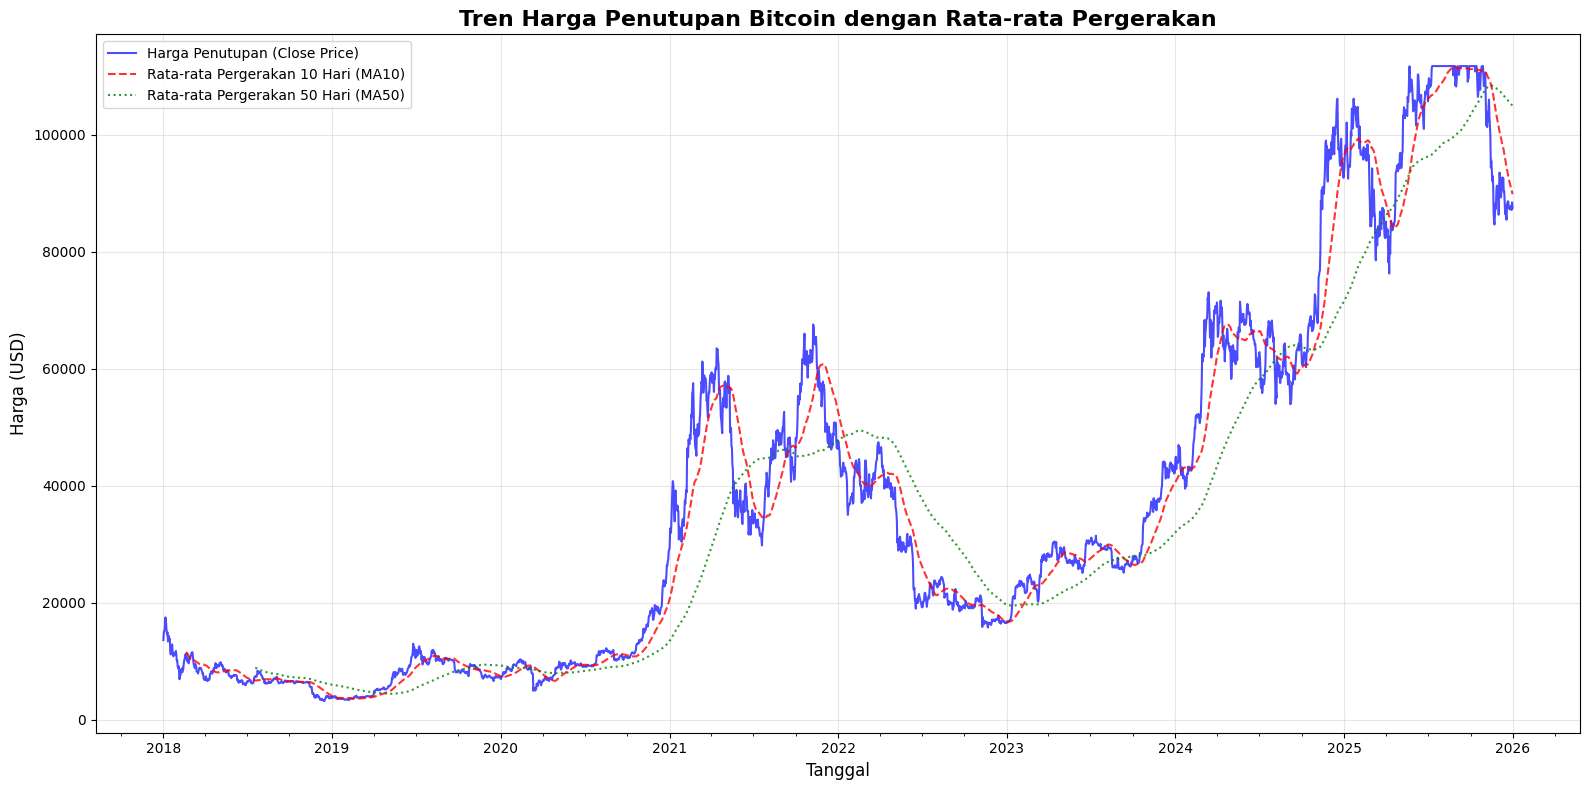

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Calculate moving averages
df_filtered['MA10'] = df_filtered['Close'].rolling(window=50).mean()
df_filtered['MA50'] = df_filtered['Close'].rolling(window=200).mean()

plt.figure(figsize=(16, 8))
plt.plot(df_filtered['Date'], df_filtered['Close'], label='Harga Penutupan (Close Price)', color='blue', alpha=0.7)
plt.plot(df_filtered['Date'], df_filtered['MA10'], label='Rata-rata Pergerakan 10 Hari (MA10)', color='red', linestyle='--', alpha=0.8)
plt.plot(df_filtered['Date'], df_filtered['MA50'], label='Rata-rata Pergerakan 50 Hari (MA50)', color='green', linestyle=':', alpha=0.8)

plt.title('Tren Harga Penutupan Bitcoin dengan Rata-rata Pergerakan', fontsize=16, fontweight='bold')
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Harga (USD)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)

# Format the x-axis to show years clearly
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().xaxis.set_minor_locator(mdates.MonthLocator(interval=3))

plt.tight_layout()
plt.savefig('bitcoin_price_with_moving_averages.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
print("\n" + "="*60)
print("STATISTIK DESKRIPTIF DATA BITCOIN")
print("="*60)
display(df_filtered.describe())


STATISTIK DESKRIPTIF DATA BITCOIN


,Date,Open,High,Low,Close,Adj Close,Volume,Close_diff,Volume_diff,MA10,MA50
count,2922,2922.000000,2922.000000,2922.000000,2922.000000,2922.000000,2.922000e+03,2922.000000,2.922000e+03,2873.000000,2723.000000
mean,2021-12-31 12:00:00,37107.817433,37855.577207,36326.940869,37131.705308,37273.879312,2.989521e+10,25.103501,7.424336e+06,36898.530736,35785.718246
min,2018-01-01 00:00:00,3236.270000,3275.380000,3191.300000,3236.760000,3236.760000,2.923670e+09,-8182.680000,-5.813170e+10,3661.443000,4454.763650
25%,2020-01-01 06:00:00,9472.795000,9653.322500,9264.670000,9475.870000,9475.870000,1.528955e+10,-289.230000,-3.630071e+09,9380.630800,9009.758800
50%,2021-12-31 12:00:00,27301.945000,27820.820000,26865.265000,27334.940000,27334.940000,2.609323e+10,0.000000,-9.440921e+07,27546.971200,28037.495550
75%,2023-12-31 18:00:00,57415.970000,58533.907500,55857.647500,57418.282500,57418.282500,3.975322e+10,325.320000,3.698054e+09,56433.462200,48435.908150
max,2025-12-31 00:00:00,111718.150000,113450.080000,110233.400000,111723.210000,124752.530000,9.591161e+10,8227.290000,6.646321e+10,111681.209800,108396.031150
std,NaN,31857.994751,32406.552044,31303.032795,31868.445295,32214.288846,2.028490e+10,1249.296955,1.088986e+10,31493.008379,29103.195781


In [ ]:
print("\n" + "="*60)
print("STATISTIK DESKRIPTIF MA10 DAN MA50")
print("="*60)
display(df_filtered[['MA10', 'MA50']].describe())


STATISTIK DESKRIPTIF MA10 DAN MA50


,MA10,MA50
count,2873.000000,2723.000000
mean,36898.530736,35785.718246
std,31493.008379,29103.195781
min,3661.443000,4454.763650
25%,9380.630800,9009.758800
50%,27546.971200,28037.495550
75%,56433.462200,48435.908150
max,111681.209800,108396.031150


In [ ]:
print("\n" + "="*60)
print("RATA-RATA MA10 DAN MA50 PER TAHUN")
print("="*60)

# Pastikan kolom 'Date' adalah datetime dan buat kolom 'Year'
df_filtered['Year'] = df_filtered['Date'].dt.year

# Group by year and calculate the mean of MA10 and MA50
yearly_ma_summary = df_filtered.groupby('Year')[['MA10', 'MA50']].mean().reset_index()

display(yearly_ma_summary.round(2))


RATA-RATA MA10 DAN MA50 PER TAHUN


,Year,MA10,MA50
0,2018,7453.44,7360.48
1,2019,7159.84,6555.39
2,2020,10123.56,9196.45
3,2021,45562.71,37536.37
4,2022,30427.80,37249.38
5,2023,27176.53,24599.47
6,2024,62241.67,53941.27
7,2025,101093.72,94372.45


In [ ]:
print("\n" + "="*60)
print("RATA-RATA KENAIKAN & PENURUNAN HARGA BITCOIN PER TAHUN (DARI CLOSE PRICE)")
print("="*60)

# Buat salinan DataFrame agar tidak mengubah df asli
df_price_change = df_filtered.copy()

# Pastikan kolom 'Date' adalah datetime dan buat kolom 'Year'
df_price_change['Year'] = df_price_change['Date'].dt.year

# Hitung persentase perubahan harian dari harga penutupan
df_price_change['daily_pct_change'] = df_price_change['Close'].pct_change() * 100

# Hapus NaN dari baris pertama setelah pct_change()
df_price_change = df_price_change.dropna(subset=['daily_pct_change'])

# Hitung rata-rata kenaikan dan penurunan per tahun
yearly_price_changes = df_price_change.groupby('Year')['daily_pct_change'].apply(lambda x: pd.Series({
    'Avg_Daily_Increase': x[x > 0].mean(),
    'Avg_Daily_Decrease': x[x < 0].mean()
})).unstack()

# Tampilkan hasil
display(yearly_price_changes.style.format({
    'Avg_Daily_Increase': '{:.2f}%',
    'Avg_Daily_Decrease': '{:.2f}%'
}))


RATA-RATA KENAIKAN & PENURUNAN HARGA BITCOIN PER TAHUN (DARI CLOSE PRICE)


,Avg_Daily_Increase,Avg_Daily_Decrease
Year,,
2018,2.65%,-3.31%
2019,2.44%,-2.17%
2020,2.46%,-2.12%
2021,3.26%,-2.98%
2022,2.16%,-2.31%
2023,1.82%,-1.25%
2024,2.20%,-1.86%
2025,1.58%,-1.62%


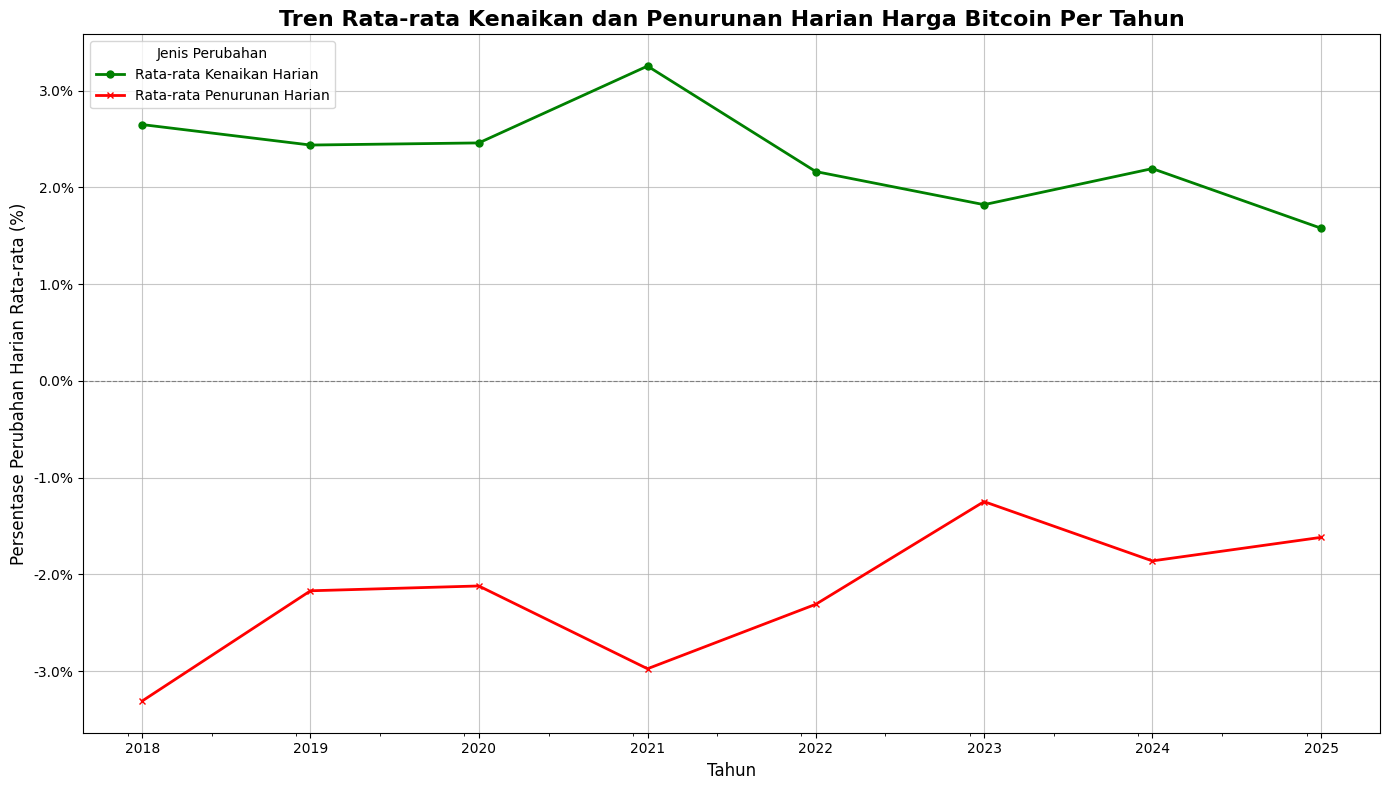

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

if 'yearly_price_changes' in globals():
    # Reset index to make 'Year' a column and convert to datetime for proper plotting
    df_plot = yearly_price_changes.reset_index()
    df_plot['Year_Date'] = pd.to_datetime(df_plot['Year'], format='%Y') # Convert Year to a date object

    plt.figure(figsize=(14, 8))

    plt.plot(df_plot['Year_Date'], df_plot['Avg_Daily_Increase'],
             label='Rata-rata Kenaikan Harian', color='green', linewidth=2, marker='o', markersize=5)
    plt.plot(df_plot['Year_Date'], df_plot['Avg_Daily_Decrease'],
             label='Rata-rata Penurunan Harian', color='red', linewidth=2, marker='x', markersize=5)

    plt.title('Tren Rata-rata Kenaikan dan Penurunan Harian Harga Bitcoin Per Tahun', fontsize=16, fontweight='bold')
    plt.xlabel('Tahun', fontsize=12)
    plt.ylabel('Persentase Perubahan Harian Rata-rata (%)', fontsize=12)
    plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    plt.legend(title='Jenis Perubahan', loc='upper left')
    plt.grid(True, alpha=0.7)

    # Format x-axis to show years clearly
    plt.gca().xaxis.set_major_locator(mdates.YearLocator())
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.gca().xaxis.set_minor_locator(mdates.MonthLocator(interval=6))

    # Format y-axis to show percentages
    plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.1f}%'))

    plt.tight_layout()
    plt.savefig('bitcoin_annual_price_change_trend_plot.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("DataFrame 'yearly_price_changes' tidak ditemukan. Jalankan sel sebelumnya untuk menghitungnya.")

MENGHITUNG REALIZED VOLATILTY

In [ ]:
def load_bitcoin_data(file_path):
    """Load data Bitcoin"""
    df = pd.read_excel(file_path, header=1)
    df = df.loc[:, ~df.columns.str.contains('Unnamed', case=False)]
    df['Date'] = pd.to_datetime(df['Date'])

    numeric_cols = ['Open', 'High', 'Low', 'Close', 'Volume']
    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    df = df.dropna().sort_values('Date').reset_index(drop=True)
    df = df[(df['Date'].dt.year >= 2018) & (df['Date'].dt.year <= 2025)]

    return df

df = load_bitcoin_data('DATA BITCOIN .xlsx')
print(f"Data loaded: {len(df)} rows")
print(f"Date range: {df['Date'].min()} to {df['Date'].max()}")


Data loaded: 2922 rows
Date range: 2018-01-01 00:00:00 to 2025-12-31 00:00:00


In [ ]:
def calculate_realized_volatility_squared_return(df):
    """
    Menghitung realized volatility menggunakan rumus:
    R_log = ln(F_P / V_P)
    RV_t = sqrt(n * sum((r_t-i)^2))

    Parameters:
    - df: DataFrame dengan kolom Date dan Close

    Returns:
    - DataFrame dengan kolom realized_volatility
    """
    df_rv = df.copy()

    # Rumus 3.1: Log Return
    # R_log = ln(F_P / V_P)
    # F_P = future value (harga akhir/close hari ini)
    # V_P = present value (harga awal/close kemarin)
    df_rv['log_return'] = np.log(df_rv['Close'] / df_rv['Close'].shift(1))

    # Squared daily return (komponen (r_t-i)^2)
    df_rv['realized_volatility_daily'] = df_rv['log_return'] ** 2

    # Annualized volatility (daily) - tetap menggunakan definisi standar untuk harian
    # Volatilitas tahunan = √(252 × kuadrat return harian)
    df_rv['realized_volatility_annual'] = np.sqrt(252 * df_rv['realized_volatility_daily'])

    # Rolling realized volatility (mean of squared returns for window - for intermediate step)
    df_rv['rv_5d'] = df_rv['realized_volatility_daily'].rolling(window=5).mean()
    df_rv['rv_20d'] = df_rv['realized_volatility_daily'].rolling(window=20).mean()

    # Rumus 3.2: Realized Volatility (menggunakan formula user untuk rolling windows)
    # RV_t = sqrt(n * sum((r_t-i)^2))
    # n = window size
    df_rv['rv_5d_correct'] = np.sqrt((1/5) * df_rv['realized_volatility_daily'].rolling(window=5).sum())
    df_rv['rv_20d_correct'] = np.sqrt((1/20) * df_rv['realized_volatility_daily'].rolling(window=20).sum())

    return df_rv

# Hitung realized volatility
df_rv = calculate_realized_volatility_squared_return(df)
df_rv = df_rv.dropna().reset_index(drop=True)

print("\n" + "="*60)
print("REALIZED VOLATILITY (SQUARED RETURN METHOD)")
print("="*60)
print(f"Total data: {len(df_rv)} days")
print(f"Log return range: {df_rv['log_return'].min():.6f} to {df_rv['log_return'].max():.6f}")
print(f"RV (daily) range: {df_rv['realized_volatility_daily'].min():.8f} to {df_rv['realized_volatility_daily'].max():.8f}")
print(f"RV (annualized) range: {df_rv['realized_volatility_annual'].min():.2%} to {df_rv['realized_volatility_annual'].max():.2%}")



REALIZED VOLATILITY (SQUARED RETURN METHOD)
Total data: 2902 days
Log return range: -0.464730 to 0.171820
RV (daily) range: 0.00000000 to 0.21597376
RV (annualized) range: 0.01% to 737.74%


In [ ]:
import numpy as np
from scipy.stats import mstats

# Buat salinan DataFrame untuk menyimpan hasil winsorization agar tidak mengubah data asli
df_rv_winsorized = df_rv.copy()

print("=" * 70)
print("WINSORIZING OUTLIER PADA LOG RETURN DAN REALIZED VOLATILITY")
print("=" * 70)

# 1. Winsorize Log Return
print(f"\nLog Return:")
print(f"   Sebelum - Min: {df_rv_winsorized['log_return'].min():.6f}, Max: {df_rv_winsorized['log_return'].max():.6f}")
# Batasi 1% terendah dan 1% tertinggi (limits=[0.01, 0.01])
df_rv_winsorized['log_return_winsorized'] = mstats.winsorize(df_rv_winsorized['log_return'], limits=[0.01, 0.01])
print(f"   Sesudah - Min: {df_rv_winsorized['log_return_winsorized'].min():.6f}, Max: {df_rv_winsorized['log_return_winsorized'].max():.6f}")

# 2. Winsorize Realized Volatility (daily)
print(f"\nRealized Volatility (Daily):")
print(f"   Sebelum - Min: {df_rv_winsorized['realized_volatility_daily'].min():.8f}, Max: {df_rv_winsorized['realized_volatility_daily'].max():.8f}")
# Batasi 1% teratas (limits=[0, 0.01])
df_rv_winsorized['realized_volatility_daily_winsorized'] = mstats.winsorize(df_rv_winsorized['realized_volatility_daily'], limits=[0, 0.01])
print(f"   Sesudah - Min: {df_rv_winsorized['realized_volatility_daily_winsorized'].min():.8f}, Max: {df_rv_winsorized['realized_volatility_daily_winsorized'].max():.8f}")

# 3. Winsorize 5-Day Rolling Realized Volatility
print(f"\n5-Day Rolling Realized Volatility:")
print(f"   Sebelum - Min: {df_rv_winsorized['rv_5d_correct'].min():.2%}, Max: {df_rv_winsorized['rv_5d_correct'].max():.2%}")
df_rv_winsorized['rv_5d_correct_winsorized'] = mstats.winsorize(df_rv_winsorized['rv_5d_correct'], limits=[0, 0.01])
print(f"   Sesudah - Min: {df_rv_winsorized['rv_5d_correct_winsorized'].min():.2%}, Max: {df_rv_winsorized['rv_5d_correct_winsorized'].max():.2%}")

# Calculate annualized version of the winsorized 5-day rolling volatility
df_rv_winsorized['rv_annualized_5d_winsorized'] = df_rv_winsorized['rv_5d_correct_winsorized'] * np.sqrt(252)

# 4. Winsorize 20-Day Rolling Realized Volatility
print(f"\n20-Day Rolling Realized Volatility:")
print(f"   Sebelum - Min: {df_rv_winsorized['rv_20d_correct'].min():.2%}, Max: {df_rv_winsorized['rv_20d_correct'].max():.2%}")
df_rv_winsorized['rv_20d_correct_winsorized'] = mstats.winsorize(df_rv_winsorized['rv_20d_correct'], limits=[0, 0.01])
print(f"   Sesudah - Min: {df_rv_winsorized['rv_20d_correct_winsorized'].min():.2%}, Max: {df_rv_winsorized['rv_20d_correct_winsorized'].max():.2%}")

# Calculate annualized version of the winsorized 20-day rolling volatility
df_rv_winsorized['rv_annualized_20d_winsorized'] = df_rv_winsorized['rv_20d_correct_winsorized'] * np.sqrt(252)

# Tampilkan statistik setelah winsorization
print("\nSTATISTIK SETELAH WINSORIZATION:")
print(f"  Mean Log Return (Winsorized): {df_rv_winsorized['log_return_winsorized'].mean():.6f}")
print(f"  Std Dev Log Return (Winsorized): {df_rv_winsorized['log_return_winsorized'].std():.6f}")
print(f"  Mean RV Daily (Winsorized): {df_rv_winsorized['realized_volatility_daily_winsorized'].mean():.8f}")
print(f"  Std Dev RV Daily (Winsorized): {df_rv_winsorized['realized_volatility_daily_winsorized'].std():.8f}")

print("\nBeberapa baris pertama DataFrame dengan kolom yang sudah di-winsorize:")
display(df_rv_winsorized[['Date', 'log_return', 'log_return_winsorized', 'realized_volatility_daily', 'realized_volatility_daily_winsorized', 'rv_5d_correct', 'rv_5d_correct_winsorized', 'rv_20d_correct', 'rv_20d_correct_winsorized', 'rv_annualized_5d_winsorized', 'rv_annualized_20d_winsorized']].head())

WINSORIZING OUTLIER PADA LOG RETURN DAN REALIZED VOLATILITY

Log Return:
   Sebelum - Min: -0.464730, Max: 0.171820
   Sesudah - Min: -0.102112, Max: 0.097275

Realized Volatility (Daily):
   Sebelum - Min: 0.00000000, Max: 0.21597376
   Sesudah - Min: 0.00000000, Max: 0.01201318

5-Day Rolling Realized Volatility:
   Sebelum - Min: 0.20%, Max: 21.90%
   Sesudah - Min: 0.20%, Max: 8.47%

20-Day Rolling Realized Volatility:
   Sebelum - Min: 0.57%, Max: 12.18%
   Sesudah - Min: 0.57%, Max: 7.55%

STATISTIK SETELAH WINSORIZATION:
  Mean Log Return (Winsorized): 0.000804
  Std Dev Log Return (Winsorized): 0.031350
  Mean RV Daily (Winsorized): 0.00101206
  Std Dev RV Daily (Winsorized): 0.00208917

Beberapa baris pertama DataFrame dengan kolom yang sudah di-winsorize:


,Date,log_return,log_return_winsorized,realized_volatility_daily,realized_volatility_daily_winsorized,rv_5d_correct,rv_5d_correct_winsorized,rv_20d_correct,rv_20d_correct_winsorized,rv_annualized_5d_winsorized,rv_annualized_20d_winsorized
0,2018-01-21,-0.106152,-0.102112,0.011268,0.011268,0.069112,0.069112,0.073826,0.073826,1.097117,1.171954
1,2018-01-22,-0.059374,-0.059374,0.003525,0.003525,0.073073,0.073073,0.072097,0.072097,1.160006,1.144499
2,2018-01-23,-0.005780,-0.005780,0.000033,0.000033,0.072241,0.072241,0.072035,0.072035,1.146787,1.143524
3,2018-01-24,0.044186,0.044186,0.001952,0.001952,0.074719,0.074719,0.072479,0.072479,1.186120,1.150575
4,2018-01-25,-0.008842,-0.008842,0.000078,0.000078,0.058065,0.058065,0.068130,0.068130,0.921747,1.081535


In [ ]:
def print_rv_statistics(df_rv):
    """Menampilkan statistik realized volatility"""
    print("\n" + "="*60)
    print("STATISTIK REALIZED VOLATILITY (SQUARED RETURN)")
    print("="*60)

    # Calculate annualized rolling volatility if not already present
    # rv_5d_correct and rv_20d_correct are already sqrt of avg squared returns
    # To annualize, multiply by sqrt(252)
    if 'rv_annualized_5d' not in df_rv.columns:
        df_rv['rv_annualized_5d'] = df_rv['rv_5d_correct'] * np.sqrt(252)
    if 'rv_annualized_20d' not in df_rv.columns:
        df_rv['rv_annualized_20d'] = df_rv['rv_20d_correct'] * np.sqrt(252)

    print("\nDaily Realized Volatility (RV_t = R_t²):")
    print(f"  Mean: {df_rv['realized_volatility_daily'].mean():.8f}")
    print(f"  Median: {df_rv['realized_volatility_daily'].median():.8f}")
    print(f"  Std Dev: {df_rv['realized_volatility_daily'].std():.8f}")
    print(f"  Min: {df_rv['realized_volatility_daily'].min():.8f}")
    print(f"  Max: {df_rv['realized_volatility_daily'].max():.8f}")

    print("\nAnnualized Realized Volatility (√252 × RV):")
    print(f"  Mean: {df_rv['realized_volatility_annual'].mean():.2%}")
    print(f"  Median: {df_rv['realized_volatility_annual'].median():.2%}")
    print(f"  Std Dev: {df_rv['realized_volatility_annual'].std():.2%}")
    print(f"  Min: {df_rv['realized_volatility_annual'].min():.2%}")
    print(f"  Max: {df_rv['realized_volatility_annual'].max():.2%}")

    print("\n5-Day Rolling Annualized Volatility:")
    print(f"  Mean: {df_rv['rv_annualized_5d'].mean():.2%}")
    print(f"  Median: {df_rv['rv_annualized_5d'].median():.2%}")
    print(f"  Std Dev: {df_rv['rv_annualized_5d'].std():.2%}")

    print("\n20-Day Rolling Annualized Volatility:")
    print(f"  Mean: {df_rv['rv_annualized_20d'].mean():.2%}")
    print(f"  Median: {df_rv['rv_annualized_20d'].median():.2%}")
    print(f"  Std Dev: {df_rv['rv_annualized_20d'].std():.2%}")

    # Per tahun
    print("\nAnnualized Realized Volatility by Year:")
    df_rv['Year'] = df_rv['Date'].dt.year
    yearly_stats = df_rv.groupby('Year')['realized_volatility_annual'].agg(['mean', 'std', 'min', 'max'])

    for year, row in yearly_stats.iterrows():
        print(f"  {year}: Mean={row['mean']:.2%}, Std={row['std']:.2%}, Range=[{row['min']:.2%}, {row['max']:.2%}]")

print_rv_statistics(df_rv)


STATISTIK REALIZED VOLATILITY (SQUARED RETURN)

Daily Realized Volatility (RV_t = R_t²):
  Mean: 0.00114716
  Median: 0.00020470
  Std Dev: 0.00473544
  Min: 0.00000000
  Max: 0.21597376

Annualized Realized Volatility (√252 × RV):
  Mean: 35.59%
  Median: 22.71%
  Std Dev: 40.31%
  Min: 0.01%
  Max: 737.74%

5-Day Rolling Annualized Volatility:
  Mean: 45.11%
  Median: 38.71%
  Std Dev: 29.40%

20-Day Rolling Annualized Volatility:
  Mean: 48.93%
  Median: 44.31%
  Std Dev: 23.29%

Annualized Realized Volatility by Year:
  2018: Mean=45.33%, Std=46.43%, Range=[0.10%, 276.19%]
  2019: Mean=36.53%, Std=42.61%, Range=[0.38%, 254.06%]
  2020: Mean=36.82%, Std=52.19%, Range=[0.07%, 737.74%]
  2021: Mean=49.44%, Std=44.81%, Range=[0.03%, 272.76%]
  2022: Mean=35.77%, Std=39.80%, Range=[0.41%, 276.30%]
  2023: Mean=24.22%, Std=26.87%, Range=[0.01%, 155.77%]
  2024: Mean=32.18%, Std=30.37%, Range=[0.02%, 181.95%]
  2025: Mean=24.94%, Std=24.26%, Range=[0.03%, 144.80%]


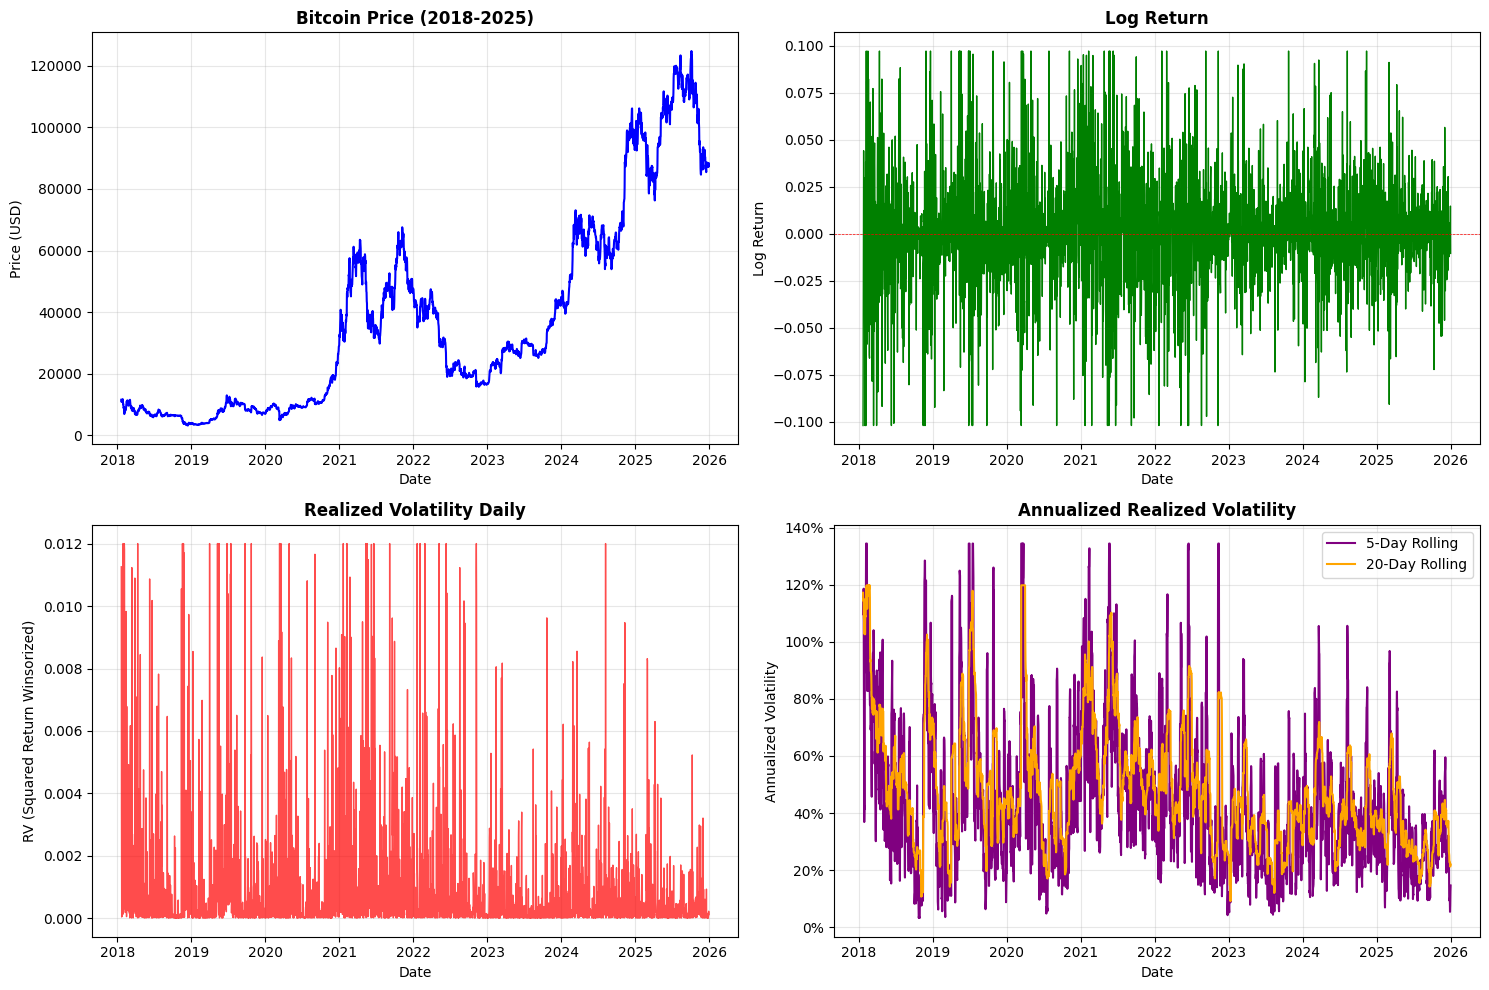


Plot saved to: realized_volatility_squared_return_winsorized.png


In [ ]:
def plot_squared_return_volatility(df_rv_winsorized_data, save_path='realized_volatility_squared_return_winsorized.png'):
    """
    Plot realized volatility dengan metode kuadrat return, menggunakan data yang sudah di-winsorize.
    """
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # 1. Bitcoin Price (tetap menggunakan Close asli)
    axes[0, 0].plot(df_rv_winsorized_data['Date'], df_rv_winsorized_data['Close'], color='blue', linewidth=1.5)
    axes[0, 0].set_title('Bitcoin Price (2018-2025)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xlabel('Date')
    axes[0, 0].set_ylabel('Price (USD)')
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    # 2. Log Return (R_log = ln(F_P/V_P)) - Winsorized
    axes[0, 1].plot(df_rv_winsorized_data['Date'], df_rv_winsorized_data['log_return_winsorized'], color='green', linewidth=1)
    axes[0, 1].axhline(y=0, color='red', linestyle='--', linewidth=0.5)
    axes[0, 1].set_title('Log Return', fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel('Date')
    axes[0, 1].set_ylabel('Log Return')
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    # 3. Realized Volatility (RV_t = R_t²) - Daily Winsorized
    axes[1, 0].plot(df_rv_winsorized_data['Date'], df_rv_winsorized_data['realized_volatility_daily_winsorized'],
                    color='red', linewidth=1, alpha=0.7)
    axes[1, 0].set_title('Realized Volatility Daily', fontsize=12, fontweight='bold')
    axes[1, 0].set_xlabel('Date')
    axes[1, 0].set_ylabel('RV (Squared Return Winsorized)')
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    # 4. Annualized Realized Volatility (5-day & 20-day rolling) - Winsorized
    axes[1, 1].plot(df_rv_winsorized_data['Date'], df_rv_winsorized_data['rv_annualized_5d_winsorized'],
                    label='5-Day Rolling', color='purple', linewidth=1.5)
    axes[1, 1].plot(df_rv_winsorized_data['Date'], df_rv_winsorized_data['rv_annualized_20d_winsorized'],
                    label='20-Day Rolling', color='orange', linewidth=1.5)
    axes[1, 1].set_title('Annualized Realized Volatility', fontsize=12, fontweight='bold')
    axes[1, 1].set_xlabel('Date')
    axes[1, 1].set_ylabel('Annualized Volatility')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    axes[1, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

    print(f"\nPlot saved to: {save_path}")

# Plot menggunakan df_rv_winsorized
plot_squared_return_volatility(df_rv_winsorized)

In [ ]:
# Simpan data
output_df = df_rv[['Date', 'Close', 'log_return', 'realized_volatility_daily',
                   'realized_volatility_annual', 'rv_5d', 'rv_20d',
                   'rv_annualized_5d', 'rv_annualized_20d']]

output_df.to_excel('bitcoin_realized_volatility_squared_return.xlsx', index=False)
output_df.to_csv('bitcoin_realized_volatility_squared_return.csv', index=False)

print("\n" + "="*60)
print("DATA REALIZED VOLATILITY SAVED:")
print("="*60)
print("- Excel: bitcoin_realized_volatility_squared_return.xlsx")
print("- CSV: bitcoin_realized_volatility_squared_return.csv")
print("- Plot: realized_volatility_squared_return.png")
print("- Comparison Plot: volatility_method_comparison.png")



DATA REALIZED VOLATILITY SAVED:
- Excel: bitcoin_realized_volatility_squared_return.xlsx
- CSV: bitcoin_realized_volatility_squared_return.csv
- Plot: realized_volatility_squared_return.png
- Comparison Plot: volatility_method_comparison.png


In [ ]:
print("\n" + "="*60)
print("SAMPLE DATA (First 10 rows):")
print("="*60)
# Menggunakan df_rv_winsorized yang sudah ada dan relevan
print(df_rv_winsorized[['Date', 'Close', 'log_return_winsorized', 'realized_volatility_daily_winsorized',
                 'rv_annualized_5d_winsorized', 'rv_annualized_20d_winsorized']].head(10).to_string())


SAMPLE DATA (First 10 rows):
        Date    Close  log_return_winsorized  realized_volatility_daily_winsorized  rv_annualized_5d_winsorized  rv_annualized_20d_winsorized
0 2018-01-21  11600.1              -0.102112                              0.011268                     1.097117                      1.171954
1 2018-01-22  10931.4              -0.059374                              0.003525                     1.160006                      1.144499
2 2018-01-23  10868.4              -0.005780                              0.000033                     1.146787                      1.143524
3 2018-01-24  11359.4               0.044186                              0.001952                     1.186120                      1.150575
4 2018-01-25  11259.4              -0.008842                              0.000078                     0.921747                      1.081535
5 2018-01-26  11171.4              -0.007846                              0.000062                     0.533671       

In [ ]:
# Load data yang sudah dihitung
df = pd.read_excel('bitcoin_realized_volatility_squared_return.xlsx')
df['Date'] = pd.to_datetime(df['Date'])


In [ ]:
# Analisis volatilitas tahun 2020
df_2020 = df_rv[(df_rv['Date'].dt.year == 2020)]

print("="*60)
print("ANALISIS VOLATILITAS TAHUN 2020")
print("="*60)

print(f"\nStatistik Volatilitas 2020:")
print(f"  Mean Volatility: {df_2020['rv_annualized_20d'].mean():.2%}")
print(f"  Max Volatility: {df_2020['rv_annualized_20d'].max():.2%}")
print(f"  Min Volatility: {df_2020['rv_annualized_20d'].min():.2%}")
print(f"  Std Dev: {df_2020['rv_annualized_20d'].std():.2%}")

ANALISIS VOLATILITAS TAHUN 2020

Statistik Volatilitas 2020:
  Mean Volatility: 52.85%
  Max Volatility: 193.38%
  Min Volatility: 17.04%
  Std Dev: 35.06%


In [ ]:
# Cari puncak volatilitas
peak_date = df_2020.loc[df_2020['rv_annualized_20d'].idxmax(), 'Date']
peak_vol = df_2020['rv_annualized_20d'].max()

print(f"\nPuncak Volatilitas Tertinggi:")
print(f"  Tanggal: {peak_date.strftime('%d %B %Y')}")
print(f"  Volatilitas: {peak_vol:.2%}")

# Perbandingan dengan tahun lain
print("\n" + "="*60)
print("PERBANDINGAN VOLATILITAS PER TAHUN")
print("="*60)

for year in [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]:
    year_data = df_rv[df_rv['Date'].dt.year == year] # Menggunakan df_rv di sini
    if len(year_data) > 0:
        print(f"\n{year}:")
        print(f"  Mean: {year_data['rv_annualized_20d'].mean():.2%}")
        print(f"  Max: {year_data['rv_annualized_20d'].max():.2%}")
        print(f"  Min: {year_data['rv_annualized_20d'].min():.2%}")


Puncak Volatilitas Tertinggi:
  Tanggal: 31 March 2020
  Volatilitas: 193.38%

PERBANDINGAN VOLATILITAS PER TAHUN

2018:
  Mean: 60.99%
  Max: 126.80%
  Min: 10.71%

2019:
  Mean: 52.60%
  Max: 117.89%
  Min: 14.16%

2020:
  Mean: 52.85%
  Max: 193.38%
  Min: 17.04%

2021:
  Mean: 64.74%
  Max: 110.22%
  Min: 36.30%

2022:
  Mean: 50.74%
  Max: 91.52%
  Min: 17.10%

2023:
  Mean: 34.27%
  Max: 65.80%
  Min: 9.11%

2024:
  Mean: 42.52%
  Max: 71.94%
  Min: 19.61%

2025:
  Mean: 33.38%
  Max: 67.90%
  Min: 14.22%


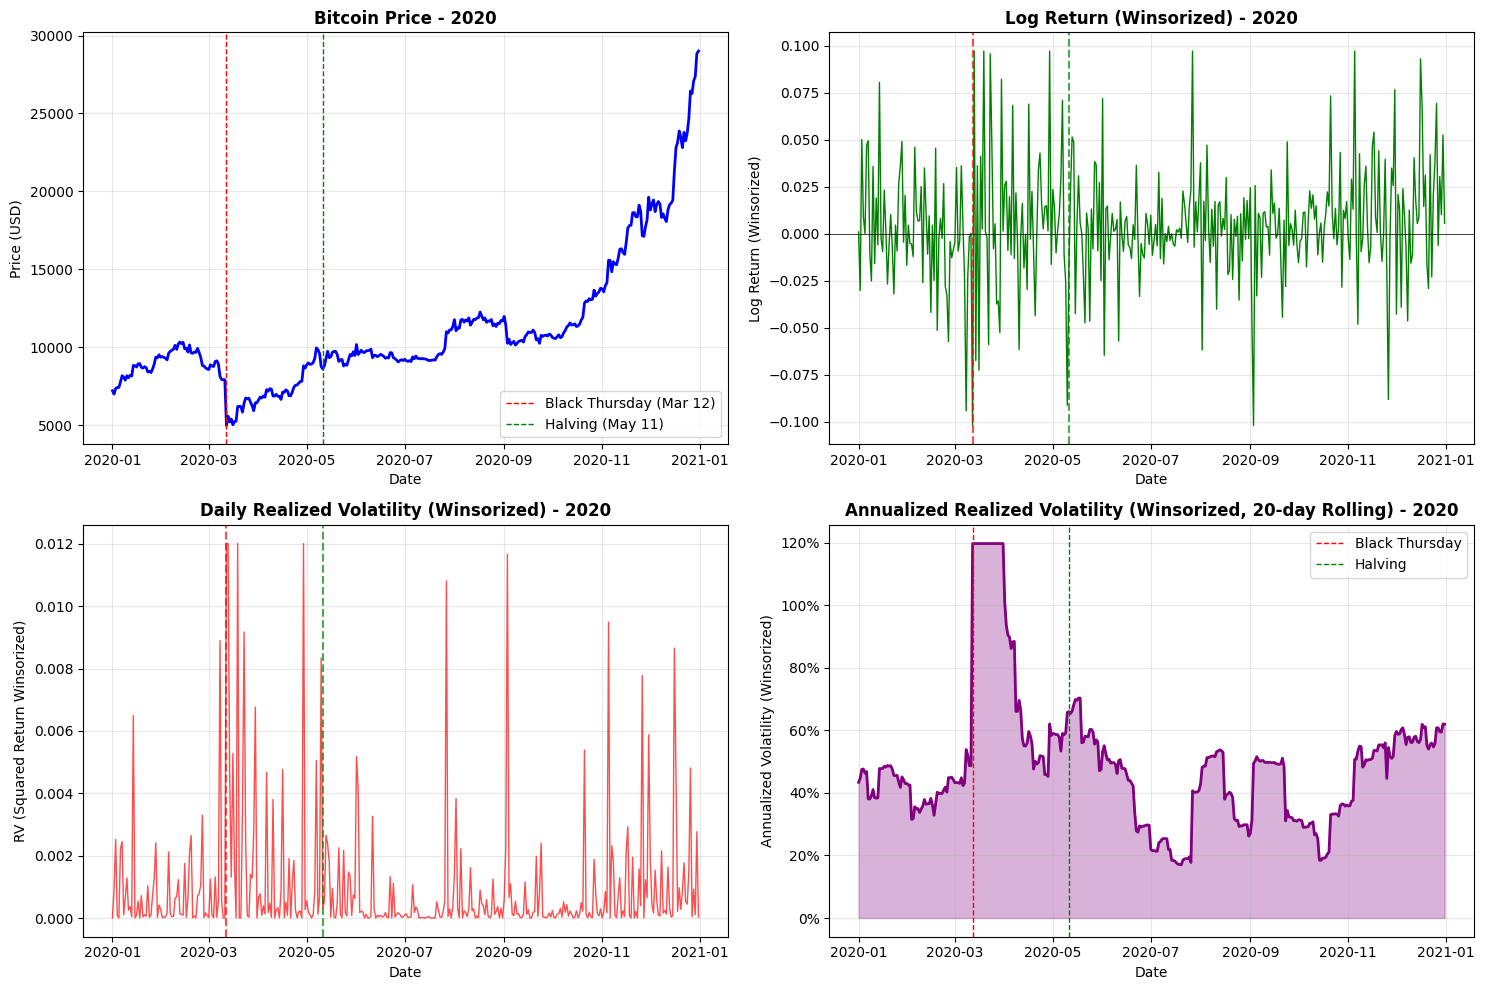

In [ ]:
df_2020_winsorized = df_rv_winsorized[df_rv_winsorized['Date'].dt.year == 2020]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Harga Bitcoin 2020 (menggunakan Close asli)
ax1 = axes[0, 0]
ax1.plot(df_2020_winsorized['Date'], df_2020_winsorized['Close'], color='blue', linewidth=2)
ax1.axvline(pd.to_datetime('2020-03-12'), color='red', linestyle='--',
            linewidth=1, label='Black Thursday (Mar 12)')
ax1.axvline(pd.to_datetime('2020-05-11'), color='green', linestyle='--',
            linewidth=1, label='Halving (May 11)')
ax1.set_title('Bitcoin Price - 2020', fontsize=12, fontweight='bold')
ax1.set_xlabel('Date')
ax1.set_ylabel('Price (USD)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Log Return 2020 (Winsorized)
ax2 = axes[0, 1]
ax2.plot(df_2020_winsorized['Date'], df_2020_winsorized['log_return_winsorized'], color='green', linewidth=1)
ax2.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax2.axvline(pd.to_datetime('2020-03-12'), color='red', linestyle='--', alpha=0.7)
ax2.axvline(pd.to_datetime('2020-05-11'), color='green', linestyle='--', alpha=0.7)
ax2.set_title('Log Return (Winsorized) - 2020', fontsize=12, fontweight='bold')
ax2.set_xlabel('Date')
ax2.set_ylabel('Log Return (Winsorized)')
ax2.grid(True, alpha=0.3)

# 3. Daily Realized Volatility 2020 (Winsorized)
ax3 = axes[1, 0]
ax3.plot(df_2020_winsorized['Date'], df_2020_winsorized['realized_volatility_daily_winsorized'],
         color='red', linewidth=1, alpha=0.7)
ax3.axvline(pd.to_datetime('2020-03-12'), color='red', linestyle='--', alpha=0.7)
ax3.axvline(pd.to_datetime('2020-05-11'), color='green', linestyle='--', alpha=0.7)
ax3.set_title('Daily Realized Volatility (Winsorized) - 2020', fontsize=12, fontweight='bold')
ax3.set_xlabel('Date')
ax3.set_ylabel('RV (Squared Return Winsorized)')
ax3.grid(True, alpha=0.3)

# 4. Annualized Realized Volatility 2020 (Winsorized)
ax4 = axes[1, 1]
ax4.plot(df_2020_winsorized['Date'], df_2020_winsorized['rv_annualized_20d_winsorized'],
         color='purple', linewidth=2)
ax4.fill_between(df_2020_winsorized['Date'], 0, df_2020_winsorized['rv_annualized_20d_winsorized'],
                  alpha=0.3, color='purple')
ax4.axvline(pd.to_datetime('2020-03-12'), color='red', linestyle='--',
            linewidth=1, label='Black Thursday')
ax4.axvline(pd.to_datetime('2020-05-11'), color='green', linestyle='--',
            linewidth=1, label='Halving')
ax4.set_title('Annualized Realized Volatility (Winsorized, 20-day Rolling) - 2020',
              fontsize=12, fontweight='bold')
ax4.set_xlabel('Date')
ax4.set_ylabel('Annualized Volatility (Winsorized)')
ax4.legend()
ax4.grid(True, alpha=0.3)
ax4.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

plt.tight_layout()
plt.savefig('volatility_2020_analysis_winsorized.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
print("\n" + "="*60)
print("ANALISIS PERISTIWA PENTING 2020")
print("="*60)

# Black Thursday (Maret 2020)
mar_data = df_rv[(df_rv['Date'] >= '2020-03-01') & (df_rv['Date'] <= '2020-03-31')]
mar_peak = mar_data.loc[mar_data['rv_annualized_20d'].idxmax()]

print(f"\n1. BLACK THURSDAY (Maret 2020):")
print(f"   Tanggal puncak: {mar_peak['Date'].strftime('%d %B %Y')}")
print(f"   Volatilitas: {mar_peak['rv_annualized_20d']:.2%}")
print(f"   Harga: ${mar_peak['Close']:,.0f}")
print(f"   Log return harian: {mar_peak['log_return']:.2%}")

# Halving (Mei 2020)
may_data = df_rv[(df_rv['Date'] >= '2020-05-01') & (df_rv['Date'] <= '2020-05-31')]
may_peak = may_data.loc[may_data['rv_annualized_20d'].idxmax()]

print(f"\n2. HALVING (Mei 2020):")
print(f"   Tanggal: {may_peak['Date'].strftime('%d %B %Y')}")
print(f"   Volatilitas: {may_peak['rv_annualized_20d']:.2%}")
print(f"   Harga: ${may_peak['Close']:,.0f}")

# Bull Run Awal (Akhir 2020)
q4_data = df_rv[(df_rv['Date'] >= '2020-10-01') & (df_rv['Date'] <= '2020-12-31')]
print(f"\n3. BULL RUN AWAL (Q4 2020):")
print(f"   Rata-rata volatilitas: {q4_data['rv_annualized_20d'].mean():.2%}")
print(f"   Kenaikan harga: dari ${df_rv[df_rv['Date'] == '2020-10-01']['Close'].values[0]:,.0f} "
      f"ke ${df_rv[df_rv['Date'] == '2020-12-31']['Close'].values[0]:,.0f}")


ANALISIS PERISTIWA PENTING 2020

1. BLACK THURSDAY (Maret 2020):
   Tanggal puncak: 31 March 2020
   Volatilitas: 193.38%
   Harga: $6,439
   Log return harian: 0.14%

2. HALVING (Mei 2020):
   Tanggal: 18 May 2020
   Volatilitas: 70.39%
   Harga: $9,727

3. BULL RUN AWAL (Q4 2020):
   Rata-rata volatilitas: 45.83%
   Kenaikan harga: dari $10,619 ke $29,002


PREPARE MODEL LSTM

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, GRU, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
import warnings
warnings.filterwarnings('ignore')

In [ ]:
np.random.seed(42)
import tensorflow as tf
tf.random.set_seed(42)

In [ ]:
def prepare_lstm_data(df, target_col='rv_annualized_20d',
                      sequence_length=60, test_size=0.2,
                      use_additional_features=True):
    """
    Prepare data for LSTM forecasting
    """
    # Select features
    if use_additional_features:
        # Updated feature_cols to reflect columns available in df_rv
        potential_features = [
            'rv_annualized_20d',  # Target
            'rv_5d',              # 5-day rolling realized volatility
            'rv_20d',             # 20-day rolling realized volatility (base for annualized)
            'realized_volatility_daily', # Daily squared return (RV)
            'log_return',
            'Close'               # Including Close price as a feature
        ]
        feature_cols = [col for col in potential_features if col in df.columns]
    else:
        feature_cols = [target_col]

    # Ensure target_col is always in feature_cols
    if target_col not in feature_cols:
        if target_col in df.columns:
            feature_cols.insert(0, target_col)
        else:
            raise ValueError(f"Target column '{target_col}' not found in DataFrame for feature selection.")

    print(f"\nFeatures used: {feature_cols}")

    # Extract data
    data = df[feature_cols].values

    # Scale data
    scaler = MinMaxScaler(feature_range=(0, 1))
    data_scaled = scaler.fit_transform(data)

    # Create sequences
    X, y = [], []
    target_idx = feature_cols.index(target_col)

    for i in range(sequence_length, len(data_scaled)):
        X.append(data_scaled[i-sequence_length:i])
        y.append(data_scaled[i, target_idx])

    X, y = np.array(X), np.array(y)

    # Split into train, validation, test
    total_samples = len(X)

    train_ratio = 0.8
    val_ratio = 0.1
    test_ratio = 0.1

    train_size = int(total_samples * train_ratio)
    val_size = int(total_samples * val_ratio)


    X_train = X[:train_size]
    y_train = y[:train_size]

    X_val = X[train_size : train_size + val_size]
    y_val = y[train_size : train_size + val_size]

    X_test = X[train_size + val_size:]
    y_test = y[train_size + val_size:]

    print(f"\nData shapes:")
    print(f"X_train: {X_train.shape}")
    print(f"X_val: {X_val.shape}")
    print(f"X_test: {X_test.shape}")
    print(f"y_train: {y_train.shape}")
    print(f"y_test: {y_test.shape}")

    return X_train, X_val, X_test, y_train, y_val, y_test, scaler, feature_cols

# Prepare data
sequence_length = 60
X_train, X_val, X_test, y_train, y_val, y_test, scaler, feature_cols = prepare_lstm_data(
    df_rv,
    target_col='rv_annualized_20d',
    sequence_length=sequence_length,
    test_size=0.2,
    use_additional_features=True
)


Features used: ['rv_annualized_20d', 'rv_5d', 'rv_20d', 'realized_volatility_daily', 'log_return', 'Close']

Data shapes:
X_train: (2273, 60, 6)
X_val: (284, 60, 6)
X_test: (285, 60, 6)
y_train: (2273,)
y_test: (285,)


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout=0.1, max_len=5000):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(p=dropout)

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0).transpose(0, 1)
        self.register_buffer('pe', pe)

    def forward(self, x):
        x = x + self.pe[:x.size(0), :]
        return self.dropout(x)

class SimpleTransformer(nn.Module):
    def __init__(self, input_dim, d_model, nhead, num_layers, dim_feedforward, dropout, forecast_horizon):
        super(SimpleTransformer, self).__init__()
        self.model_type = 'Transformer'
        self.input_dim = input_dim
        self.d_model = d_model
        self.forecast_horizon = forecast_horizon

        self.embedding = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model, dropout)
        encoder_layers = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True # Process batches first
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layers, num_layers)
        self.decoder = nn.Linear(d_model, forecast_horizon) # Output forecast_horizon values

    def forward(self, src):
        # src shape: (batch_size, sequence_length, input_dim)
        src = self.embedding(src) * np.sqrt(self.d_model)
        src = self.pos_encoder(src)

        output = self.transformer_encoder(src)
        output = self.decoder(output[:, -1, :])
        return output

def train_model(model, train_loader, val_loader, epochs, lr, device, patience=10):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=patience//2, factor=0.5, verbose=True)

    train_losses = []
    val_losses = []
    best_val_loss = float('inf')
    epochs_no_improve = 0

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs.squeeze(), batch_y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch_x_val, batch_y_val in val_loader:
                batch_x_val, batch_y_val = batch_x_val.to(device), batch_y_val.to(device)
                outputs_val = model(batch_x_val)
                loss_val = criterion(outputs_val.squeeze(), batch_y_val)
                val_loss += loss_val.item()
        val_loss = val_loss / len(val_loader)
        val_losses.append(val_loss)

        scheduler.step(val_loss)

        print(f'Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f}')

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_no_improve = 0
            torch.save(model.state_dict(), 'best_transformer_model.pth') # Save best model
        else:
            epochs_no_improve += 1
            if epochs_no_improve == patience:
                print(f'Early stopping triggered after {patience} epochs without improvement.')
                model.load_state_dict(torch.load('best_transformer_model.pth')) # Load best model
                break

    return model, train_losses, val_losses

In [ ]:
def build_lstm_model(input_shape, n_features=1, lstm_units=[100, 50], dropout_rate=0.2):
    """
    Build LSTM model for volatility forecasting
    """
    model = Sequential()

    # First LSTM layer
    model.add(LSTM(lstm_units[0], return_sequences=True, input_shape=input_shape))
    model.add(Dropout(dropout_rate))

    # Second LSTM layer
    model.add(LSTM(lstm_units[1], return_sequences=True))
    model.add(Dropout(dropout_rate))

    # Third LSTM layer
    model.add(LSTM(lstm_units[1]//2, return_sequences=False))
    model.add(Dropout(dropout_rate))

    # Dense layers
    model.add(Dense(25, activation='relu'))
    model.add(Dense(10, activation='relu'))
    model.add(Dense(1))

    # Compile
    optimizer = Adam(learning_rate=0.001)
    model.compile(optimizer=optimizer, loss='huber', metrics=['mae'])

    return model

# Build model
input_shape = (X_train.shape[1], X_train.shape[2])
model = build_lstm_model(input_shape, n_features=X_train.shape[2])

print("\n" + "="*60)
print("LSTM MODEL ARCHITECTURE")
print("="*60)
model.summary()



reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=10,
    min_lr=0.00001,
    verbose=1
)

checkpoint = ModelCheckpoint(
    'best_lstm_model.h5',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

# Train model
print("\n" + "="*60)
print("TRAINING LSTM MODEL")
print("="*60)

history = model.fit(
    X_train, y_train,
    epochs=150,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[reduce_lr, checkpoint],
    verbose=1
)



LSTM MODEL ARCHITECTURE


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 60, 100)        │        42,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 60, 100)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 60, 50)         │        30,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 25)             │         7,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 25)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 25)             │           650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,521 (318.44 KB)

 Trainable params: 81,521 (318.44 KB)

 Non-trainable params: 0 (0.00 B)

... (16 outputs left out)


Epoch 36: finished saving model to best_lstm_model.h5
72/72 ━━━━━━━━━━━━━━━━━━━━ 5s 66ms/step - loss: 4.6448e-04 - mae: 0.0185 - val_loss: 1.0865e-04 - val_mae: 0.0093 - learning_rate: 2.5000e-04
Epoch 37/150
71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - loss: 3.9785e-04 - mae: 0.0179
Epoch 37: val_loss improved from 0.00011 to 0.00010, saving model to best_lstm_model.h5



Epoch 37: finished saving model to best_lstm_model.h5
72/72 ━━━━━━━━━━━━━━━━━━━━ 6s 77ms/step - loss: 4.5125e-04 - mae: 0.0185 - val_loss: 1.0169e-04 - val_mae: 0.0089 - learning_rate: 2.5000e-04
Epoch 38/150
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 4.0547e-04 - mae: 0.0181
Epoch 38: val_loss did not improve from 0.00010
72/72 ━━━━━━━━━━━━━━━━━━━━ 10s 68ms/step - loss: 4.7666e-04 - mae: 0.0187 - val_loss: 1.0388e-04 - val_mae: 0.0090 - learning_rate: 2.5000e-04
Epoch 39/150
71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 4.0244e-04 - mae: 0.0180
Epoch 39: val_loss did not improve from 0.00010
72/72 ━━━━━━━━━━━━━━━━━━━━ 5s 69ms/step - loss: 4.5793e-04 - mae: 0.0186 - val_loss: 1.0312e-04 - val_mae: 0.0092 - learning_rate: 2.5000e-04
Epoch 40/150
71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 3.8843e-04 - mae: 0.0177
Epoch 40: val_loss did not improve from 0.00010
72/72 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - loss: 4.5560e-04 - mae: 0.0184 - val_loss: 1.0301e-04 - val_mae: 0.0089 - 


Epoch 42: finished saving model to best_lstm_model.h5
72/72 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - loss: 4.3662e-04 - mae: 0.0176 - val_loss: 1.0009e-04 - val_mae: 0.0087 - learning_rate: 2.5000e-04
Epoch 43/150
71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - loss: 3.7582e-04 - mae: 0.0171
Epoch 43: val_loss did not improve from 0.00010
72/72 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - loss: 4.2557e-04 - mae: 0.0177 - val_loss: 1.0549e-04 - val_mae: 0.0088 - learning_rate: 2.5000e-04
Epoch 44/150
71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 3.9776e-04 - mae: 0.0174
Epoch 44: val_loss did not improve from 0.00010
72/72 ━━━━━━━━━━━━━━━━━━━━ 5s 66ms/step - loss: 4.6359e-04 - mae: 0.0185 - val_loss: 1.1946e-04 - val_mae: 0.0097 - learning_rate: 2.5000e-04
Epoch 45/150
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 4.0839e-04 - mae: 0.0177
Epoch 45: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 45: val_loss did not improve from 0.00010
72/72 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step


Epoch 50: finished saving model to best_lstm_model.h5
72/72 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - loss: 4.2585e-04 - mae: 0.0170 - val_loss: 9.9042e-05 - val_mae: 0.0086 - learning_rate: 1.2500e-04
Epoch 51/150
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 3.9136e-04 - mae: 0.0167
Epoch 51: val_loss did not improve from 0.00010
72/72 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - loss: 4.5601e-04 - mae: 0.0175 - val_loss: 1.0447e-04 - val_mae: 0.0089 - learning_rate: 1.2500e-04
Epoch 52/150
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - loss: 3.7114e-04 - mae: 0.0166
Epoch 52: val_loss did not improve from 0.00010
72/72 ━━━━━━━━━━━━━━━━━━━━ 5s 71ms/step - loss: 4.2594e-04 - mae: 0.0172 - val_loss: 1.1004e-04 - val_mae: 0.0092 - learning_rate: 1.2500e-04
Epoch 53/150
71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - loss: 3.7179e-04 - mae: 0.0162
Epoch 53: val_loss did not improve from 0.00010
72/72 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - loss: 4.3152e-04 - mae: 0.0170 - val_loss: 1.0728e-04 - val_mae: 0.0093 - l

In [ ]:
def inverse_transform(scaler, y_scaled, target_idx=0, n_features=1):
    """
    Inverse transform scaled predictions
    """
    y_scaled = y_scaled.reshape(-1, 1)
    zeros = np.zeros((len(y_scaled), scaler.scale_.shape[0] - 1))
    y_inv = scaler.inverse_transform(np.concatenate([y_scaled, zeros], axis=1))
    return y_inv[:, target_idx]

def evaluate_model(model, X_test, y_test, scaler, target_idx=0):
    """
    Evaluate model performance
    """
    # Predict
    y_pred_scaled = model.predict(X_test, verbose=0)

    # Inverse transform
    y_test_actual = inverse_transform(scaler, y_test, target_idx, X_test.shape[2])
    y_pred_actual = inverse_transform(scaler, y_pred_scaled, target_idx, X_test.shape[2])

    # Metrics
    rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))
    mae = mean_absolute_error(y_test_actual, y_pred_actual)
    mape = np.mean(np.abs((y_test_actual - y_pred_actual) / y_test_actual)) * 100

    print("\n" + "="*60)
    print("MODEL EVALUATION RESULTS")
    print("="*60)
    print(f"RMSE: {rmse:.6f} ({rmse/y_test_actual.mean():.2%} of mean)")
    print(f"MAE: {mae:.6f} ({mae/y_test_actual.mean():.2%} of mean)")
    print(f"MAPE: {mape:.2f}%")


    return y_test_actual, y_pred_actual, rmse, mae, mape

# Evaluate on test set
y_test_actual, y_pred_actual, rmse, mae, mape = evaluate_model(model, X_test, y_test, scaler,
                                               target_idx=feature_cols.index('rv_annualized_20d'))


MODEL EVALUATION RESULTS
RMSE: 0.023407 (7.48% of mean)
MAE: 0.016903 (5.40% of mean)
MAPE: 5.84%


In [ ]:
def forecast_future(model, last_sequence, scaler, target_idx, days_ahead=30):
    """
    Forecast future volatility for specified days ahead
    """
    predictions = []
    current_sequence = last_sequence.copy()

    for i in range(days_ahead):
        # Predict next day
        next_pred = model.predict(current_sequence.reshape(1, current_sequence.shape[0],
                                                           current_sequence.shape[1]), verbose=0)
        predictions.append(next_pred[0, 0])

        # Update sequence
        next_pred_full = np.zeros((1, current_sequence.shape[1]))
        next_pred_full[0, target_idx] = next_pred[0, 0]

        # For other features, use last known value or maintain trend
        for j in range(current_sequence.shape[1]):
            if j != target_idx:
                next_pred_full[0, j] = current_sequence[-1, j]

        # Roll sequence
        current_sequence = np.roll(current_sequence, -1, axis=0)
        current_sequence[-1] = next_pred_full[0]

    # Inverse transform
    predictions = np.array(predictions).reshape(-1, 1)
    predictions_original = inverse_transform(scaler, predictions, target_idx,
                                             current_sequence.shape[1])

    return predictions_original

# Forecast next 30 days
last_sequence = X_test[-1] if len(X_test) > 0 else X_train[-1]
forecast_30d = forecast_future(model, last_sequence, scaler,
                                target_idx=feature_cols.index('rv_annualized_20d'),
                                days_ahead=30)


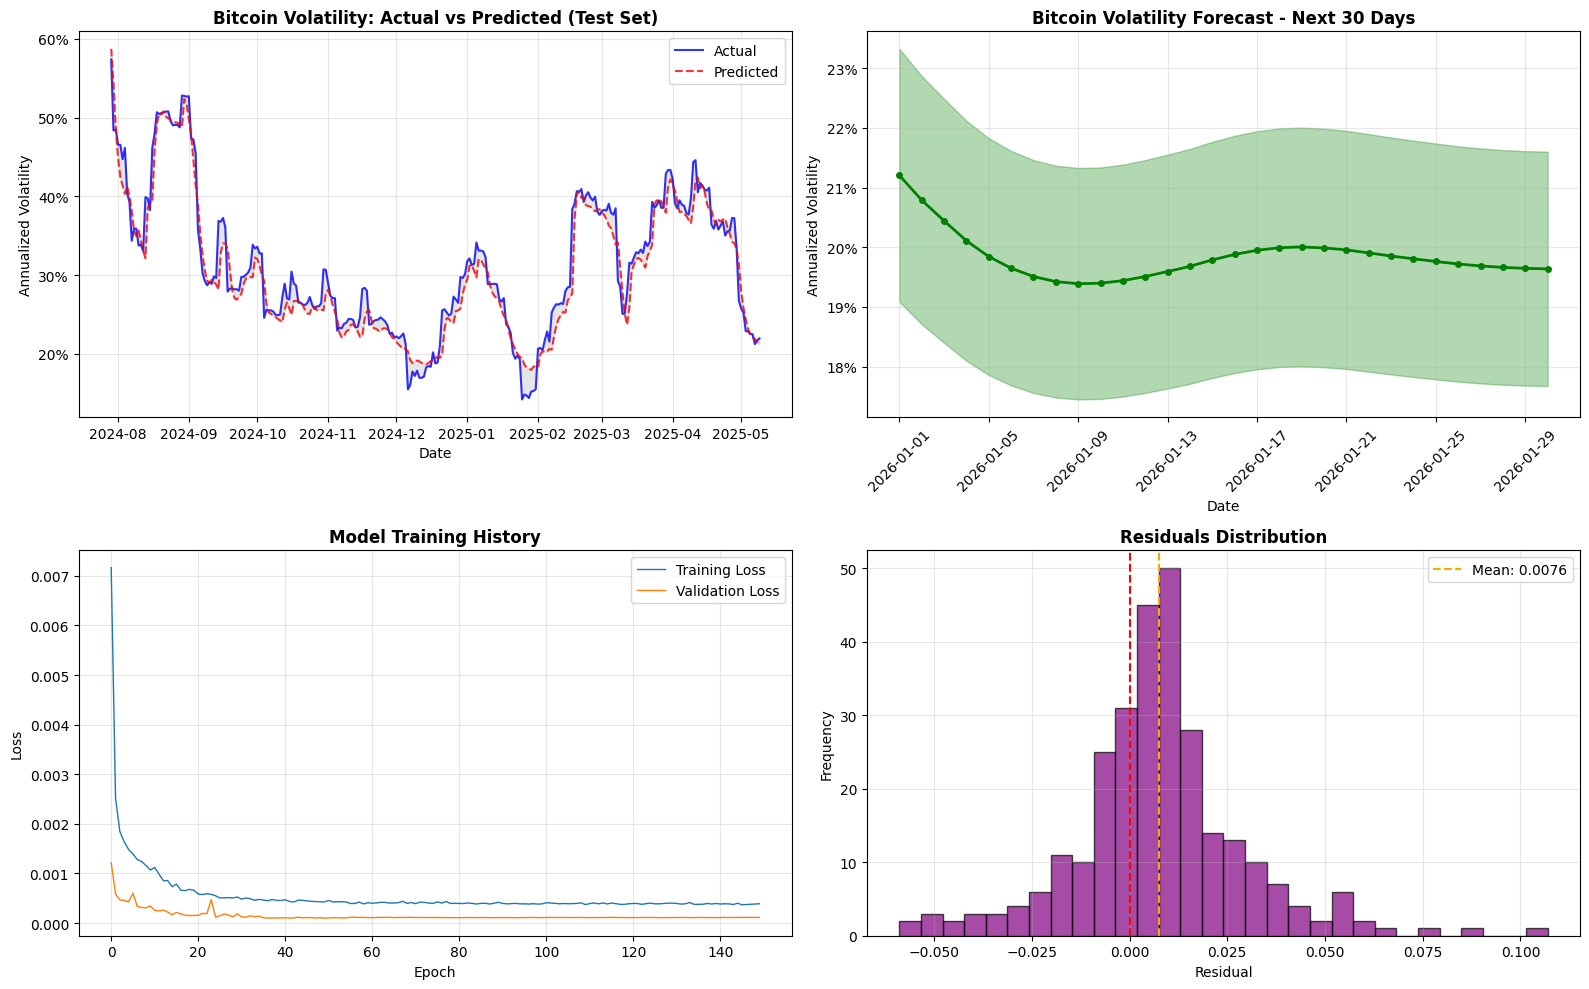

In [ ]:
def plot_forecasting_results(df, y_test_actual, y_pred_actual, forecast_30d,
                            test_size=0.2, sequence_length=60):
    """
    Plot comprehensive forecasting results
    """
    # Get dates
    test_start_idx = int(len(df) * (1 - test_size))
    test_dates = df['Date'].iloc[test_start_idx + sequence_length:].values

    # Align lengths
    min_len = min(len(test_dates), len(y_test_actual))
    test_dates = test_dates[:min_len]
    y_test_actual = y_test_actual[:min_len]
    y_pred_actual = y_pred_actual[:min_len]

    # Future dates
    last_date = df['Date'].iloc[-1]
    future_dates = pd.date_range(start=last_date, periods=31, freq='D')[1:]

    # Create plots
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    # 1. Actual vs Predicted (Test Set)
    axes[0, 0].plot(test_dates, y_test_actual,
                    label='Actual', color='blue', linewidth=1.5, alpha=0.8)
    axes[0, 0].plot(test_dates, y_pred_actual,
                    label='Predicted', color='red', linewidth=1.5, linestyle='--', alpha=0.8)
    axes[0, 0].fill_between(test_dates, y_test_actual, y_pred_actual,
                            alpha=0.2, color='gray')
    axes[0, 0].set_title('Bitcoin Volatility: Actual vs Predicted (Test Set)',
                         fontsize=12, fontweight='bold')
    axes[0, 0].set_xlabel('Date')
    axes[0, 0].set_ylabel('Annualized Volatility')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

    # 2. Forecast Next 30 Days
    axes[0, 1].plot(future_dates, forecast_30d,
                    color='green', linewidth=2, marker='o', markersize=4)
    axes[0, 1].fill_between(future_dates, forecast_30d * 0.9, forecast_30d * 1.1,
                            alpha=0.3, color='green')
    axes[0, 1].set_title('Bitcoin Volatility Forecast - Next 30 Days',
                         fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel('Date')
    axes[0, 1].set_ylabel('Annualized Volatility')
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    axes[0, 1].tick_params(axis='x', rotation=45)

    # 3. Training History
    axes[1, 0].plot(history.history['loss'], label='Training Loss', linewidth=1)
    axes[1, 0].plot(history.history['val_loss'], label='Validation Loss', linewidth=1)
    axes[1, 0].set_title('Model Training History', fontsize=12, fontweight='bold')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Loss')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)

    # 4. Residuals Distribution
    residuals = y_test_actual - y_pred_actual
    axes[1, 1].hist(residuals, bins=30, alpha=0.7, color='purple', edgecolor='black')
    axes[1, 1].axvline(x=0, color='red', linestyle='--', linewidth=1.5)
    axes[1, 1].axvline(x=residuals.mean(), color='orange', linestyle='--',
                       label=f'Mean: {residuals.mean():.4f}')
    axes[1, 1].set_title('Residuals Distribution', fontsize=12, fontweight='bold')
    axes[1, 1].set_xlabel('Residual')
    axes[1, 1].set_ylabel('Frequency')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('lstm_volatility_forecast.png', dpi=150, bbox_inches='tight')
    plt.show()

    return residuals

# Plot results
residuals = plot_forecasting_results(df, y_test_actual, y_pred_actual, forecast_30d)


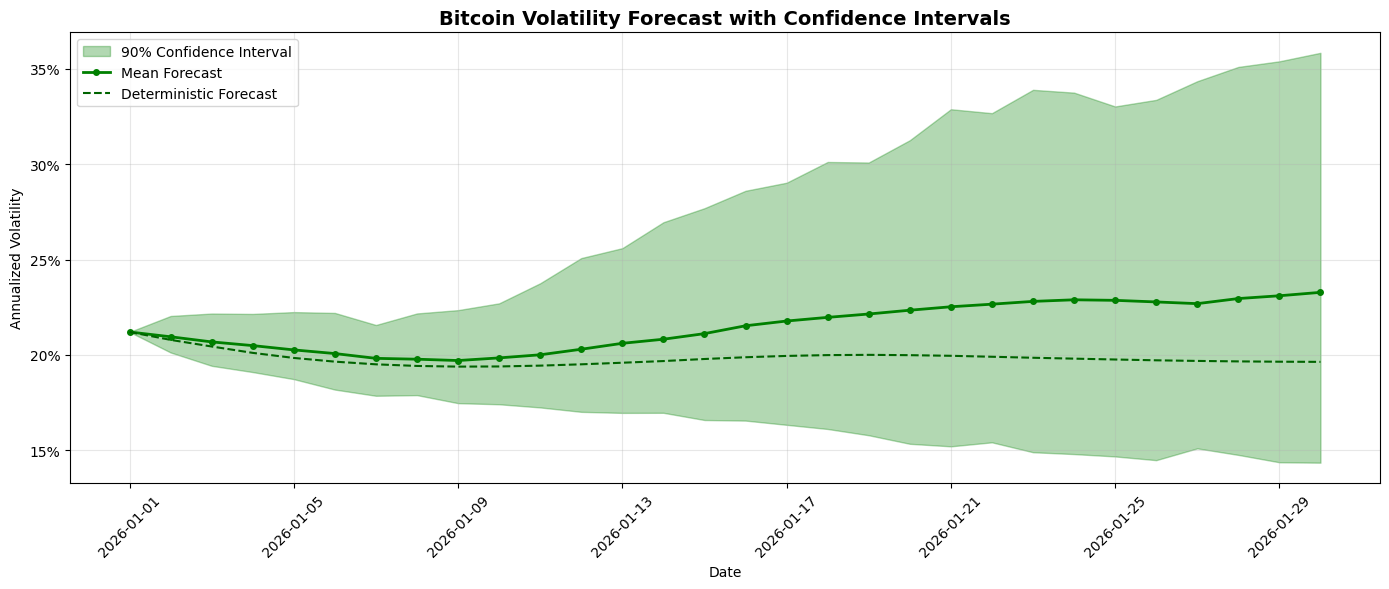

In [ ]:
def forecast_with_confidence(model, last_sequence, scaler, target_idx,
                             n_simulations=100, days_ahead=30):
    """
    Forecast with Monte Carlo simulation for confidence intervals
    """
    all_predictions = []

    for _ in range(n_simulations):
        predictions = []
        current_seq = last_sequence.copy()

        for _ in range(days_ahead):
            pred = model.predict(current_seq.reshape(1, current_seq.shape[0],
                                                     current_seq.shape[1]), verbose=0)
            predictions.append(pred[0, 0])

            # Add small noise for simulation
            noise = np.random.normal(0, 0.02, current_seq.shape[1])
            pred_with_noise = pred[0] + noise

            pred_full = np.zeros((1, current_seq.shape[1]))
            pred_full[0, target_idx] = pred_with_noise[target_idx]

            for j in range(current_seq.shape[1]):
                if j != target_idx:
                    pred_full[0, j] = current_seq[-1, j] + noise[j] * 0.1

            current_seq = np.roll(current_seq, -1, axis=0)
            current_seq[-1] = pred_full[0]

        all_predictions.append(predictions)

    all_predictions = np.array(all_predictions)

    # Inverse transform
    all_predictions_original = []
    for pred in all_predictions:
        pred_original = inverse_transform(scaler, pred.reshape(-1, 1), target_idx,
                                          current_seq.shape[1])
        all_predictions_original.append(pred_original)

    all_predictions_original = np.array(all_predictions_original)

    # Statistics
    mean_forecast = all_predictions_original.mean(axis=0)
    lower_forecast = np.percentile(all_predictions_original, 10, axis=0)
    upper_forecast = np.percentile(all_predictions_original, 90, axis=0)

    return mean_forecast, lower_forecast, upper_forecast

# Forecast with confidence intervals
mean_forecast, lower_forecast, upper_forecast = forecast_with_confidence(
    model, last_sequence, scaler,
    target_idx=feature_cols.index('rv_annualized_20d'),
    n_simulations=100, days_ahead=30
)

# Plot with confidence intervals
fig, ax = plt.subplots(figsize=(14, 6))

future_dates = pd.date_range(start=df['Date'].iloc[-1], periods=31, freq='D')[1:]

ax.fill_between(future_dates, lower_forecast, upper_forecast,
                 alpha=0.3, color='green', label='90% Confidence Interval')
ax.plot(future_dates, mean_forecast, color='green', linewidth=2,
        marker='o', markersize=4, label='Mean Forecast')
ax.plot(future_dates, forecast_30d, color='darkgreen', linewidth=1.5,
        linestyle='--', label='Deterministic Forecast')

ax.set_title('Bitcoin Volatility Forecast with Confidence Intervals',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Annualized Volatility')
ax.legend()
ax.grid(True, alpha=0.3)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('volatility_forecast_with_confidence.png', dpi=150, bbox_inches='tight')
plt.show()


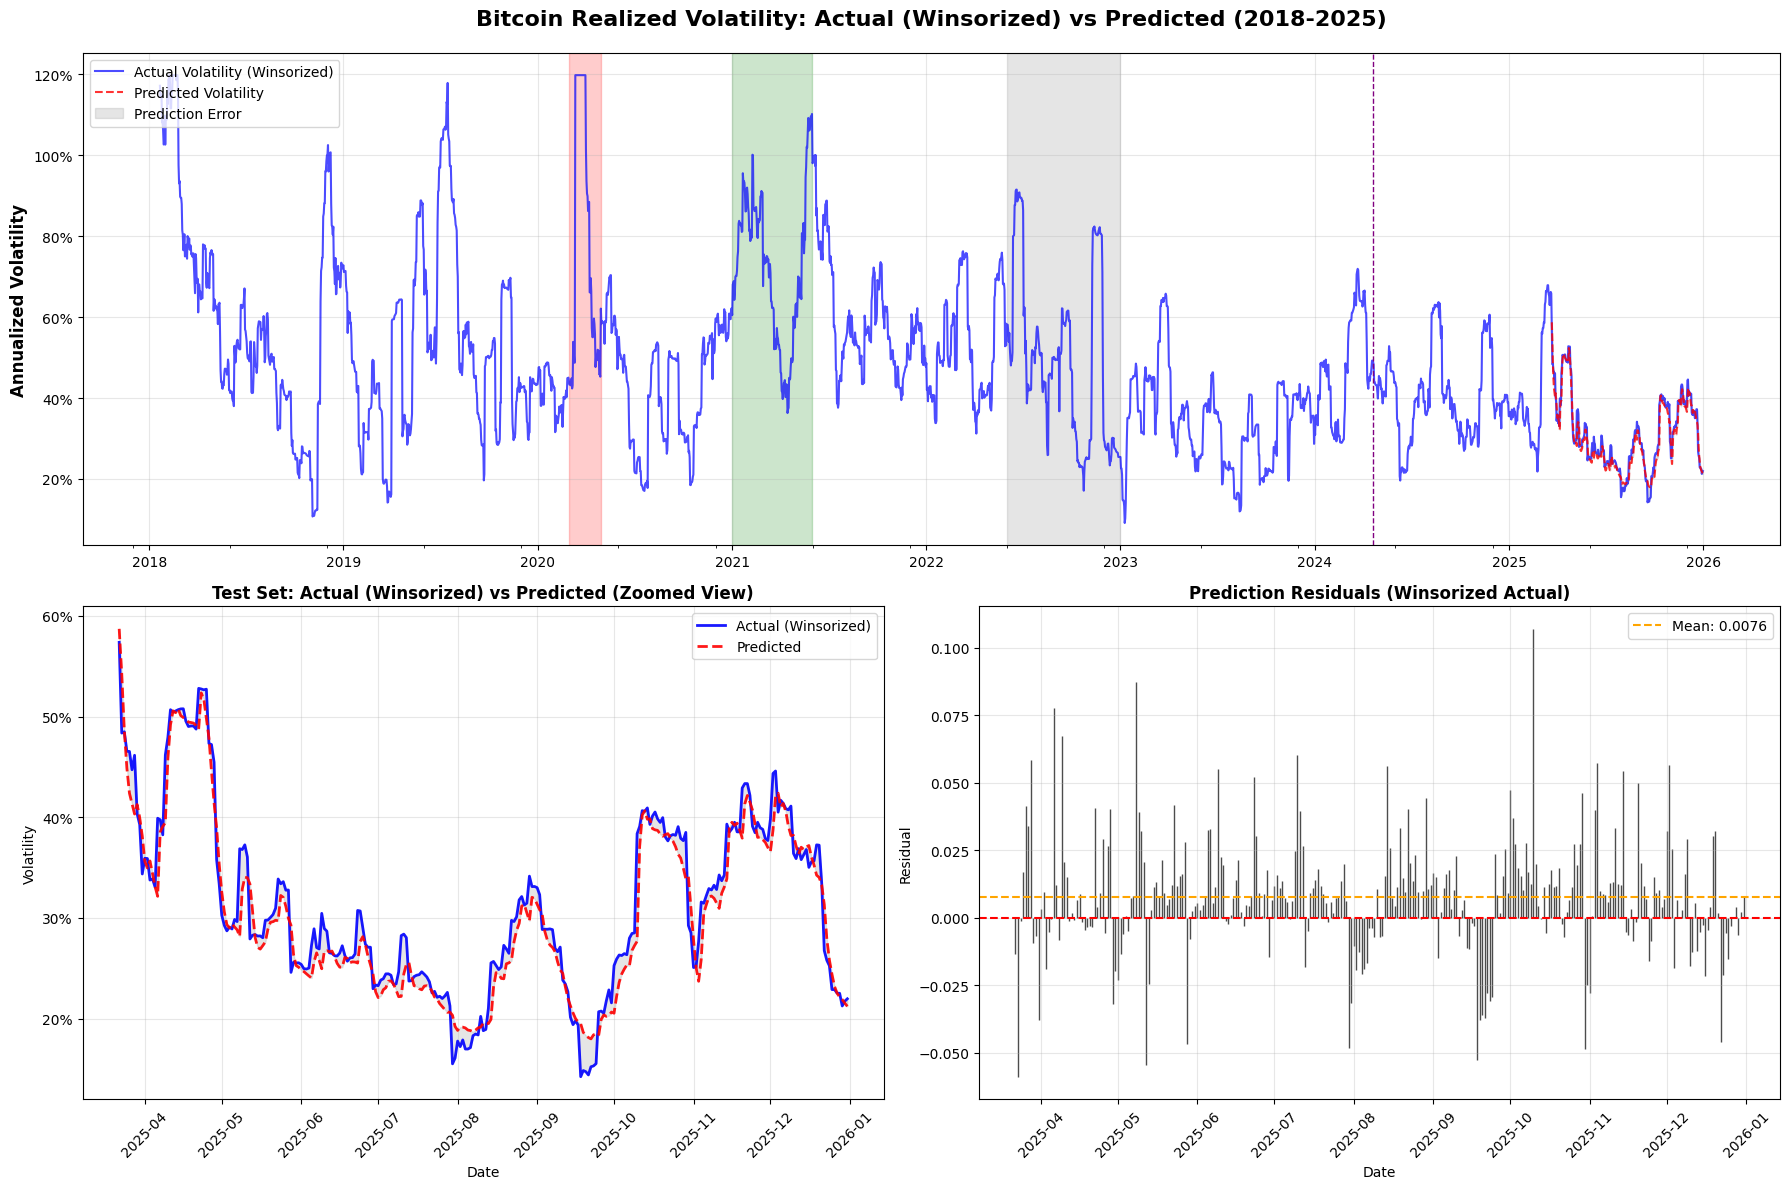

In [ ]:

def plot_actual_vs_predicted(df_source, y_test_actual, y_pred_actual, sequence_length=60):

    train_size_samples = len(X_train)
    val_size_samples = len(X_val)

    # The actual dates corresponding to the X,y samples start after 'sequence_length' days
    test_start_idx_in_df_source = sequence_length + train_size_samples + val_size_samples

    test_dates = df_source['Date'].iloc[test_start_idx_in_df_source : test_start_idx_in_df_source + len(y_test_actual)].values

    # Get the actual winsorized values corresponding to the test set dates
    y_test_actual_winsorized_for_plot = df_source['rv_annualized_20d_winsorized'].iloc[test_start_idx_in_df_source : test_start_idx_in_df_source + len(y_test_actual)].values

    # Align lengths (should already be aligned if indices are correct)
    min_len = min(len(test_dates), len(y_test_actual), len(y_pred_actual))
    test_dates = test_dates[:min_len]
    y_test_actual_trimmed = y_test_actual[:min_len] # Still non-winsorized as per model output
    y_pred_actual_trimmed = y_pred_actual[:min_len]
    y_test_actual_winsorized_for_plot = y_test_actual_winsorized_for_plot[:min_len]


    # Create figure
    fig = plt.figure(figsize=(18, 12))

    # Plot 1: Full timeline with all data (Winsorized Actual)
    ax1 = plt.subplot(2, 1, 1)

    # Plot historical volatility (all data) - using winsorized data
    ax1.plot(df_source['Date'], df_source['rv_annualized_20d_winsorized'],
             color='blue', linewidth=1.5, alpha=0.7, label='Actual Volatility (Winsorized)')

    # Plot predictions on test set
    ax1.plot(test_dates, y_pred_actual_trimmed,
             color='red', linewidth=1.5, linestyle='--', alpha=0.8, label='Predicted Volatility')

    # Fill area between actual (winsorized) and predicted (non-winsorized)
    ax1.fill_between(test_dates, y_test_actual_winsorized_for_plot, y_pred_actual_trimmed,
                     alpha=0.2, color='gray', label='Prediction Error')

    # Formatting
    ax1.set_title('Bitcoin Realized Volatility: Actual (Winsorized) vs Predicted (2018-2025)',
                  fontsize=16, fontweight='bold', pad=20)
    ax1.set_ylabel('Annualized Volatility', fontsize=12, fontweight='bold')
    ax1.legend(loc='upper left', fontsize=10)
    ax1.grid(True, alpha=0.3)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

    # Format x-axis
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax1.xaxis.set_major_locator(mdates.YearLocator())
    ax1.xaxis.set_minor_locator(mdates.MonthLocator(interval=6))

    # Highlight key events
    ax1.axvspan(pd.to_datetime('2020-03-01'), pd.to_datetime('2020-04-30'),
                alpha=0.2, color='red', label='COVID-19 Crash')
    ax1.axvspan(pd.to_datetime('2021-01-01'), pd.to_datetime('2021-05-31'),
                alpha=0.2, color='green', label='Bull Run 2021')
    ax1.axvspan(pd.to_datetime('2022-06-01'), pd.to_datetime('2022-12-31'),
                alpha=0.2, color='gray', label='Bear Market 2022')
    ax1.axvline(pd.to_datetime('2024-04-20'), color='purple', linestyle='--',
                linewidth=1, label='Halving 2024')

    # Plot 2: Test set detailed view (Winsorized Actual vs Non-Winsorized Predicted)
    ax2 = plt.subplot(2, 2, 3)

    ax2.plot(test_dates, y_test_actual_winsorized_for_plot, # Using winsorized actual for plot
             color='blue', linewidth=2, label='Actual (Winsorized)', alpha=0.9)
    ax2.plot(test_dates, y_pred_actual_trimmed,
             color='red', linewidth=2, linestyle='--', label='Predicted', alpha=0.9)
    ax2.fill_between(test_dates, y_test_actual_winsorized_for_plot, y_pred_actual_trimmed,
                     alpha=0.2, color='gray')
    ax2.set_title('Test Set: Actual (Winsorized) vs Predicted (Zoomed View)',
                  fontsize=12, fontweight='bold')
    ax2.set_xlabel('Date', fontsize=10)
    ax2.set_ylabel('Volatility', fontsize=10)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax2.tick_params(axis='x', rotation=45)

    # Plot 3: Residuals (based on Winsorized Actual - Predicted)
    ax3 = plt.subplot(2, 2, 4)

    residuals = y_test_actual_winsorized_for_plot - y_pred_actual_trimmed # Residuals based on winsorized actual
    ax3.bar(test_dates, residuals, width=3, alpha=0.7, color='purple', edgecolor='black')
    ax3.axhline(y=0, color='red', linestyle='--', linewidth=1.5)
    ax3.axhline(y=residuals.mean(), color='orange', linestyle='--',
                label=f'Mean: {residuals.mean():.4f}')
    ax3.set_title('Prediction Residuals (Winsorized Actual)', fontsize=12, fontweight='bold')
    ax3.set_xlabel('Date', fontsize=10)
    ax3.set_ylabel('Residual', fontsize=10)
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    ax3.tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.savefig('actual_vs_predicted_2018_2025_winsorized.png', dpi=150, bbox_inches='tight')
    plt.show()

    return residuals

# Plot actual vs predicted
residuals = plot_actual_vs_predicted(df_rv_winsorized, y_test_actual, y_pred_actual)

In [ ]:
# ============================================================================
# 4. PREDICT ON TEST SET
# ============================================================================

def inverse_transform(scaler, y_scaled, target_idx=0):
    """Inverse transform scaled predictions"""
    y_scaled = y_scaled.reshape(-1, 1)
    zeros = np.zeros((len(y_scaled), scaler.scale_.shape[0] - 1))
    y_inv = scaler.inverse_transform(np.concatenate([y_scaled, zeros], axis=1))
    return y_inv[:, target_idx]

# Predict on test set
y_pred_scaled = model.predict(X_test, verbose=0)
y_test_actual = inverse_transform(scaler, y_test, target_idx=0)
y_pred_actual = inverse_transform(scaler, y_pred_scaled, target_idx=0)

In [ ]:
def forecast_future(model, last_sequence, scaler, target_idx, days_ahead=60):
    """Forecast future volatility"""
    predictions = []
    current_seq = last_sequence.copy()

    for _ in range(days_ahead):
        pred = model.predict(current_seq.reshape(1, current_seq.shape[0], current_seq.shape[1]), verbose=0)
        predictions.append(pred[0, 0])

        # Update sequence
        pred_full = np.zeros((1, current_seq.shape[1]))
        pred_full[0, target_idx] = pred[0, 0]
        for j in range(current_seq.shape[1]):
            if j != target_idx:
                pred_full[0, j] = current_seq[-1, j]

        current_seq = np.roll(current_seq, -1, axis=0)
        current_seq[-1] = pred_full[0]

    predictions = np.array(predictions).reshape(-1, 1)
    predictions_original = inverse_transform(scaler, predictions, target_idx)
    return predictions_original

# Forecast next 60 days
last_sequence = X_test[-1]
forecast_60d = forecast_future(model, last_sequence, scaler, target_idx=0, days_ahead=60)

# Create forecast dates
last_date = df['Date'].iloc[-1]
forecast_dates = pd.date_range(start=last_date, periods=61, freq='D')[1:]

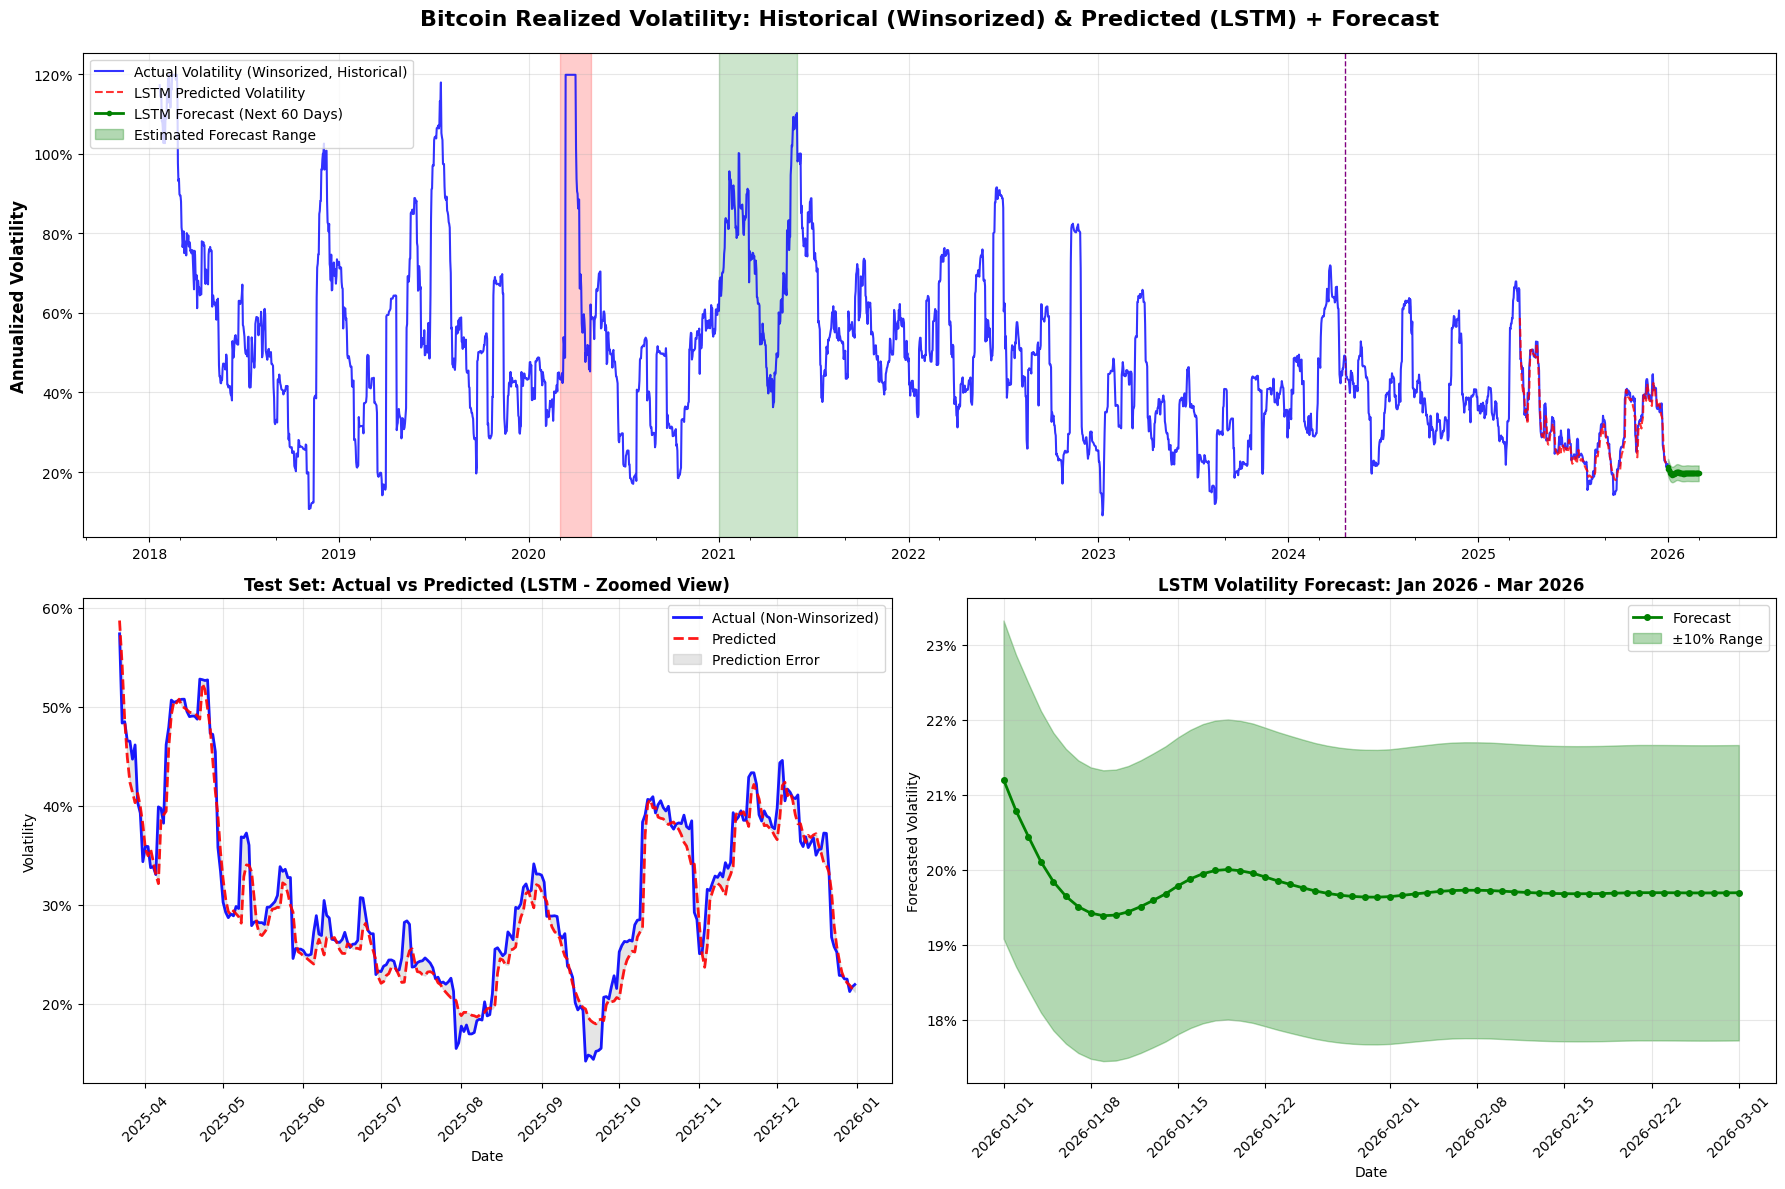

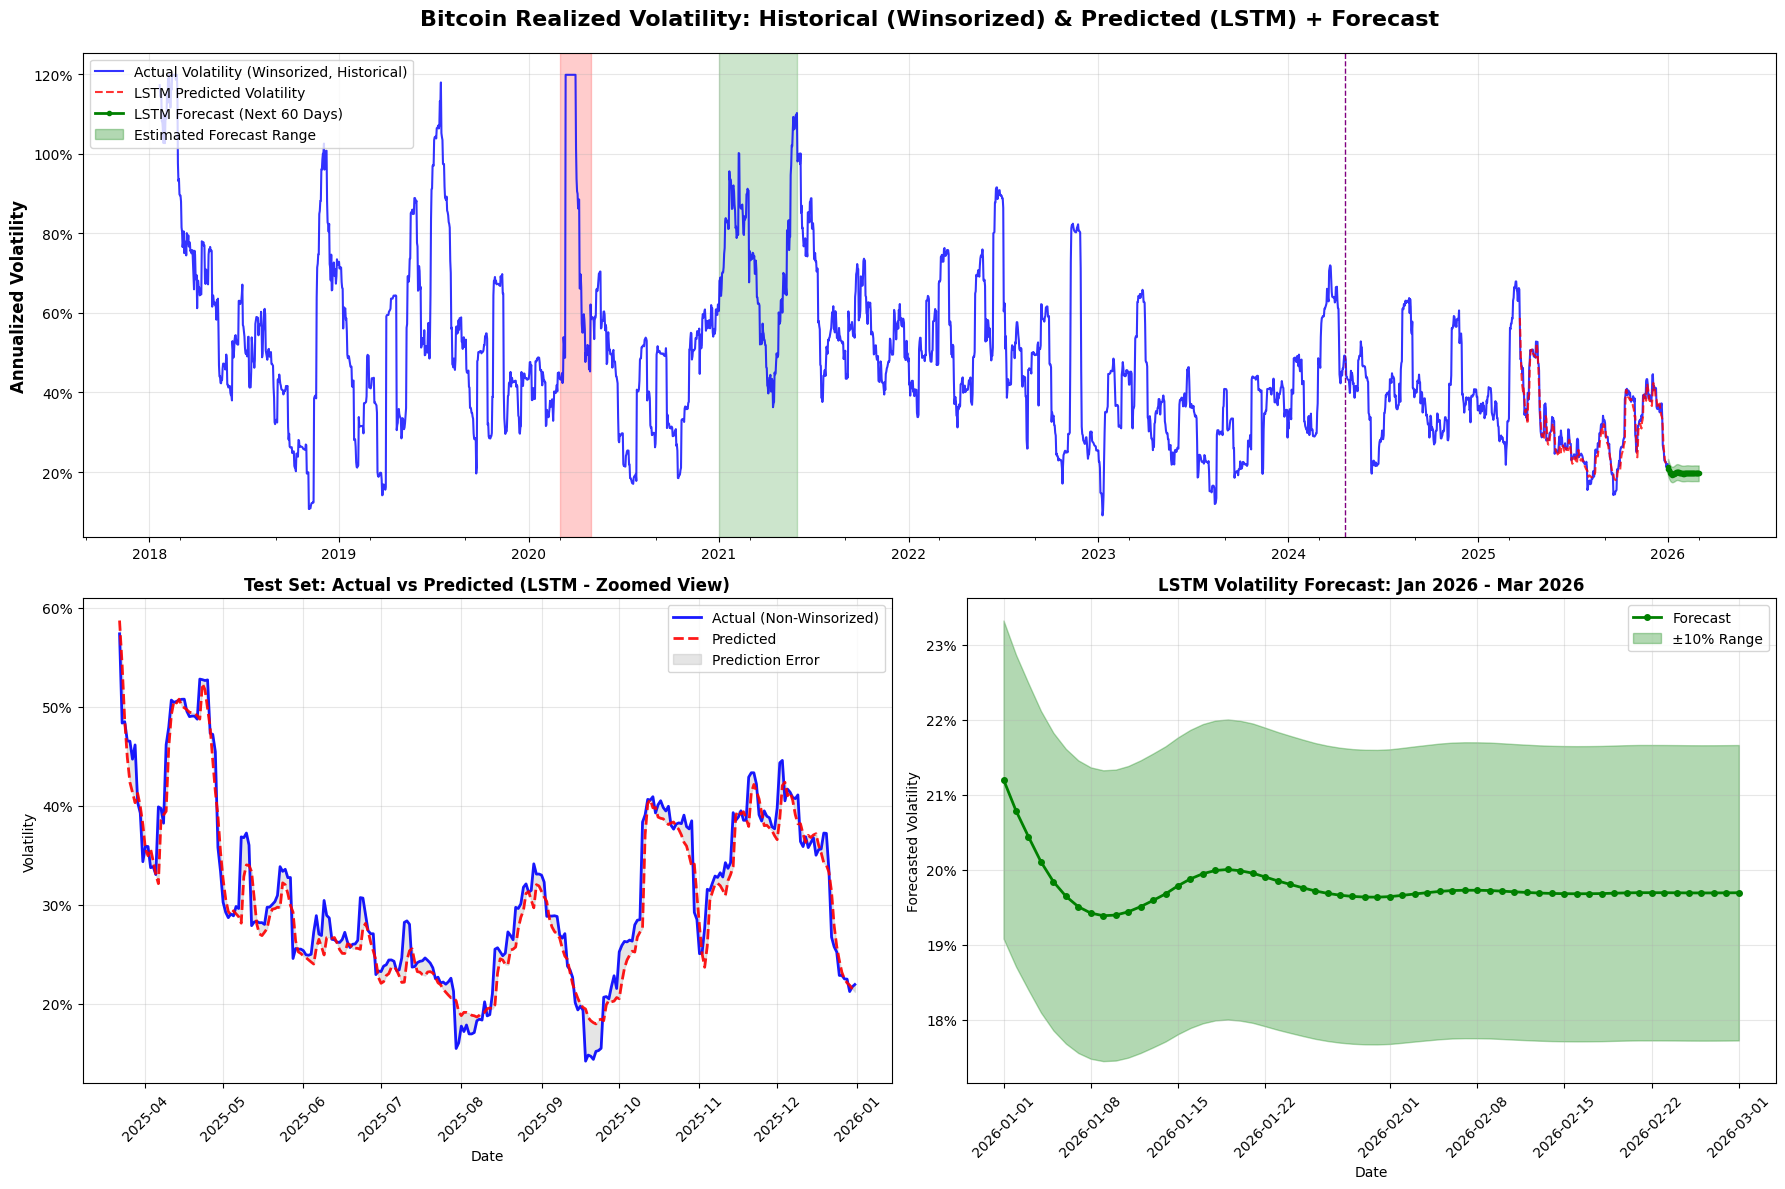

In [ ]:
def plot_full_forecast(df_model_input, y_test_actual, y_pred_actual, forecast_60d, forecast_dates, df_rv_winsorized, sequence_length=60, test_size=0.2):

    # Get dates for the test set from the df_model_input (the one used for LSTM training)
    total_samples_in_Xy = len(df_model_input) - sequence_length
    train_ratio = 0.8
    val_ratio = 0.1

    train_size_samples = int(total_samples_in_Xy * train_ratio)
    val_size_samples = int(total_samples_in_Xy * val_ratio)

    test_start_idx_in_df_model_input = sequence_length + train_size_samples + val_size_samples

    test_dates = df_model_input['Date'].iloc[test_start_idx_in_df_model_input : test_start_idx_in_df_model_input + len(y_test_actual)].values

    # Align lengths for plotting
    min_len = min(len(test_dates), len(y_test_actual))
    test_dates = test_dates[:min_len]
    y_pred_actual_trimmed = y_pred_actual[:min_len]


    actual_test_data_for_comparison = df_model_input['rv_annualized_20d'].iloc[test_start_idx_in_df_model_input : test_start_idx_in_df_model_input + len(y_test_actual)].values

    # Create figure with 3 subplots
    fig = plt.figure(figsize=(18, 12))

    # Main plot: Full timeline (Historical (Winsorized) + Predicted Test + Forecast)
    ax1 = plt.subplot(2, 1, 1)

    # Plot historical volatility (2018-2025) using the *winsorized* dataset for overall context
    ax1.plot(df_rv_winsorized['Date'], df_rv_winsorized['rv_annualized_20d_winsorized'],
             color='blue', linewidth=1.5, alpha=0.8, label='Actual Volatility (Winsorized, Historical)')

    # Plot predictions on test set (these are non-winsorized predictions from the model)
    ax1.plot(test_dates, y_pred_actual_trimmed,
             color='red', linewidth=1.5, linestyle='--', alpha=0.8, label='LSTM Predicted Volatility')

    # Plot forecast
    ax1.plot(forecast_dates, forecast_60d,
             color='green', linewidth=2, marker='o', markersize=3, label='LSTM Forecast (Next 60 Days)')

    # Fill forecast area
    ax1.fill_between(forecast_dates, forecast_60d * 0.9, forecast_60d * 1.1,
                     alpha=0.3, color='green', label='Estimated Forecast Range')

    # Formatting for ax1
    ax1.set_title('Bitcoin Realized Volatility: Historical (Winsorized) & Predicted (LSTM) + Forecast',
                  fontsize=16, fontweight='bold', pad=20)
    ax1.set_ylabel('Annualized Volatility', fontsize=12, fontweight='bold')
    ax1.legend(loc='upper left', fontsize=10)
    ax1.grid(True, alpha=0.3)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax1.xaxis.set_major_locator(mdates.YearLocator())
    ax1.xaxis.set_minor_locator(mdates.MonthLocator(interval=6))
    ax1.tick_params(axis='x', rotation=0)

    # Highlight key events
    ax1.axvspan(pd.to_datetime('2020-03-01'), pd.to_datetime('2020-04-30'),
                alpha=0.2, color='red', label='COVID-19 Crash')
    ax1.axvspan(pd.to_datetime('2021-01-01'), pd.to_datetime('2021-05-31'),
                alpha=0.2, color='green', label='Bull Run')
    ax1.axvline(pd.to_datetime('2024-04-20'), color='purple', linestyle='--',
                linewidth=1, label='Halving 2024')

    # Second subplot: Test set comparison (Actual non-winsorized vs Predicted non-winsorized)
    ax2 = plt.subplot(2, 2, 3)

    # *** IMPORTANT CHANGE HERE ***
    # Using actual_test_data_for_comparison (non-winsorized) for consistency with y_pred_actual
    ax2.plot(test_dates, actual_test_data_for_comparison,
             color='blue', linewidth=2, label='Actual (Non-Winsorized)', alpha=0.9)
    ax2.plot(test_dates, y_pred_actual_trimmed,
             color='red', linewidth=2, linestyle='--', label='Predicted', alpha=0.9)
    ax2.fill_between(test_dates, actual_test_data_for_comparison, y_pred_actual_trimmed,
                     alpha=0.2, color='gray', label='Prediction Error')
    ax2.set_title('Test Set: Actual vs Predicted (LSTM - Zoomed View)',
                  fontsize=12, fontweight='bold')
    ax2.set_xlabel('Date', fontsize=10)
    ax2.set_ylabel('Volatility', fontsize=10)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax2.tick_params(axis='x', rotation=45)

    # Third subplot: Forecast details
    ax3 = plt.subplot(2, 2, 4)

    ax3.plot(forecast_dates, forecast_60d,
             color='green', linewidth=2, marker='o', markersize=4, label='Forecast')
    ax3.fill_between(forecast_dates, forecast_60d * 0.9, forecast_60d * 1.1,
                     alpha=0.3, color='green', label='±10% Range')
    ax3.set_title(f'LSTM Volatility Forecast: {forecast_dates[0].strftime("%b %Y")} - {forecast_dates[-1].strftime("%b %Y")}',
                  fontsize=12, fontweight='bold')
    ax3.set_xlabel('Date')
    ax3.set_ylabel('Forecasted Volatility')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax3.tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.savefig('bitcoin_volatility_full_forecast_winsorized.png', dpi=150, bbox_inches='tight')
    plt.show()

    return fig

# Plot full forecast with the winsorized data for actuals
plot_full_forecast(df, y_test_actual, y_pred_actual, forecast_60d, forecast_dates, df_rv_winsorized, sequence_length=sequence_length, test_size=0.2)


In [ ]:
print("\n" + "="*60)
print("DESCRIPTIVE STATISTICS: LSTM PREDICTIONS")
print("="*60)

print("\nPredicted Volatility (Test Set - Non-Winsorized):")
print(f"  Mean: {np.mean(y_pred_actual):.4f}")
print(f"  Median: {np.median(y_pred_actual):.4f}")
print(f"  Std Dev: {np.std(y_pred_actual):.4f}")
print(f"  Min: {np.min(y_pred_actual):.4f}")
print(f"  Max: {np.max(y_pred_actual):.4f}")

print("\nForecasted Volatility (Next 60 Days - Non-Winsorized):")
print(f"  Mean: {np.mean(forecast_60d):.4f}")
print(f"  Median: {np.median(forecast_60d):.4f}")
print(f"  Std Dev: {np.std(forecast_60d):.4f}")
print(f"  Min: {np.min(forecast_60d):.4f}")
print(f"  Max: {np.max(forecast_60d):.4f}")



DESCRIPTIVE STATISTICS: LSTM PREDICTIONS

Predicted Volatility (Test Set - Non-Winsorized):
  Mean: 0.3053
  Median: 0.2866
  Std Dev: 0.0869
  Min: 0.1798
  Max: 0.5872

Forecasted Volatility (Next 60 Days - Non-Winsorized):
  Mean: 0.1977
  Median: 0.1970
  Std Dev: 0.0029
  Min: 0.1939
  Max: 0.2121


In [ ]:
print("\n" + "="*60)
print("SAMPLE LSTM PREDICTIONS")
print("="*60)

print("\nPredicted Volatility (Test Set - First 10 Values, Non-Winsorized):")
print(np.array_str(y_pred_actual[:10], precision=6, suppress_small=True))

print("\nForecasted Volatility (Next 60 Days - First 10 Values, Non-Winsorized):")
print(np.array_str(forecast_60d[:10], precision=6, suppress_small=True))


SAMPLE LSTM PREDICTIONS

Predicted Volatility (Test Set - First 10 Values, Non-Winsorized):
[0.587197 0.542522 0.486157 0.448726 0.423876 0.413383 0.403188 0.412598
 0.399694 0.381342]

Forecasted Volatility (Next 60 Days - First 10 Values, Non-Winsorized):
[0.212055 0.207906 0.204438 0.201099 0.198443 0.196501 0.1951   0.194251
 0.1939   0.193983]


In [ ]:
print("\n" + "="*60)
print("SAMPLE LSTM PREDICTIONS (DataFrame Format)")
print("="*60)


total_samples_in_Xy = len(df_rv) - sequence_length
train_ratio = 0.8
val_ratio = 0.1

train_size_samples = int(total_samples_in_Xy * train_ratio)
val_size_samples = int(total_samples_in_Xy * val_ratio)

test_start_idx_in_df_source = sequence_length + train_size_samples + val_size_samples

test_dates_for_display = df_rv['Date'].iloc[test_start_idx_in_df_source : test_start_idx_in_df_source + len(y_pred_actual)].values

df_predictions_test = pd.DataFrame({
    'Date': test_dates_for_display,
    'Predicted_Volatility': y_pred_actual
})
print("\nPredicted Volatility (Test Set - Non-Winsorized):")
display(df_predictions_test.head(10))

# --- Forecasted Volatility (Next 60 Days) ---
df_forecast = pd.DataFrame({
    'Date': forecast_dates,
    'Forecasted_Volatility': forecast_60d
})
print("\nForecasted Volatility (Next 60 Days - Non-Winsorized):")
display(df_forecast.head(10))



SAMPLE LSTM PREDICTIONS (DataFrame Format)

Predicted Volatility (Test Set - Non-Winsorized):


,Date,Predicted_Volatility
0,2025-03-22,0.587197
1,2025-03-23,0.542522
2,2025-03-24,0.486157
3,2025-03-25,0.448726
4,2025-03-26,0.423876
5,2025-03-27,0.413383
6,2025-03-28,0.403188
7,2025-03-29,0.412598
8,2025-03-30,0.399694
9,2025-03-31,0.381342



Forecasted Volatility (Next 60 Days - Non-Winsorized):


,Date,Forecasted_Volatility
0,2026-01-01,0.212055
1,2026-01-02,0.207906
2,2026-01-03,0.204438
3,2026-01-04,0.201099
4,2026-01-05,0.198443
5,2026-01-06,0.196501
6,2026-01-07,0.195100
7,2026-01-08,0.194251
8,2026-01-09,0.193900
9,2026-01-10,0.193983


In [ ]:
def forecast_future(model, last_sequence, scaler, target_idx, days_ahead=60):
    """Forecast future volatility"""
    predictions = []
    current_seq = last_sequence.copy()

    for _ in range(days_ahead):
        pred = model.predict(current_seq.reshape(1, current_seq.shape[0], current_seq.shape[1]), verbose=0)
        predictions.append(pred[0, 0])

        # Update sequence
        pred_full = np.zeros((1, current_seq.shape[1]))
        pred_full[0, target_idx] = pred[0, 0]
        for j in range(current_seq.shape[1]):
            if j != target_idx:
                pred_full[0, j] = current_seq[-1, j]

        current_seq = np.roll(current_seq, -1, axis=0)
        current_seq[-1] = pred_full[0]

    predictions = np.array(predictions).reshape(-1, 1)
    predictions_original = inverse_transform(scaler, predictions, target_idx)
    return predictions_original

# Forecast next 90 days
last_sequence = X_test[-1]
forecast_90d = forecast_future(model, last_sequence, scaler, target_idx=0, days_ahead=90)

# Create forecast dates for 90 days
last_date = df['Date'].iloc[-1]
forecast_dates = pd.date_range(start=last_date, periods=91, freq='D')[1:]

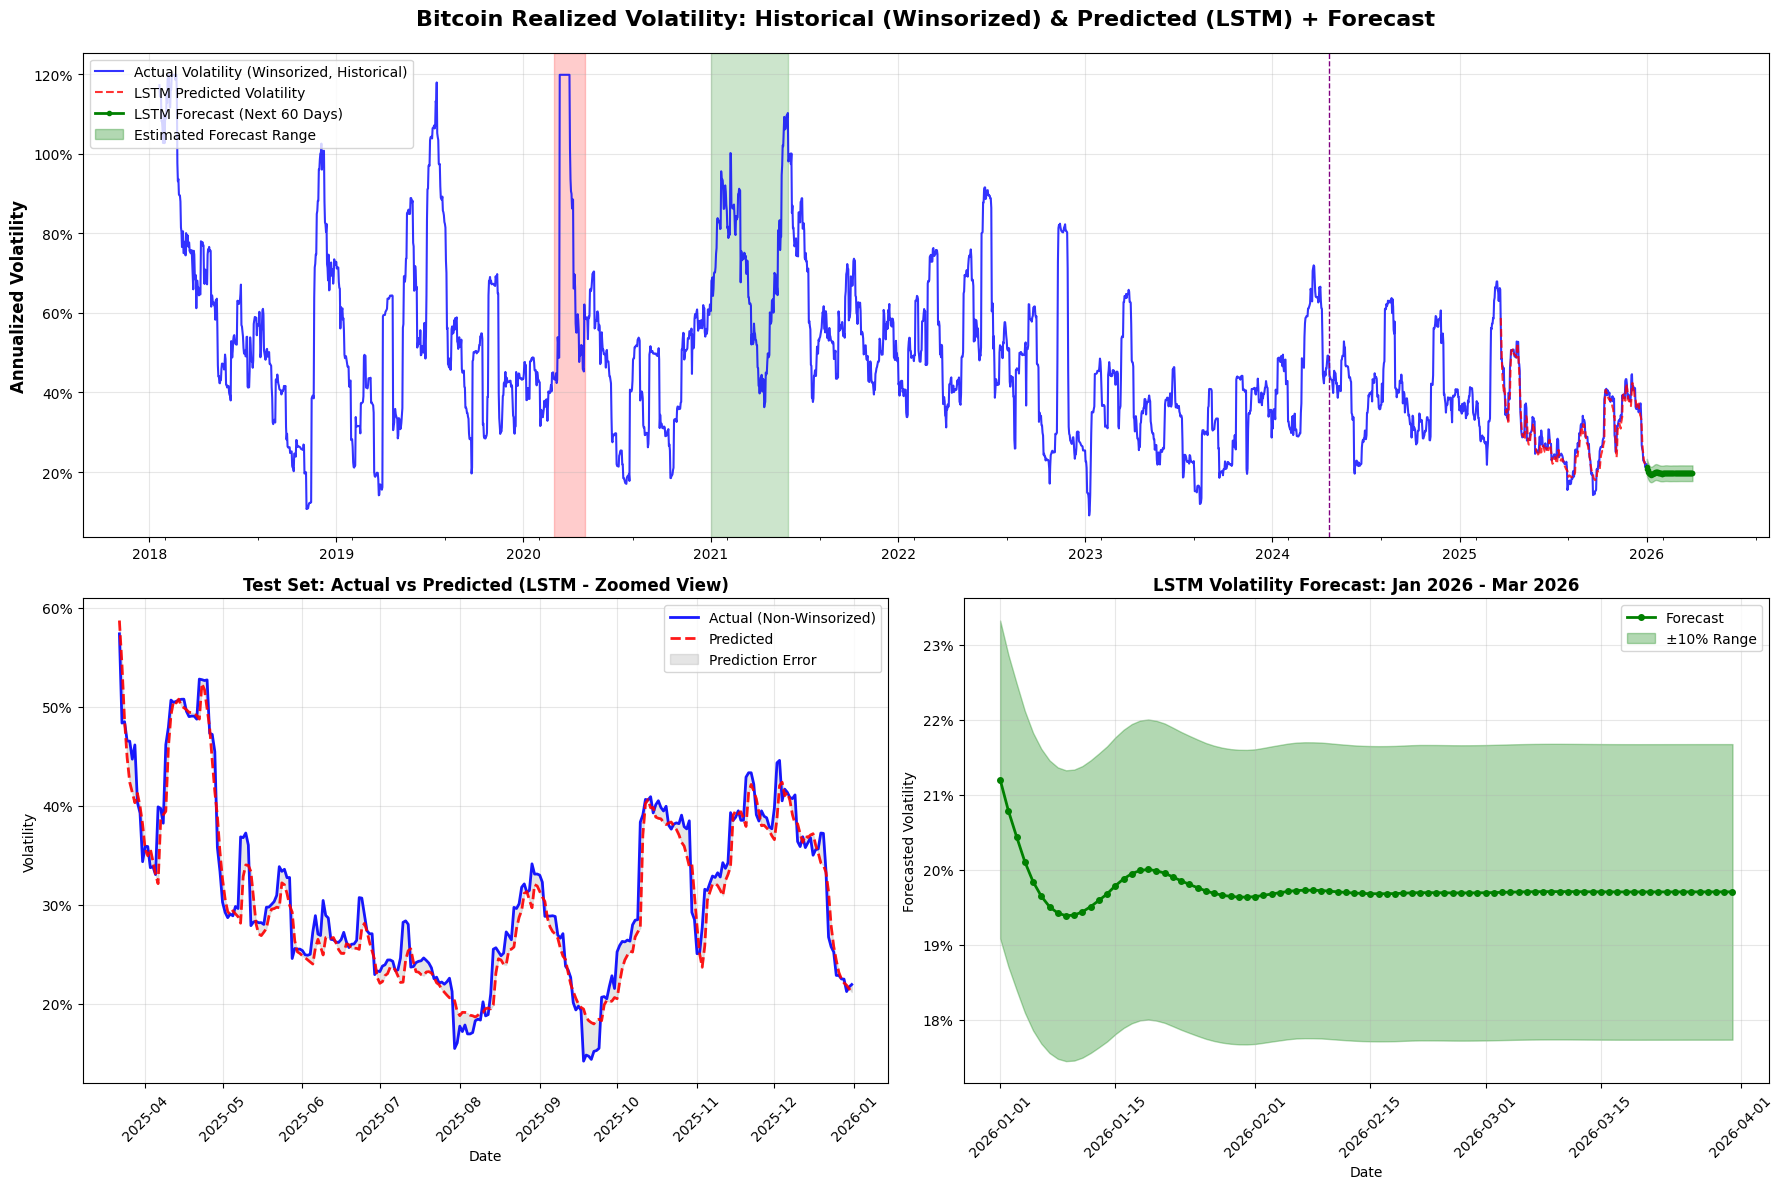

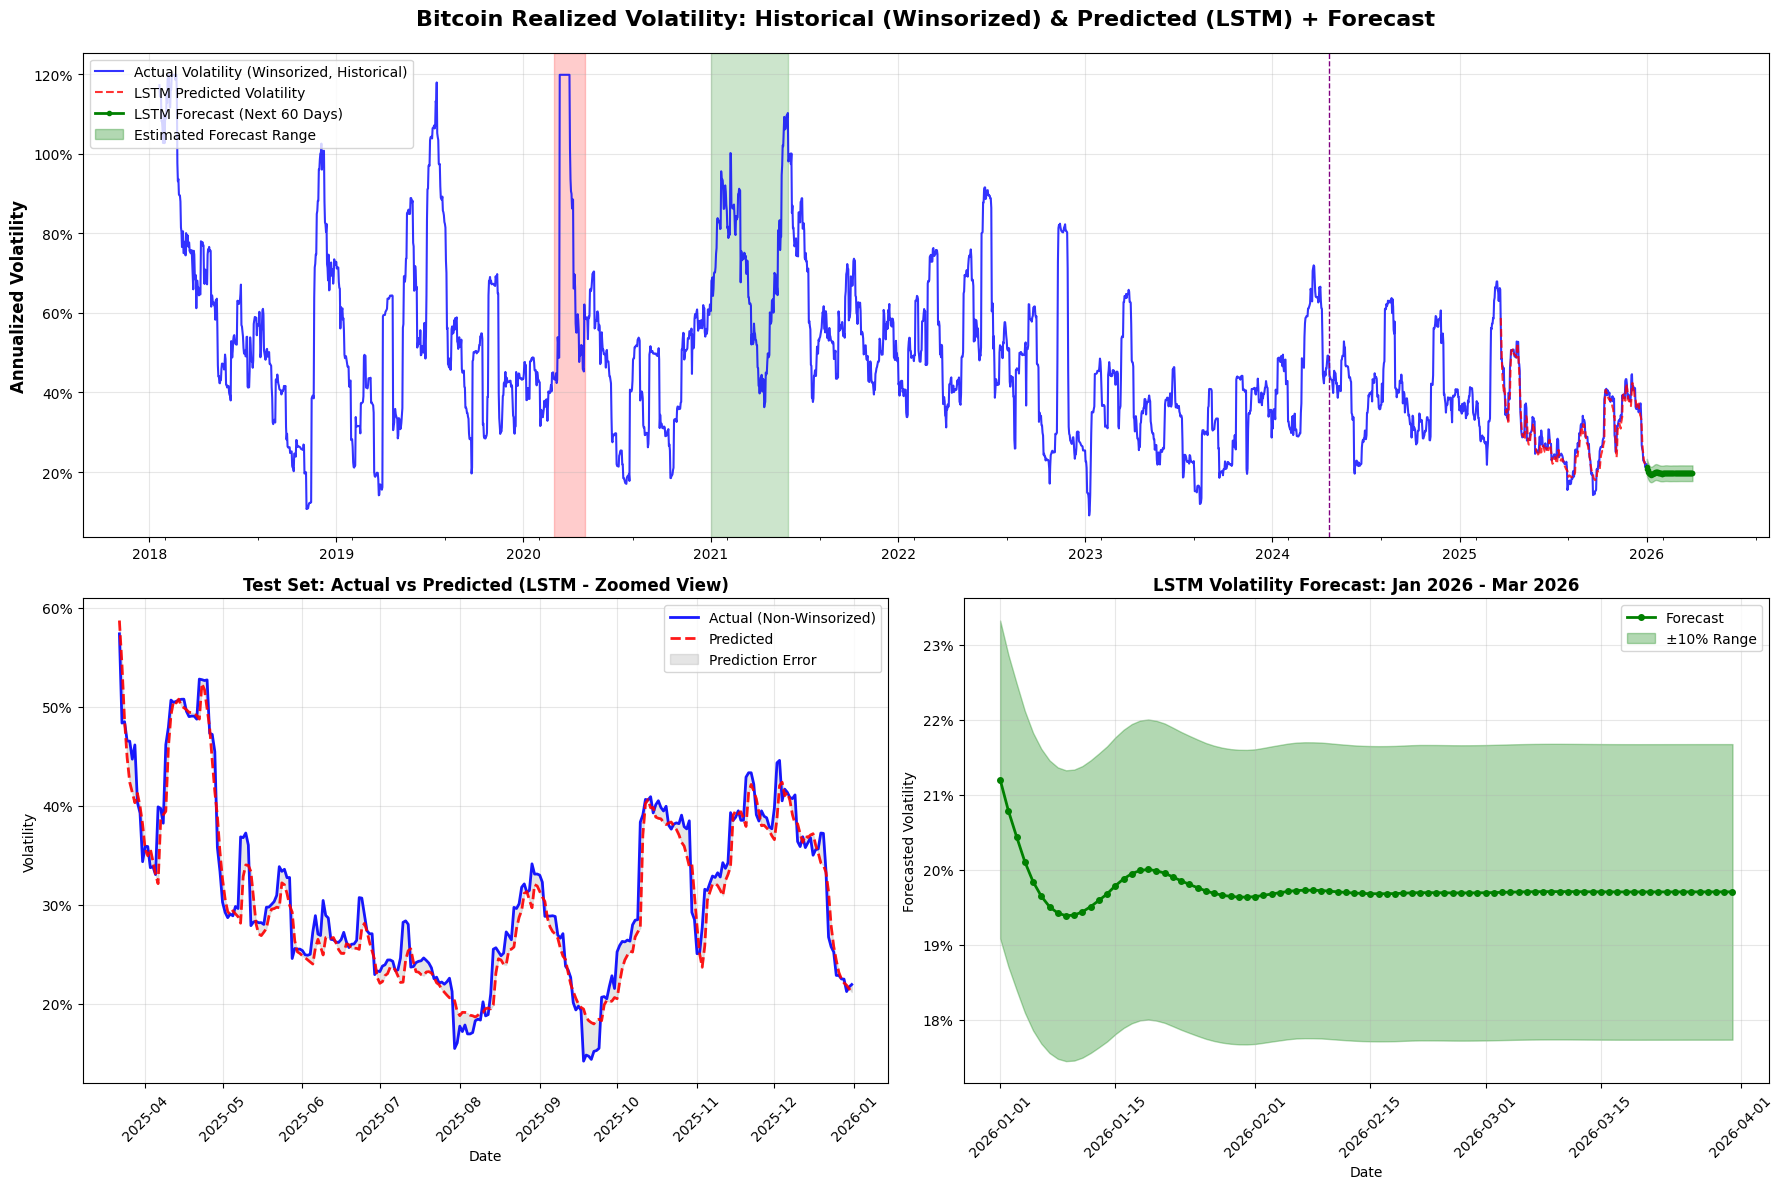

In [ ]:
def plot_full_forecast(df_model_input, y_test_actual, y_pred_actual, forecast_90d, forecast_dates, df_rv_winsorized, sequence_length=60, test_size=0.2):

    # Get dates for the test set from the df_model_input (the one used for LSTM training)
    total_samples_in_Xy = len(df_model_input) - sequence_length
    train_ratio = 0.8
    val_ratio = 0.1

    train_size_samples = int(total_samples_in_Xy * train_ratio)
    val_size_samples = int(total_samples_in_Xy * val_ratio)

    test_start_idx_in_df_model_input = sequence_length + train_size_samples + val_size_samples

    test_dates = df_model_input['Date'].iloc[test_start_idx_in_df_model_input : test_start_idx_in_df_model_input + len(y_test_actual)].values

    # Align lengths for plotting
    min_len = min(len(test_dates), len(y_test_actual))
    test_dates = test_dates[:min_len]
    y_pred_actual_trimmed = y_pred_actual[:min_len]

    # *** IMPORTANT CHANGE HERE ***

    actual_test_data_for_comparison = df_model_input['rv_annualized_20d'].iloc[test_start_idx_in_df_model_input : test_start_idx_in_df_model_input + len(y_test_actual)].values

    # Create figure with 3 subplots
    fig = plt.figure(figsize=(18, 12))

    # Main plot: Full timeline (Historical (Winsorized) + Predicted Test + Forecast)
    ax1 = plt.subplot(2, 1, 1)

    # Plot historical volatility (2018-2025) using the *winsorized* dataset for overall context
    ax1.plot(df_rv_winsorized['Date'], df_rv_winsorized['rv_annualized_20d_winsorized'],
             color='blue', linewidth=1.5, alpha=0.8, label='Actual Volatility (Winsorized, Historical)')

    # Plot predictions on test set (these are non-winsorized predictions from the model)
    ax1.plot(test_dates, y_pred_actual_trimmed,
             color='red', linewidth=1.5, linestyle='--', alpha=0.8, label='LSTM Predicted Volatility')

    # Plot forecast
    ax1.plot(forecast_dates, forecast_90d,
             color='green', linewidth=2, marker='o', markersize=3, label='LSTM Forecast (Next 60 Days)')

    # Fill forecast area
    ax1.fill_between(forecast_dates, forecast_90d * 0.9, forecast_90d * 1.1,
                     alpha=0.3, color='green', label='Estimated Forecast Range')

    # Formatting for ax1
    ax1.set_title('Bitcoin Realized Volatility: Historical (Winsorized) & Predicted (LSTM) + Forecast',
                  fontsize=16, fontweight='bold', pad=20)
    ax1.set_ylabel('Annualized Volatility', fontsize=12, fontweight='bold')
    ax1.legend(loc='upper left', fontsize=10)
    ax1.grid(True, alpha=0.3)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax1.xaxis.set_major_locator(mdates.YearLocator())
    ax1.xaxis.set_minor_locator(mdates.MonthLocator(interval=6))
    ax1.tick_params(axis='x', rotation=0)

    # Highlight key events
    ax1.axvspan(pd.to_datetime('2020-03-01'), pd.to_datetime('2020-04-30'),
                alpha=0.2, color='red', label='COVID-19 Crash')
    ax1.axvspan(pd.to_datetime('2021-01-01'), pd.to_datetime('2021-05-31'),
                alpha=0.2, color='green', label='Bull Run')
    ax1.axvline(pd.to_datetime('2024-04-20'), color='purple', linestyle='--',
                linewidth=1, label='Halving 2024')

    # Second subplot: Test set comparison (Actual non-winsorized vs Predicted non-winsorized)
    ax2 = plt.subplot(2, 2, 3)

    # *** IMPORTANT CHANGE HERE ***
    # Using actual_test_data_for_comparison (non-winsorized) for consistency with y_pred_actual
    ax2.plot(test_dates, actual_test_data_for_comparison,
             color='blue', linewidth=2, label='Actual (Non-Winsorized)', alpha=0.9)
    ax2.plot(test_dates, y_pred_actual_trimmed,
             color='red', linewidth=2, linestyle='--', label='Predicted', alpha=0.9)
    ax2.fill_between(test_dates, actual_test_data_for_comparison, y_pred_actual_trimmed,
                     alpha=0.2, color='gray', label='Prediction Error')
    ax2.set_title('Test Set: Actual vs Predicted (LSTM - Zoomed View)',
                  fontsize=12, fontweight='bold')
    ax2.set_xlabel('Date', fontsize=10)
    ax2.set_ylabel('Volatility', fontsize=10)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax2.tick_params(axis='x', rotation=45)

    # Third subplot: Forecast details
    ax3 = plt.subplot(2, 2, 4)

    ax3.plot(forecast_dates, forecast_90d,
             color='green', linewidth=2, marker='o', markersize=4, label='Forecast')
    ax3.fill_between(forecast_dates, forecast_90d * 0.9, forecast_90d * 1.1,
                     alpha=0.3, color='green', label='±10% Range')
    ax3.set_title(f'LSTM Volatility Forecast: {forecast_dates[0].strftime("%b %Y")} - {forecast_dates[-1].strftime("%b %Y")}',
                  fontsize=12, fontweight='bold')
    ax3.set_xlabel('Date')
    ax3.set_ylabel('Forecasted Volatility')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax3.tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.savefig('bitcoin_volatility_full_forecast_winsorized.png', dpi=150, bbox_inches='tight')
    plt.show()

    return fig

# Plot full forecast with the winsorized data for actuals
plot_full_forecast(df, y_test_actual, y_pred_actual, forecast_90d, forecast_dates, df_rv_winsorized, sequence_length=sequence_length, test_size=0.2)


RETURN ON INVESMENT

In [ ]:
print("\n" + "="*60)
print("RETURN ON INVESTMENT (ROI) CALCULATION")
print("="*60)

# --- Overall ROI ---
initial_price = df_rv['Close'].iloc[0]
present_price = df_rv['Close'].iloc[-1]

if initial_price != 0:
    overall_roi = ((present_price - initial_price) / initial_price) * 100
    print(f"\nOverall ROI from {df_rv['Date'].iloc[0].strftime('%Y-%m-%d')} to {df_rv['Date'].iloc[-1].strftime('%Y-%m-%d')}:")
    print(f"  Initial Investment (Close Price): ${initial_price:,.2f}")
    print(f"  Present Value (Close Price):    ${present_price:,.2f}")
    print(f"  Calculated ROI: {overall_roi:.2f}%")
else:
    print("Cannot calculate overall ROI, initial price is zero.")

# --- Annual ROI ---
print("\nAnnual ROI (Year-over-Year):")
# Ensure 'Date' is datetime and sort by date for correct yearly calculations
df_rv_sorted = df_rv.sort_values(by='Date').copy()
df_rv_sorted['Year'] = df_rv_sorted['Date'].dt.year

years = sorted(df_rv_sorted['Year'].unique())

annual_roi_list = []
for i in range(len(years) - 1):
    current_year = years[i]
    next_year = years[i+1]


    end_of_current_year_data = df_rv_sorted[df_rv_sorted['Year'] == current_year]
    if not end_of_current_year_data.empty:
        price_end_current_year = end_of_current_year_data['Close'].iloc[-1]
    else:
        continue # Skip if no data for the end of the current year

    if i == 0:
        # For the first full year of analysis, compare its end price to its start price
        start_of_first_year_data = df_rv_sorted[df_rv_sorted['Year'] == current_year]
        if not start_of_first_year_data.empty:
            price_start_current_year = start_of_first_year_data['Close'].iloc[0]
            if price_start_current_year != 0:
                annual_roi = ((price_end_current_year - price_start_current_year) / price_start_current_year) * 100
                annual_roi_list.append({'Year': f"{current_year} (Year Start to End)", 'ROI (%)': annual_roi})
        continue

    # For subsequent years, compare end of current year to end of previous year
    prev_year = years[i-1]
    end_of_prev_year_data = df_rv_sorted[df_rv_sorted['Year'] == prev_year]
    if not end_of_prev_year_data.empty:
        price_end_prev_year = end_of_prev_year_data['Close'].iloc[-1]
    else:
        price_end_prev_year = None

    if price_end_prev_year is not None and price_end_prev_year != 0:
        annual_roi = ((price_end_current_year - price_end_prev_year) / price_end_prev_year) * 100
        annual_roi_list.append({'Year': f"{current_year}", 'ROI (%)': annual_roi})

# Handle the last year (2025 in this case) specifically, comparing its end price to the start of the year
last_year = years[-1]
last_year_data = df_rv_sorted[df_rv_sorted['Year'] == last_year]
if not last_year_data.empty:
    price_end_last_year = last_year_data['Close'].iloc[-1]
    price_start_last_year = last_year_data['Close'].iloc[0]
    if price_start_last_year != 0:
        annual_roi_last_year = ((price_end_last_year - price_start_last_year) / price_start_last_year) * 100
        annual_roi_list.append({'Year': f"{last_year} (Year Start to End)", 'ROI (%)': annual_roi_last_year})


if annual_roi_list:
    df_annual_roi = pd.DataFrame(annual_roi_list)
    display(df_annual_roi)
else:
    print("Not enough data to calculate annual ROI.")



RETURN ON INVESTMENT (ROI) CALCULATION

Overall ROI from 2018-01-21 to 2025-12-31:
  Initial Investment (Close Price): $11,600.10
  Present Value (Close Price):    $87,508.83
  Calculated ROI: 654.38%

Annual ROI (Year-over-Year):


,Year,ROI (%)
0,2018 (Year Start to End),-67.735623
1,2019,92.203489
2,2020,303.160031
3,2021,59.667944
4,2022,-64.265237
5,2023,155.417374
6,2024,121.054726
7,2025 (Year Start to End),-7.319368


In [ ]:
print("\n" + "="*60)
print("DESCRIPTIVE ANALYSIS OF ANNUAL ROI")
print("="*60)

if 'df_annual_roi' in globals():
    print("\nAnnual ROI Statistics:")
    print(f"  Mean ROI: {df_annual_roi['ROI (%)'].mean():.2f}%")
    print(f"  Median ROI: {df_annual_roi['ROI (%)'].median():.2f}%")
    print(f"  Standard Deviation of ROI: {df_annual_roi['ROI (%)'].std():.2f}%")
    print(f"  Minimum ROI: {df_annual_roi['ROI (%)'].min():.2f}%")
    print(f"  Maximum ROI: {df_annual_roi['ROI (%)'].max():.2f}%")
else:
    print("df_annual_roi DataFrame not found. Please run the ROI calculation cell first.")



DESCRIPTIVE ANALYSIS OF ANNUAL ROI

Annual ROI Statistics:
  Mean ROI: 74.02%
  Median ROI: 75.94%
  Standard Deviation of ROI: 124.05%
  Minimum ROI: -67.74%
  Maximum ROI: 303.16%


In [ ]:
print("\n" + "="*60)
print("MONTHLY RETURN ON INVESTMENT (ROI) CALCULATION")
print("="*60)

# Ensure df_rv is sorted by Date
df_rv_sorted = df_rv.sort_values(by='Date').copy()

# Create a YearMonth column
df_rv_sorted['YearMonth'] = df_rv_sorted['Date'].dt.to_period('M')

monthly_roi_list = []

# Group by YearMonth to find first and last close prices
for year_month, group in df_rv_sorted.groupby('YearMonth'):
    # Get the first and last closing price for the month
    initial_month_price = group['Close'].iloc[0]
    final_month_price = group['Close'].iloc[-1]

    if initial_month_price != 0:
        monthly_roi = ((final_month_price - initial_month_price) / initial_month_price) * 100
        monthly_roi_list.append({'Month': str(year_month), 'ROI (%)': monthly_roi})
    else:
        monthly_roi_list.append({'Month': str(year_month), 'ROI (%)': np.nan}) # Handle division by zero

df_monthly_roi = pd.DataFrame(monthly_roi_list)

print("\nMonthly ROI:")
display(df_monthly_roi.head(10))
print("\nMonthly ROI Statistics:")
print(f"  Mean Monthly ROI: {df_monthly_roi['ROI (%)'].mean():.2f}%")
print(f"  Median Monthly ROI: {df_monthly_roi['ROI (%)'].median():.2f}%")
print(f"  Standard Deviation of Monthly ROI: {df_monthly_roi['ROI (%)'].std():.2f}%")
print(f"  Minimum Monthly ROI: {df_monthly_roi['ROI (%)'].min():.2f}%")
print(f"  Maximum Monthly ROI: {df_monthly_roi['ROI (%)'].max():.2f}%")



MONTHLY RETURN ON INVESTMENT (ROI) CALCULATION

Monthly ROI:


,Month,ROI (%)
0,2018-01,-11.887829
1,2018-02,13.383727
2,2018-03,-36.320610
3,2018-04,35.012266
4,2018-05,-17.818162
5,2018-06,-15.082643
6,2018-07,21.839325
7,2018-08,-7.702779
8,2018-09,-7.891982
9,2018-10,-4.127856



Monthly ROI Statistics:
  Mean Monthly ROI: 3.48%
  Median Monthly ROI: 0.35%
  Standard Deviation of Monthly ROI: 19.53%
  Minimum Monthly ROI: -37.01%
  Maximum Monthly ROI: 58.71%


In [ ]:
df_monthly_roi.to_csv('bitcoin_monthly_roi.csv', index=False)
print("Data ROI Bulanan telah disimpan ke 'bitcoin_monthly_roi.csv'")

Data ROI Bulanan telah disimpan ke 'bitcoin_monthly_roi.csv'


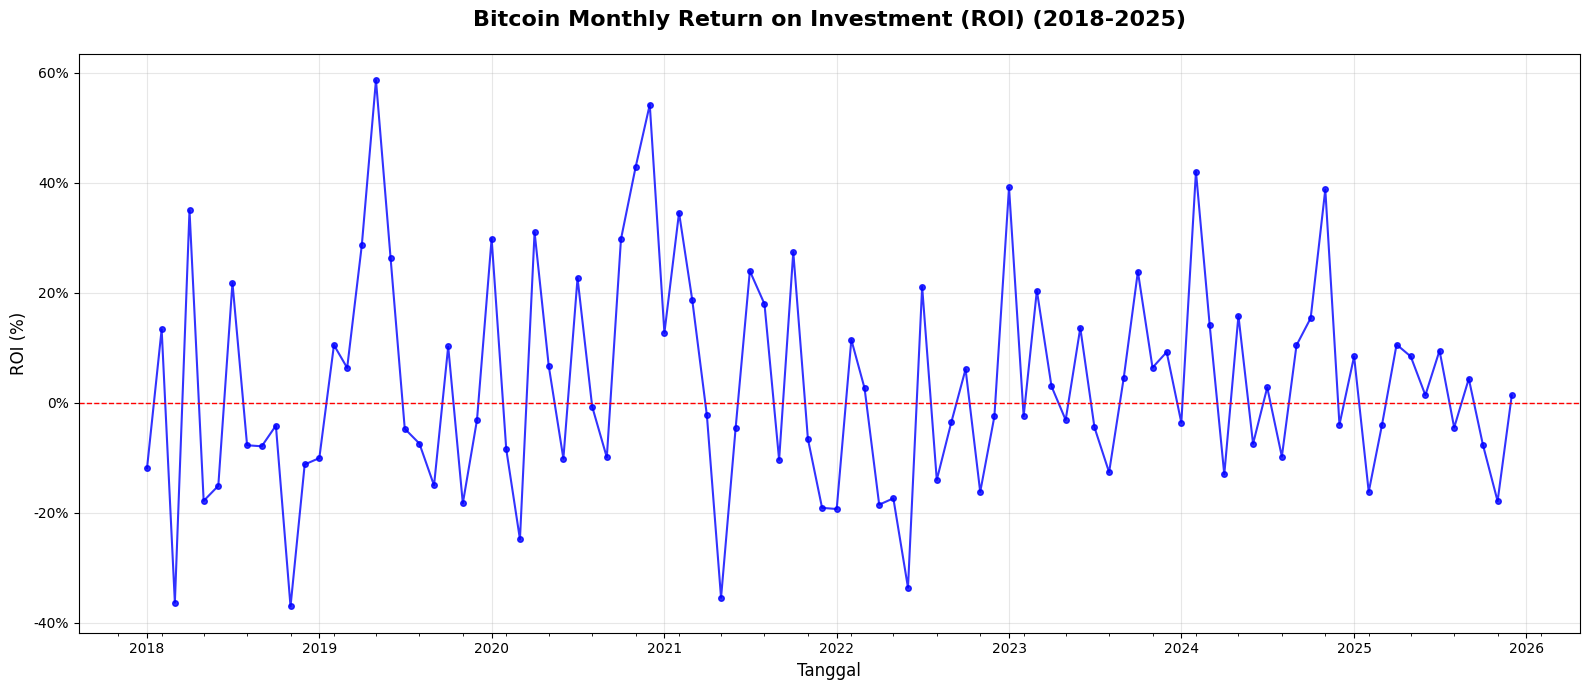

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# Pastikan kolom 'Month' adalah tipe datetime untuk plotting
df_monthly_roi['Month'] = pd.to_datetime(df_monthly_roi['Month'])

fig, ax = plt.subplots(figsize=(16, 7))
fig.patch.set_facecolor('white')

ax.plot(df_monthly_roi['Month'], df_monthly_roi['ROI (%)'],
        color='blue', linewidth=1.5, marker='o', markersize=4, alpha=0.8)

# Garis nol untuk referensi
ax.axhline(0, color='red', linestyle='--', linewidth=1)

ax.set_title('Bitcoin Monthly Return on Investment (ROI) (2018-2025)',
             fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Tanggal', fontsize=12)
ax.set_ylabel('ROI (%)', fontsize=12)
ax.grid(True, alpha=0.3)

# Format sumbu x agar menampilkan tahun dengan rapi
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_minor_locator(mdates.MonthLocator(interval=3))

# Menampilkan persentase pada sumbu y
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0f}%'))

plt.tight_layout()
plt.savefig('bitcoin_monthly_roi_plot.png', dpi=150, bbox_inches='tight')
plt.show()

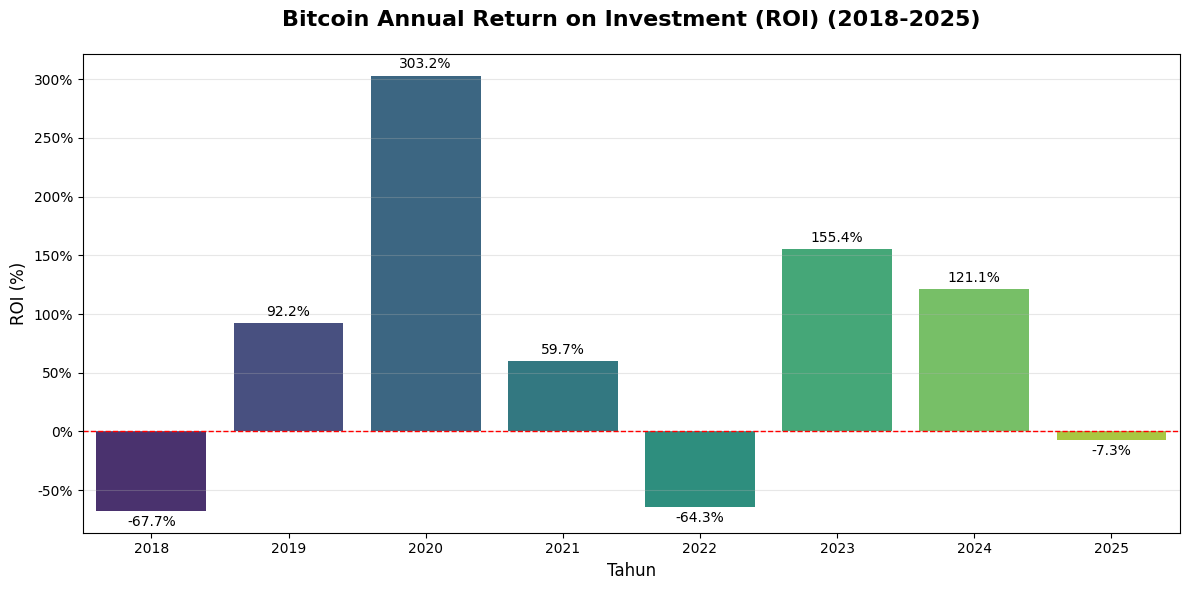

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Pastikan kolom 'Year' adalah string atau kategori untuk bar plot
df_annual_roi_for_plot = df_annual_roi.copy()
df_annual_roi_for_plot['Year_label'] = df_annual_roi_for_plot['Year'].astype(str).str.replace(' (Year Start to End)', '', regex=False)

fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor('white')

# Plot bar chart
sns.barplot(x='Year_label', y='ROI (%)', data=df_annual_roi_for_plot, ax=ax,
            palette=sns.color_palette('viridis', len(df_annual_roi_for_plot)))

# Garis nol untuk referensi
ax.axhline(0, color='red', linestyle='--', linewidth=1)

ax.set_title('Bitcoin Annual Return on Investment (ROI) (2018-2025)',
             fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Tahun', fontsize=12)
ax.set_ylabel('ROI (%)', fontsize=12)
ax.grid(axis='y', alpha=0.3)

# Menampilkan nilai persentase di atas bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='edge', padding=3, fontsize=10)

# Menampilkan persentase pada sumbu y
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0f}%'))

plt.tight_layout()
plt.savefig('bitcoin_annual_roi_plot.png', dpi=150, bbox_inches='tight')
plt.show()

MODEL TRANSFORMER


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import warnings
warnings.filterwarnings('ignore')


In [ ]:
def prepare_transformer_data(df, features_to_use, target_column_name, seq_length, forecast_horizon, test_size, val_size):

    # Ensure target_column_name is in features_to_use
    if target_column_name not in features_to_use:
        raise ValueError(f"Target column '{target_column_name}' must be in features_to_use.")

    data = df[features_to_use].values
    n_features = len(features_to_use)
    target_idx = features_to_use.index(target_column_name)

    # Scale data
    scaler = MinMaxScaler(feature_range=(0, 1))
    data_scaled = scaler.fit_transform(data)

    # Create sequences
    X, y = [], []
    for i in range(seq_length, len(data_scaled) - forecast_horizon + 1):
        X.append(data_scaled[i-seq_length:i])
        y.append(data_scaled[i + forecast_horizon - 1, target_idx]) # Predict target_idx at forecast_horizon steps ahead

    X, y = np.array(X), np.array(y)

    # Split into train, validation, test
    n_samples = len(X)
    test_split_idx = int(n_samples * (1 - test_size))
    val_split_idx = int(n_samples * (1 - test_size - val_size))

    X_train = X[:val_split_idx]
    y_train = y[:val_split_idx]

    X_val = X[val_split_idx:test_split_idx]
    y_val = y[val_split_idx:test_split_idx]

    X_test = X[test_split_idx:]
    y_test = y[test_split_idx:]

    # Convert to PyTorch tensors
    X_train = torch.FloatTensor(X_train)
    y_train = torch.FloatTensor(y_train)
    X_val = torch.FloatTensor(X_val)
    y_val = torch.FloatTensor(y_val)
    X_test = torch.FloatTensor(X_test)
    y_test = torch.FloatTensor(y_test)

    print(f"\nData shapes for Transformer:")
    print(f"X_train: {X_train.shape}")
    print(f"y_train: {y_train.shape}")
    print(f"X_val: {X_val.shape}")
    print(f"y_val: {y_val.shape}")
    print(f"X_test: {X_test.shape}")
    print(f"y_test: {y_test.shape}")

    return X_train, y_train, X_val, y_val, X_test, y_test, scaler, n_features

# Define the features and target for the Transformer model
transformer_features = ['rv_annualized_20d', 'rv_5d', 'rv_20d', 'realized_volatility_daily', 'log_return', 'Close']
transformer_target = 'rv_annualized_20d' # The column to predict

# Call prepare_transformer_data to see its output
# We use `df_rv` which contains the raw features, consistent with the LSTM model's input.
(X_train_trans, y_train_trans, X_val_trans, y_val_trans,
 X_test_trans, y_test_trans, transformer_scaler, input_dim_transformer) = prepare_transformer_data(
    df_rv,
    features_to_use=transformer_features,
    target_column_name=transformer_target,
    seq_length=60,
    forecast_horizon=1,
    test_size=0.1, # Using 10% for test
    val_size=0.1  # Using 10% for validation
)

print("\nExample of X_train_trans shape after calling prepare_transformer_data:")
print(X_train_trans.shape)
print("Example of y_train_trans shape after calling prepare_transformer_data:")
print(y_train_trans.shape)
print(f"Input Dimension for Transformer: {input_dim_transformer}")


Data shapes for Transformer:
X_train: torch.Size([2273, 60, 6])
y_train: torch.Size([2273])
X_val: torch.Size([284, 60, 6])
y_val: torch.Size([284])
X_test: torch.Size([285, 60, 6])
y_test: torch.Size([285])

Example of X_train_trans shape after calling prepare_transformer_data:
torch.Size([2273, 60, 6])
Example of y_train_trans shape after calling prepare_transformer_data:
torch.Size([2273])
Input Dimension for Transformer: 6


Using device: cpu

TRANSFORMER MODEL ARCHITECTURE
SimpleTransformer(
  (embedding): Linear(in_features=6, out_features=150, bias=True)
  (pos_encoder): PositionalEncoding(
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=150, out_features=150, bias=True)
        )
        (linear1): Linear(in_features=150, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=150, bias=True)
        (norm1): LayerNorm((150,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((150,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (decoder): Linear(in_features=150, out_features=1, bias=True

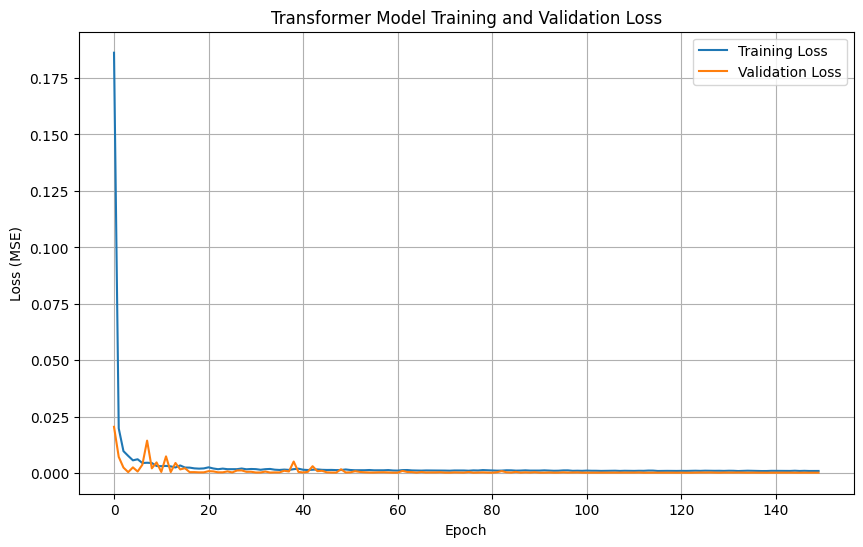

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np # Import numpy for np.log

# Check for GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- Definitions moved from new_cell_2 ---
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout=0.1, max_len=5000):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(p=dropout)

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0).transpose(0, 1)
        self.register_buffer('pe', pe)

    def forward(self, x):
        x = x + self.pe[:x.size(0), :]
        return self.dropout(x)

class SimpleTransformer(nn.Module):
    def __init__(self, input_dim, d_model, nhead, num_layers, dim_feedforward, dropout, forecast_horizon):
        super(SimpleTransformer, self).__init__()
        self.model_type = 'Transformer'
        self.input_dim = input_dim
        self.d_model = d_model
        self.forecast_horizon = forecast_horizon

        self.embedding = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model, dropout)
        encoder_layers = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True # Process batches first
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layers, num_layers)
        self.decoder = nn.Linear(d_model, forecast_horizon) # Output forecast_horizon values

    def forward(self, src):
        # src shape: (batch_size, sequence_length, input_dim)
        src = self.embedding(src) * np.sqrt(self.d_model)
        src = self.pos_encoder(src) # pos_encoder expects (seq_len, batch_size, d_model)

        output = self.transformer_encoder(src) # (batch_size, sequence_length, d_model)
        output = self.decoder(output[:, -1, :]) # Use the last output from the sequence for prediction
        return output

def train_model(model, train_loader, val_loader, epochs, lr, device, patience=10):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=patience//2, factor=0.5)

    train_losses = []
    val_losses = []
    # best_val_loss = float('inf')  # Removed early stopping logic
    # epochs_no_improve = 0

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs.squeeze(), batch_y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch_x_val, batch_y_val in val_loader:
                batch_x_val, batch_y_val = batch_x_val.to(device), batch_y_val.to(device)
                outputs_val = model(batch_x_val)
                loss_val = criterion(outputs_val.squeeze(), batch_y_val)
                val_loss += loss_val.item()
        val_loss = val_loss / len(val_loader)
        val_losses.append(val_loss)

        scheduler.step(val_loss)

        print(f'Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f}')

    return model, train_losses, val_losses
# --- End of definitions moved from new_cell_2 ---

# Hyperparameters for the Transformer model
d_model = 150
nhead = 6 # Changed from 4 to 6 to be divisible by d_model
num_layers = 3
dim_feedforward = 128
dropout = 0.1

# Instantiate the SimpleTransformer model
# input_dim_transformer was obtained from prepare_transformer_data in mtR6cYsxmpnY
model_transformer = SimpleTransformer(
    input_dim=input_dim_transformer,
    d_model=d_model,
    nhead=nhead,
    num_layers=num_layers,
    dim_feedforward=dim_feedforward,
    dropout=dropout,
    forecast_horizon=1 # We are predicting a single step ahead
).to(device)

print("\n" + "="*60)
print("TRANSFORMER MODEL ARCHITECTURE")
print("="*60)
print(model_transformer)

# Create DataLoader objects
batch_size = 32

train_dataset = TensorDataset(X_train_trans, y_train_trans)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = TensorDataset(X_val_trans, y_val_trans)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

# Define training parameters
epochs = 150
lr = 0.001
patience = 20

# Train the model
model_transformer, train_losses, val_losses = train_model(
    model_transformer, train_loader, val_loader,
    epochs=epochs, lr=lr, device=device, patience=patience
)

print("\nTransformer model training complete.")

# Plot training and validation loss
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Transformer Model Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import torch

def inverse_transform_transformer(scaler, y_scaled, target_idx, n_features):

    if len(y_scaled.shape) == 1:
        y_scaled = y_scaled.reshape(-1, 1)

    dummy_features = np.zeros((len(y_scaled), n_features))

    # Place the target column (y_scaled) into the correct position
    dummy_features[:, target_idx] = y_scaled.squeeze()

    # Inverse transform the whole array
    y_inv = scaler.inverse_transform(dummy_features)

    # Return only the target column (which was at target_idx)
    return y_inv[:, target_idx]


# Set the model to evaluation mode
model_transformer.eval()

# Get predictions on the test set
with torch.no_grad():
    y_pred_trans_scaled = model_transformer(X_test_trans.to(device)).cpu().numpy()

# Get the index of the target column ('rv_annualized_20d') within the transformer_features list
transformer_target_idx = transformer_features.index(transformer_target)

# Inverse transform actual and predicted values
y_test_trans_actual = inverse_transform_transformer(
    transformer_scaler, y_test_trans.cpu().numpy(),
    target_idx=transformer_target_idx,
    n_features=input_dim_transformer
)
y_pred_trans_actual = inverse_transform_transformer(
    transformer_scaler, y_pred_trans_scaled,
    target_idx=transformer_target_idx,
    n_features=input_dim_transformer
)

# Calculate metrics
rmse_trans = np.sqrt(mean_squared_error(y_test_trans_actual, y_pred_trans_actual))
mae_trans = mean_absolute_error(y_test_trans_actual, y_pred_trans_actual)
mape_trans = np.mean(np.abs((y_test_trans_actual - y_pred_trans_actual) / y_test_trans_actual)) * 100

print("\n" + "="*60)
print("TRANSFORMER MODEL EVALUATION RESULTS")
print("="*60)
print(f"RMSE: {rmse_trans:.6f}")
print(f"MAE: {mae_trans:.6f}")
print(f"MAPE: {mape_trans:.2f}%")



TRANSFORMER MODEL EVALUATION RESULTS
RMSE: 0.037671
MAE: 0.029676
MAPE: 10.97%


In [ ]:
def forecast_future_transformer(model, last_sequence_scaled, scaler, target_idx, n_features, days_ahead=90):

    predictions = []
    # Ensure current_sequence is a numpy array for manipulation, then convert back to tensor for model input
    current_sequence_np = last_sequence_scaled.clone().detach().cpu().numpy()

    for _ in range(days_ahead):
        # Convert current_sequence to tensor and add batch dimension
        input_tensor = torch.FloatTensor(current_sequence_np).unsqueeze(0).to(device)

        # Predict next step
        model.eval() # Set model to evaluation mode
        with torch.no_grad():
            next_pred_scaled = model(input_tensor).cpu().numpy()[0, 0] # Get the single predicted value

        predictions.append(next_pred_scaled)

        # Update the sequence for the next prediction
        next_features_scaled = np.zeros(n_features)
        next_features_scaled[target_idx] = next_pred_scaled

        # This is a common simplification for single-output time series forecasting.
        for j in range(n_features):
            if j != target_idx:
                next_features_scaled[j] = current_sequence_np[-1, j]

        # Roll the sequence and add the new predicted row
        current_sequence_np = np.roll(current_sequence_np, -1, axis=0) # Shift all rows up
        current_sequence_np[-1] = next_features_scaled # Place the new row at the end

    # Inverse transform the predictions
    predictions = np.array(predictions).reshape(-1, 1)
    predictions_original = inverse_transform_transformer(scaler, predictions, target_idx, n_features)

    return predictions_original

# Get the last sequence from the test set for forecasting
last_sequence_trans = X_test_trans[-1] # This is already a tensor

# Forecast next 90 days
transformer_forecast_90d = forecast_future_transformer(
    model_transformer, last_sequence_trans, transformer_scaler,
    target_idx=transformer_target_idx, n_features=input_dim_transformer, days_ahead=90
)

# Create forecast dates
# df_rv is the original df containing 'Date' column
last_date_in_data = df_rv['Date'].iloc[-1]
transformer_forecast_dates = pd.date_range(start=last_date_in_data, periods=91, freq='D')[1:]

print(f"Forecast generated for {len(transformer_forecast_90d)} days starting from {transformer_forecast_dates[0].strftime('%Y-%m-%d')}")

Forecast generated for 90 days starting from 2026-01-01


Now, let's create a comprehensive plot to visualize the historical realized volatility (winsorized), the Transformer model's predictions on the test set, and the 60-day future forecast.

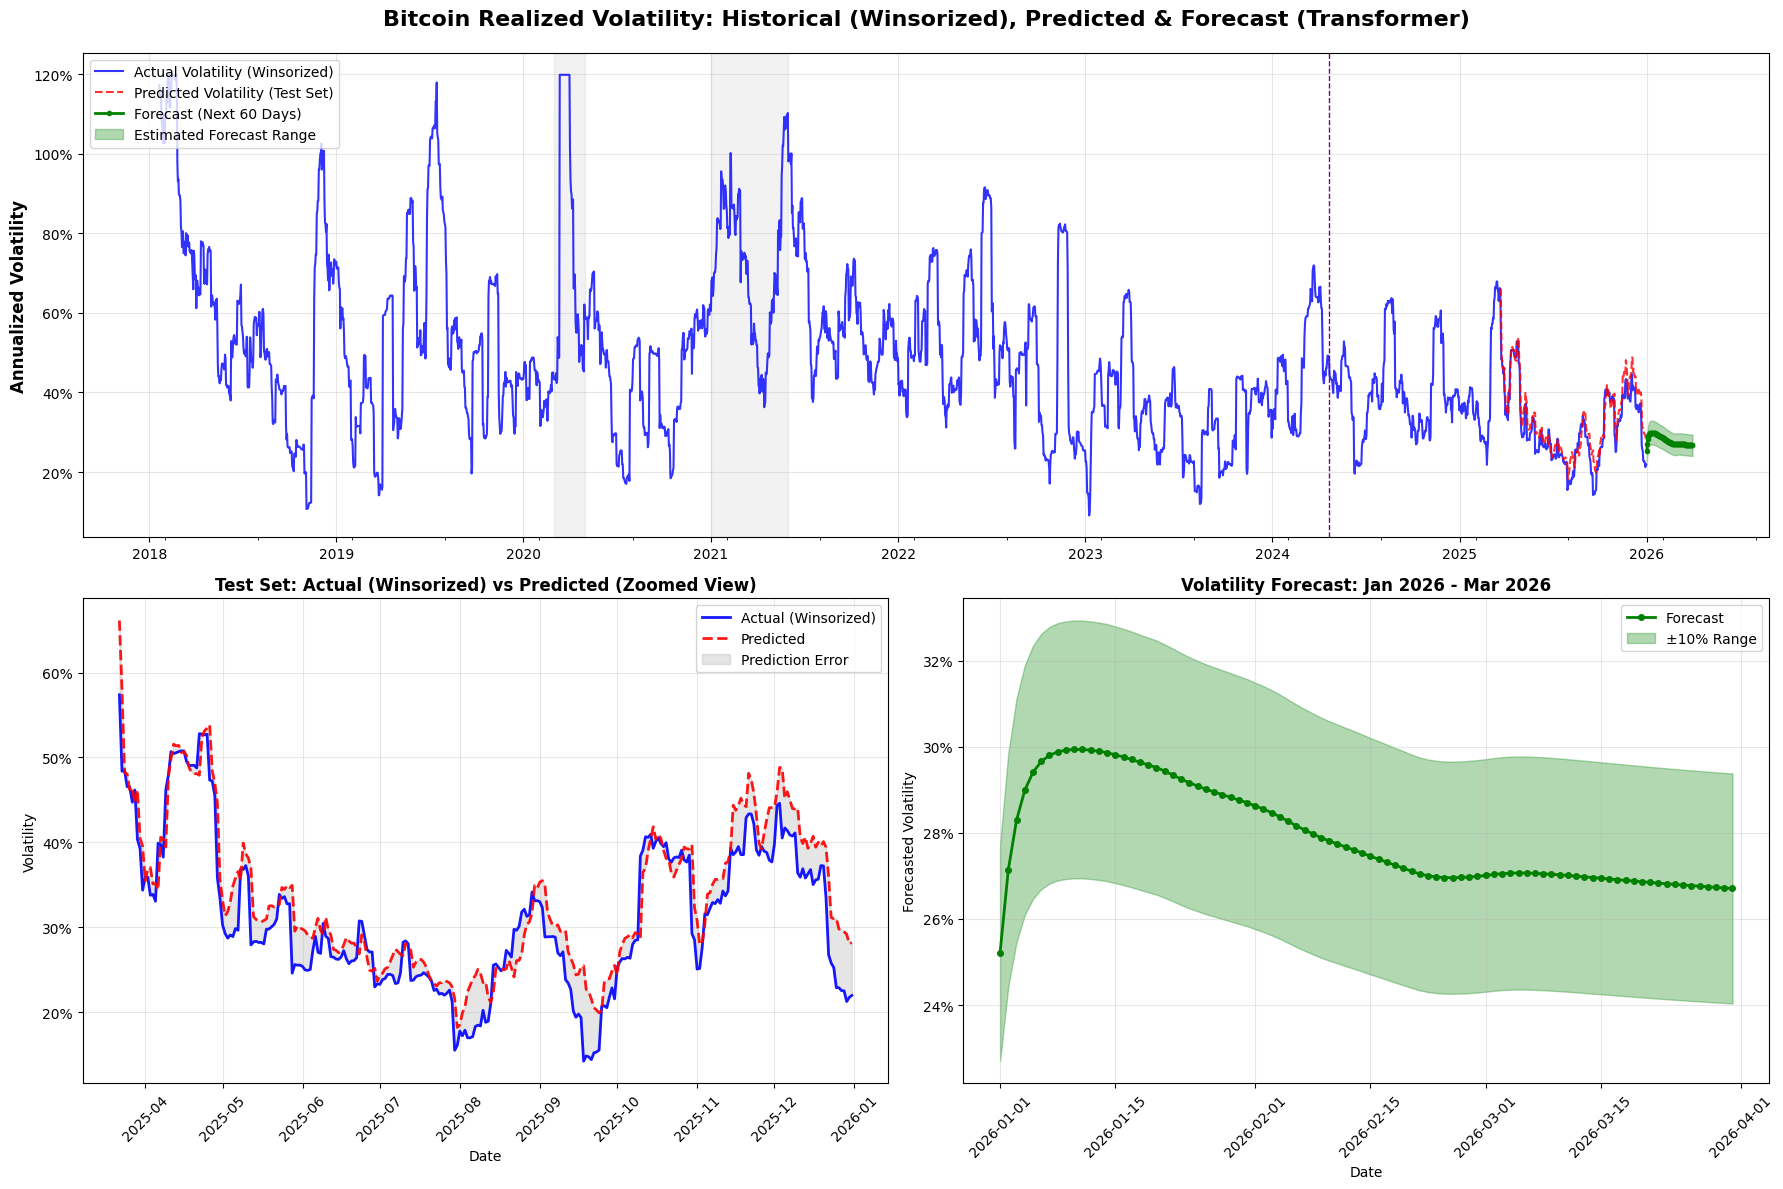

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def plot_full_transformer_forecast(
    df_actual_source, y_test_actual, y_pred_actual, forecast_data, forecast_dates,
    sequence_length=90, test_size=0.1, val_size=0.1
):

    # Calculate indices for the test set from the original df_actual_source
    total_samples_in_Xy = len(df_actual_source) - sequence_length

    # Number of samples in X (sequences after create_sequences)
    n_sequences = len(y_test_actual) + len(X_train_trans) + len(X_val_trans)

    test_start_idx_in_df_source = sequence_length + len(X_train_trans) + len(X_val_trans)

    # Get the dates corresponding to the test set predictions
    test_dates = df_actual_source['Date'].iloc[test_start_idx_in_df_source : test_start_idx_in_df_source + len(y_test_actual)].values

    # Get the corresponding winsorized actual values from df_actual_source for the test period.
    actual_winsorized_test_data = df_actual_source['rv_annualized_20d_winsorized'].iloc[test_start_idx_in_df_source : test_start_idx_in_df_source + len(y_test_actual)].values

    # Create figure with 3 subplots
    fig = plt.figure(figsize=(18, 12))

    # Main plot: Full timeline (Historical (Winsorized) + Predicted Test + Forecast)
    ax1 = plt.subplot(2, 1, 1)

    # Plot historical volatility (2018-2025) using the winsorized dataset for actuals
    ax1.plot(df_actual_source['Date'], df_actual_source['rv_annualized_20d_winsorized'],
             color='blue', linewidth=1.5, alpha=0.8, label='Actual Volatility (Winsorized)')

    # Plot predictions on test set (these are non-winsorized predictions from the model)
    ax1.plot(test_dates, y_pred_actual,
             color='red', linewidth=1.5, linestyle='--', alpha=0.8, label='Predicted Volatility (Test Set)')

    # Plot forecast
    ax1.plot(forecast_dates, forecast_data,
             color='green', linewidth=2, marker='o', markersize=3, label='Forecast (Next 60 Days)')

    # Fill forecast area (simple ±10% confidence band for visualization)
    ax1.fill_between(forecast_dates, forecast_data * 0.9, forecast_data * 1.1,
                     alpha=0.3, color='green', label='Estimated Forecast Range')

    # Formatting for ax1
    ax1.set_title('Bitcoin Realized Volatility: Historical (Winsorized), Predicted & Forecast (Transformer)',
                  fontsize=16, fontweight='bold', pad=20)
    ax1.set_ylabel('Annualized Volatility', fontsize=12, fontweight='bold')
    ax1.legend(loc='upper left', fontsize=10)
    ax1.grid(True, alpha=0.3)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax1.xaxis.set_major_locator(mdates.YearLocator())
    ax1.xaxis.set_minor_locator(mdates.MonthLocator(interval=6))
    ax1.tick_params(axis='x', rotation=0)

    # Highlight key events
    ax1.axvspan(pd.to_datetime('2020-03-01'), pd.to_datetime('2020-04-30'),
                alpha=0.1, color='gray', label='COVID-19 Crash')
    ax1.axvspan(pd.to_datetime('2021-01-01'), pd.to_datetime('2021-05-31'),
                alpha=0.1, color='gray', label='Bull Run')
    ax1.axvline(pd.to_datetime('2024-04-20'), color='purple', linestyle='--', linewidth=1, label='Halving 2024')

    # Second subplot: Test set comparison (Actual winsorized vs Predicted non-winsorized)
    ax2 = plt.subplot(2, 2, 3)

    ax2.plot(test_dates, actual_winsorized_test_data,
             color='blue', linewidth=2, label='Actual (Winsorized)', alpha=0.9)
    ax2.plot(test_dates, y_pred_actual,
             color='red', linewidth=2, linestyle='--', label='Predicted', alpha=0.9)
    ax2.fill_between(test_dates, actual_winsorized_test_data, y_pred_actual, alpha=0.2, color='gray', label='Prediction Error')
    ax2.set_title('Test Set: Actual (Winsorized) vs Predicted (Zoomed View)', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Date')
    ax2.set_ylabel('Volatility')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax2.tick_params(axis='x', rotation=45)

    # Third subplot: Forecast details
    ax3 = plt.subplot(2, 2, 4)

    ax3.plot(forecast_dates, forecast_data,
             color='green', linewidth=2, marker='o', markersize=4, label='Forecast')
    ax3.fill_between(forecast_dates, forecast_data * 0.9, forecast_data * 1.1,
                     alpha=0.3, color='green', label='±10% Range')
    ax3.set_title(f'Volatility Forecast: {forecast_dates[0].strftime("%b %Y")} - {forecast_dates[-1].strftime("%b %Y")}',
                  fontsize=12, fontweight='bold')
    ax3.set_xlabel('Date')
    ax3.set_ylabel('Forecasted Volatility')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax3.tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.savefig('bitcoin_volatility_full_forecast_transformer.png', dpi=150, bbox_inches='tight')
    plt.show()

# Call the plotting function with Transformer results
plot_full_transformer_forecast(
    df_rv_winsorized, y_test_trans_actual, y_pred_trans_actual,
    transformer_forecast_90d, transformer_forecast_dates,
    sequence_length=sequence_length,
    test_size=0.1, val_size=0.1
)


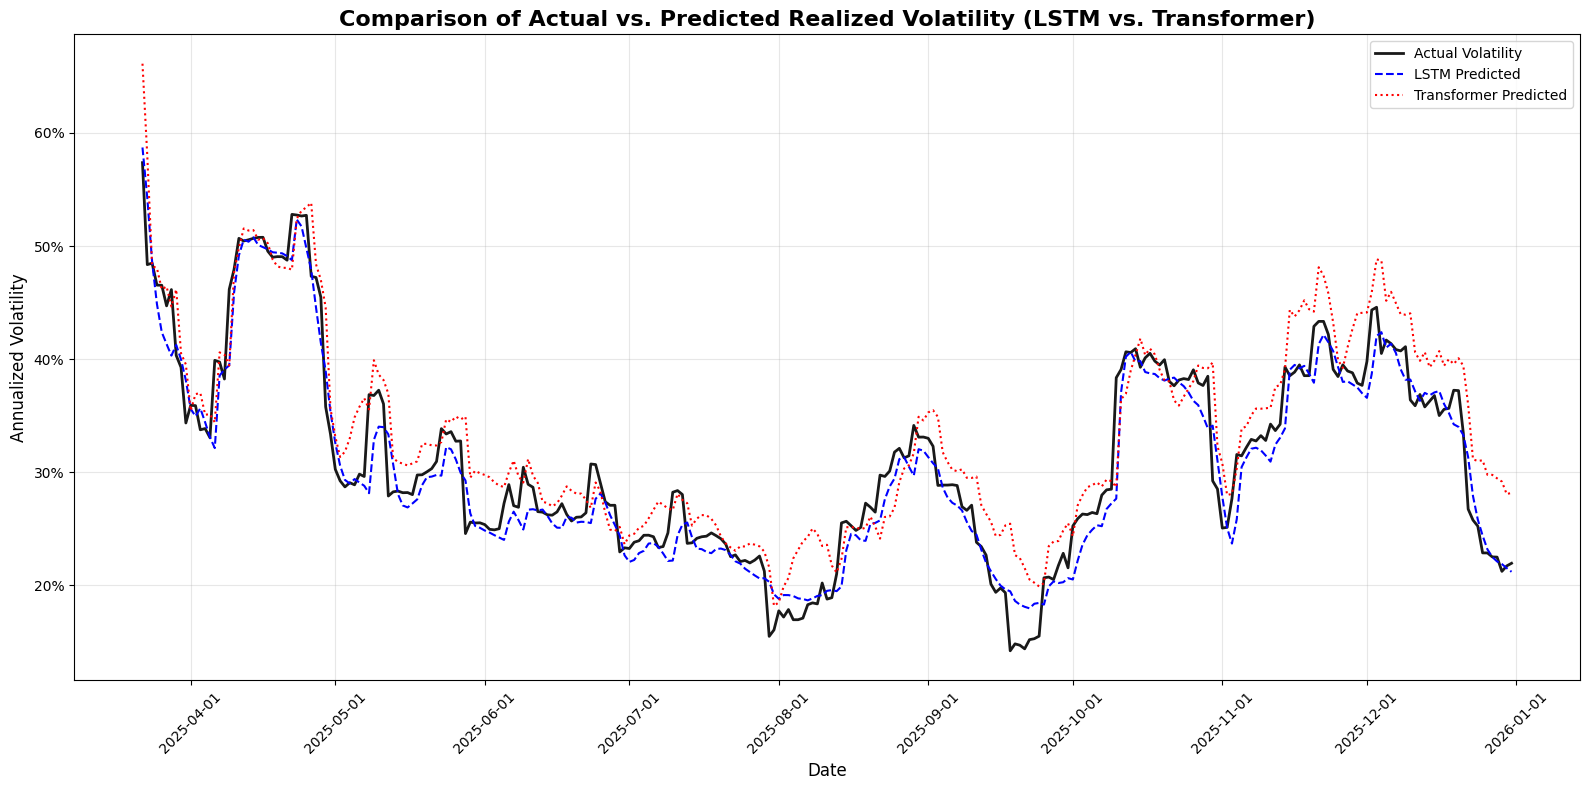

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def plot_model_comparison(df_source, y_test_actual_lstm, y_pred_actual_lstm,
                          y_test_actual_trans, y_pred_actual_trans,
                          sequence_length=60):

    total_samples = len(df_rv) - sequence_length
    train_ratio = 0.8
    val_ratio = 0.1

    train_size_samples = int(total_samples * train_ratio)
    val_size_samples = int(total_samples * val_ratio)

    # Start index of the test set *within the original df_rv*
    test_start_idx_in_df_source = sequence_length + train_size_samples + val_size_samples

    # Get the dates corresponding to the test set for plotting
    # Ensure the length matches y_test_actual_lstm
    test_dates = df_rv['Date'].iloc[test_start_idx_in_df_source : test_start_idx_in_df_source + len(y_test_actual_lstm)].values

    # Align lengths to avoid potential mismatches, though they should be consistent
    min_len = min(len(test_dates), len(y_test_actual_lstm), len(y_pred_actual_lstm), len(y_pred_actual_trans))
    test_dates_trimmed = test_dates[:min_len]
    y_test_actual_lstm_trimmed = y_test_actual_lstm[:min_len]
    y_pred_actual_lstm_trimmed = y_pred_actual_lstm[:min_len]
    y_pred_actual_trans_trimmed = y_pred_actual_trans[:min_len]

    fig, ax = plt.subplots(figsize=(16, 8))
    fig.patch.set_facecolor('white')

    ax.plot(test_dates_trimmed, y_test_actual_lstm_trimmed, label='Actual Volatility', color='black', linewidth=2, alpha=0.9)
    ax.plot(test_dates_trimmed, y_pred_actual_lstm_trimmed, label='LSTM Predicted', color='blue', linestyle='--', linewidth=1.5)
    ax.plot(test_dates_trimmed, y_pred_actual_trans_trimmed, label='Transformer Predicted', color='red', linestyle=':', linewidth=1.5)

    ax.set_title('Comparison of Actual vs. Predicted Realized Volatility (LSTM vs. Transformer)', fontsize=16, fontweight='bold')
    ax.set_xlabel('Date', fontsize=12)
    ax.set_ylabel('Annualized Volatility', fontsize=12)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    ax.tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.savefig('model_comparison_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
    plt.show()

# Call the comparison plotting function
plot_model_comparison(df_rv, y_test_actual, y_pred_actual, y_test_trans_actual, y_pred_trans_actual)


In [ ]:
print("="*60)
print("MODEL EVALUATION COMPARISON (LSTM vs Transformer)")
print("="*60)

print("\nLSTM Model:")
print(f"  RMSE: {rmse:.6f}")
print(f"  MAE: {mae:.6f}")
print(f"  MAPE: {mape:.2f}%")

print("\nTransformer Model:")
print(f"  RMSE: {rmse_trans:.6f}")
print(f"  MAE: {mae_trans:.6f}")
print(f"  MAPE: {mape_trans:.2f}%")

MODEL EVALUATION COMPARISON (LSTM vs Transformer)

LSTM Model:
  RMSE: 0.023407
  MAE: 0.016903
  MAPE: 5.84%

Transformer Model:
  RMSE: 0.037671
  MAE: 0.029676
  MAPE: 10.97%


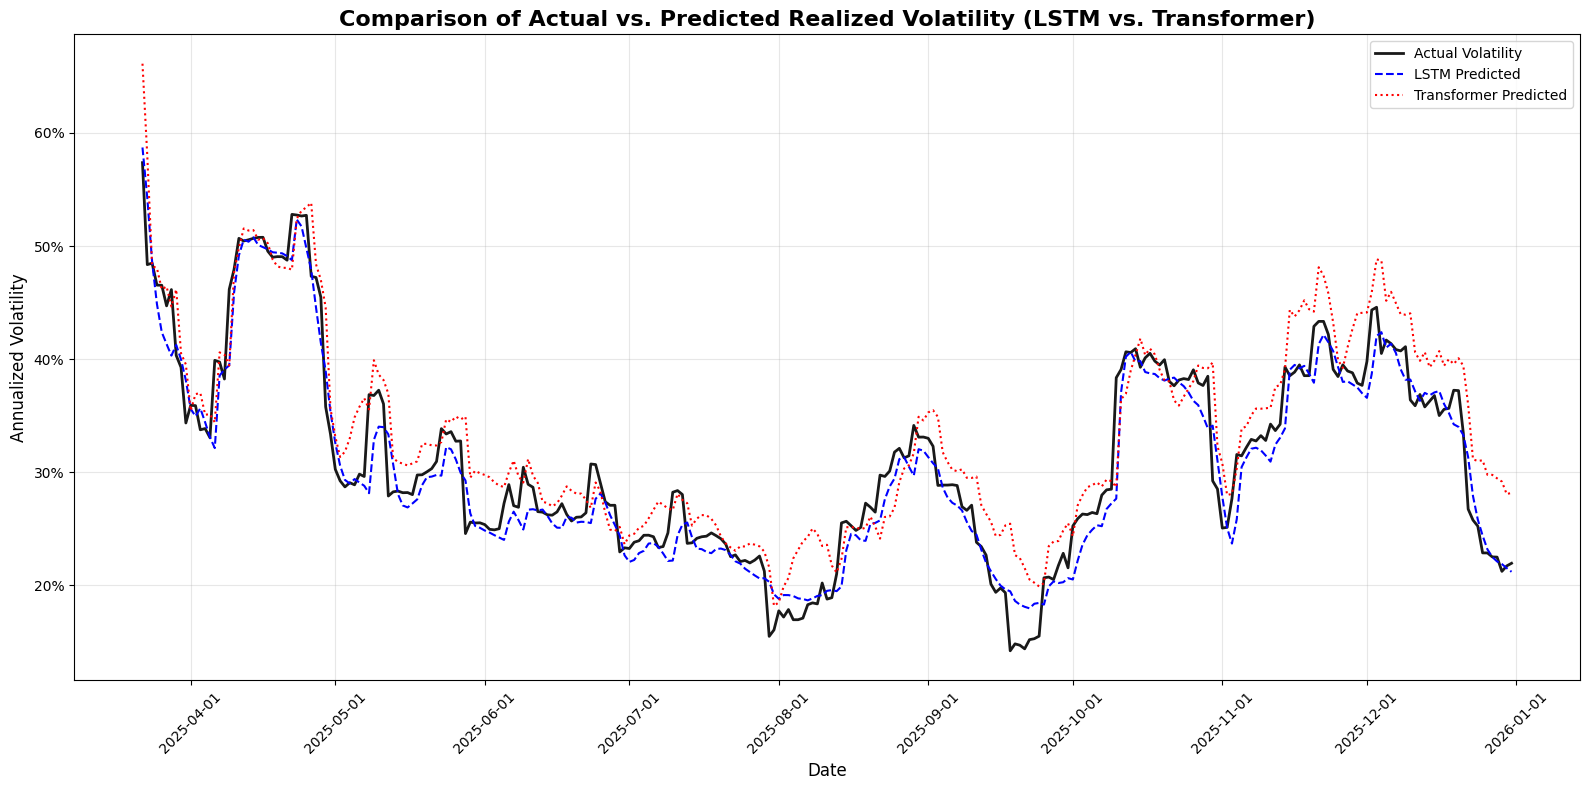

In [ ]:
plot_model_comparison(df_rv, y_test_actual, y_pred_actual, y_test_trans_actual, y_pred_trans_actual, sequence_length=sequence_length)

In [ ]:
print("\n" + "="*60)
print("LSTM MODEL EVALUATION RESULTS")
print("="*60)
print(f"RMSE: {rmse:.6f}")
print(f"MAE: {mae:.6f}")
print(f"MAPE: {mape:.2f}%")


LSTM MODEL EVALUATION RESULTS
RMSE: 0.023407
MAE: 0.016903
MAPE: 5.84%


In [ ]:
print("\n" + "="*60)
print("SAMPLE FORECASTED VOLATILITY (LSTM vs Transformer)")
print("="*60)

# Combine LSTM forecast
df_lstm_forecast = pd.DataFrame({
    'Date': forecast_dates[:len(transformer_forecast_90d)], # From LSTM forecasting (90 days), trimmed to match Transformer's 60 days
    'LSTM_Forecast': forecast_90d[:len(transformer_forecast_90d)] # Trim to 60 days to match Transformer
})

# Combine Transformer forecast
df_transformer_forecast = pd.DataFrame({
    'Date': transformer_forecast_dates,
    'Transformer_Forecast': transformer_forecast_90d
})

# Merge them for comparison
df_combined_forecast = pd.merge(df_lstm_forecast, df_transformer_forecast, on='Date', how='inner')

print("\nFirst 10 days of forecasted volatility:")
display(df_combined_forecast.head(10).style.format({
    'LSTM_Forecast': '{:.2%}',
    'Transformer_Forecast': '{:.2%}'
}))

print("\nLast 10 days of forecasted volatility:")
display(df_combined_forecast.tail(10).style.format({
    'LSTM_Forecast': '{:.2%}',
    'Transformer_Forecast': '{:.2%}'
}))


SAMPLE FORECASTED VOLATILITY (LSTM vs Transformer)

First 10 days of forecasted volatility:


,Date,LSTM_Forecast,Transformer_Forecast
0,2026-01-01 00:00:00,21.21%,25.22%
1,2026-01-02 00:00:00,20.79%,27.14%
2,2026-01-03 00:00:00,20.44%,28.29%
3,2026-01-04 00:00:00,20.11%,28.99%
4,2026-01-05 00:00:00,19.84%,29.41%
5,2026-01-06 00:00:00,19.65%,29.66%
6,2026-01-07 00:00:00,19.51%,29.80%
7,2026-01-08 00:00:00,19.43%,29.88%
8,2026-01-09 00:00:00,19.39%,29.92%
9,2026-01-10 00:00:00,19.40%,29.94%



Last 10 days of forecasted volatility:


,Date,LSTM_Forecast,Transformer_Forecast
80,2026-03-22 00:00:00,19.71%,26.83%
81,2026-03-23 00:00:00,19.71%,26.82%
82,2026-03-24 00:00:00,19.71%,26.80%
83,2026-03-25 00:00:00,19.71%,26.79%
84,2026-03-26 00:00:00,19.71%,26.77%
85,2026-03-27 00:00:00,19.71%,26.76%
86,2026-03-28 00:00:00,19.71%,26.75%
87,2026-03-29 00:00:00,19.71%,26.73%
88,2026-03-30 00:00:00,19.71%,26.72%
89,2026-03-31 00:00:00,19.71%,26.71%
